<a href="https://colab.research.google.com/github/ApexRadix/Beyond-BERT/blob/main/LLM_Keypolicy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# PHASE 1
# Local Input and Computation of Token
# ============================================================
#
# Block-diagram flow:
#
# User (Closed Domain)
#        ↓
# Generate Request Token
#        ↓
# Simplification of I/P
#        ↓
# EHR - Local Information Gathering
#        ↓
# Local-phase: Knowledge Graph
#
# Dataset:
# /content/Phase1_Synthetic_EHR_Dataset_10000.csv
#
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import re
import time
from collections import Counter, defaultdict

# NetworkX is used to construct the local knowledge graph
import networkx as nx

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


# ------------------------------------------------------------
# 2. LOAD THE SYNTHETIC EHR DATASET
# ------------------------------------------------------------

DATA_PATH = "/content/Phase1_Synthetic_EHR_Dataset_10000.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())


# ------------------------------------------------------------
# 3. BASIC DATASET INSPECTION
# ------------------------------------------------------------

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of unique diagnoses:",
      df["diagnosis"].nunique())

print("\nNumber of disease categories:",
      df["disease_category"].nunique())


# ============================================================
# PHASE 1 - BLOCK 1
# USER (CLOSED DOMAIN)
# ============================================================
#
# In the diagram, the process begins with a request from the
# user inside the closed/private domain.
#
# For the experiment, we use one query from the synthetic
# dataset as the incoming user request.
# ============================================================


# Select one example request
user_query = df.loc[0, "user_query"]

print("\n==============================================")
print("PHASE 1 - USER REQUEST")
print("==============================================")

print("User query:")
print(user_query)


# ============================================================
# PHASE 1 - BLOCK 2
# GENERATE REQUEST TOKEN
# ============================================================
#
# The purpose here is to convert the natural-language request
# into a compact token representation.
#
# We keep the token-generation procedure deterministic so that
# execution time can be measured reproducibly.
# ============================================================


def generate_request_token(query):
    """
    Convert a user query into a basic request-token sequence.

    Processing:
    1. Convert to lowercase
    2. Remove punctuation
    3. Split into words
    4. Remove common stop words
    5. Convert remaining terms to uppercase
    """

    # Common stop words for the experimental tokenization stage
    stop_words = {
        "find", "ehr", "records", "with", "and",
        "for", "the", "of", "to", "patients",
        "patient", "showing", "relevant", "clinical",
        "information", "related", "search", "locate"
    }

    # Convert query to lowercase
    text = query.lower()

    # Remove punctuation
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Split into individual words
    words = text.split()

    # Remove stop words
    tokens = [
        word for word in words
        if word not in stop_words
    ]

    # Convert tokens to uppercase
    tokens = [token.upper() for token in tokens]

    return tokens


# Measure request-token generation time
start_token = time.perf_counter()

request_tokens = generate_request_token(user_query)

token_generation_time = time.perf_counter() - start_token


print("\n==============================================")
print("REQUEST TOKEN")
print("==============================================")

print("Generated tokens:")
print(request_tokens)

print("\nToken count:", len(request_tokens))

print(
    "Token generation time: "
    f"{token_generation_time:.6f} seconds"
)


# ============================================================
# PHASE 1 - BLOCK 3
# SIMPLIFICATION OF INPUT
# ============================================================
#
# The diagram explicitly contains the "Simplification of I/P"
# block.
#
# Here we create a normalized form of the request that can be
# compared with the local EHR information.
# ============================================================


def simplify_input(query):
    """
    Simplify the user input for local EHR matching.

    Steps:
    1. Lowercase
    2. Remove punctuation
    3. Normalize whitespace
    4. Remove common request-oriented words
    """

    # Words that describe the request operation rather than
    # the clinical information itself
    request_words = {
        "find", "retrieve", "search", "locate",
        "records", "record", "patients", "patient",
        "information", "related", "relevant",
        "clinical", "ehr", "showing", "with",
        "for", "the", "of", "to", "and"
    }

    text = query.lower()

    # Remove punctuation
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Normalize multiple spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Split into words
    words = text.split()

    # Remove request-specific terms
    clinical_terms = [
        word for word in words
        if word not in request_words
    ]

    # Reconstruct simplified query
    simplified_query = " ".join(clinical_terms)

    return simplified_query


# Measure simplification time
start_simplification = time.perf_counter()

simplified_query = simplify_input(user_query)

input_simplification_time = (
    time.perf_counter() - start_simplification
)


print("\n==============================================")
print("SIMPLIFIED INPUT")
print("==============================================")

print("Original query:")
print(user_query)

print("\nSimplified query:")
print(simplified_query)

print(
    "\nInput simplification time: "
    f"{input_simplification_time:.6f} seconds"
)


# ============================================================
# PHASE 1 - BLOCK 4
# EHR LOCAL INFORMATION GATHERING
# ============================================================
#
# No external server or external LLM is used here.
#
# The purpose is to search the local EHR dataset using the
# simplified request.
# ============================================================


def local_ehr_search(dataset, query):
    """
    Search the local EHR dataset using the simplified query.

    Matching is performed against:
    - symptoms
    - diagnosis
    - disease category
    - medical history
    - medications
    - clinical notes
    """

    query_terms = query.lower().split()

    # Convert relevant EHR fields into a searchable text field
    search_columns = [
        "symptoms",
        "diagnosis",
        "disease_category",
        "medical_history",
        "medications",
        "clinical_notes"
    ]

    # Combine clinical information into one searchable string
    searchable_text = (
        dataset[search_columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
        .str.lower()
    )

    # Create an initial boolean mask
    match_mask = pd.Series(False, index=dataset.index)

    # Match each query term
    for term in query_terms:
        if len(term.strip()) == 0:
            continue

        term_mask = searchable_text.str.contains(
            re.escape(term),
            regex=True,
            na=False
        )

        match_mask = match_mask | term_mask

    results = dataset.loc[match_mask].copy()

    return results


# Measure local EHR gathering time
start_local_search = time.perf_counter()

local_results = local_ehr_search(
    df,
    simplified_query
)

local_ehr_gathering_time = (
    time.perf_counter() - start_local_search
)


print("\n==============================================")
print("LOCAL EHR INFORMATION GATHERING")
print("==============================================")

print(
    "Number of local matching records:",
    len(local_results)
)

print(
    "Local EHR gathering time: "
    f"{local_ehr_gathering_time:.6f} seconds"
)

print("\nSample retrieved local information:")

display(
    local_results[
        [
            "record_id",
            "patient_id",
            "symptoms",
            "diagnosis",
            "disease_category",
            "medications"
        ]
    ].head(10)
)


# ============================================================
# PHASE 1 - BLOCK 5
# LOCAL-PHASE KNOWLEDGE GRAPH
# ============================================================
#
# The diagram identifies a local-phase knowledge graph.
#
# We construct the graph from the locally gathered EHR
# information.
#
# Example:
#
# Patient → has_symptom → Fever
# Patient → diagnosed_with → Pneumonia
# Patient → takes → Medication
# Patient → belongs_to → Disease Category
#
# ============================================================


def build_local_knowledge_graph(ehr_records):
    """
    Build a local EHR knowledge graph.

    Nodes:
        Patient
        Symptom
        Diagnosis
        Disease Category
        Medication

    Edges:
        HAS_SYMPTOM
        DIAGNOSED_WITH
        BELONGS_TO
        TAKES
    """

    graph = nx.MultiDiGraph()

    for _, row in ehr_records.iterrows():

        patient = f"Patient:{row['patient_id']}"
        diagnosis = f"Diagnosis:{row['diagnosis']}"
        category = f"Category:{row['disease_category']}"
        medication = f"Medication:{row['medications']}"

        # Add patient node
        graph.add_node(
            patient,
            node_type="Patient"
        )

        # Add diagnosis node and relationship
        graph.add_node(
            diagnosis,
            node_type="Diagnosis"
        )

        graph.add_edge(
            patient,
            diagnosis,
            relation="DIAGNOSED_WITH"
        )

        # Add category node and relationship
        graph.add_node(
            category,
            node_type="Disease_Category"
        )

        graph.add_edge(
            patient,
            category,
            relation="BELONGS_TO"
        )

        # Add medication node and relationship
        graph.add_node(
            medication,
            node_type="Medication"
        )

        graph.add_edge(
            patient,
            medication,
            relation="TAKES"
        )

        # Process symptoms
        symptoms = str(row["symptoms"]).split(";")

        for symptom in symptoms:

            symptom = symptom.strip()

            if symptom == "":
                continue

            symptom_node = f"Symptom:{symptom}"

            graph.add_node(
                symptom_node,
                node_type="Symptom"
            )

            graph.add_edge(
                patient,
                symptom_node,
                relation="HAS_SYMPTOM"
            )

    return graph


# Measure local knowledge-graph construction time
start_kg = time.perf_counter()

local_kg = build_local_knowledge_graph(
    local_results
)

local_kg_construction_time = (
    time.perf_counter() - start_kg
)


print("\n==============================================")
print("LOCAL KNOWLEDGE GRAPH")
print("==============================================")

print(
    "Number of graph nodes:",
    local_kg.number_of_nodes()
)

print(
    "Number of graph edges:",
    local_kg.number_of_edges()
)

print(
    "Knowledge-graph construction time: "
    f"{local_kg_construction_time:.6f} seconds"
)


# ============================================================
# 6. KNOWLEDGE GRAPH NODE-TYPE SUMMARY
# ============================================================

node_type_counts = Counter()

for node, attributes in local_kg.nodes(data=True):
    node_type = attributes.get("node_type", "Unknown")
    node_type_counts[node_type] += 1


print("\nNode type distribution:")
for node_type, count in node_type_counts.items():
    print(f"{node_type}: {count}")


# ============================================================
# 7. KNOWLEDGE GRAPH RELATIONSHIP SUMMARY
# ============================================================

relation_counts = Counter()

for _, _, attributes in local_kg.edges(data=True):
    relation = attributes.get("relation", "Unknown")
    relation_counts[relation] += 1


print("\nRelationship distribution:")
for relation, count in relation_counts.items():
    print(f"{relation}: {count}")


# ============================================================
# 8. PHASE 1 COMPUTATIONAL RESULTS
# ============================================================
#
# These times correspond directly to the computational blocks
# in Phase 1.
# ============================================================


phase1_total_time = (
    token_generation_time
    + input_simplification_time
    + local_ehr_gathering_time
    + local_kg_construction_time
)


phase1_results = pd.DataFrame({
    "Metric": [
        "Token Generation Time",
        "Input Simplification Time",
        "Local EHR Gathering Time",
        "Local KG Construction Time",
        "Total Phase 1 Computation Time"
    ],
    "Time_seconds": [
        token_generation_time,
        input_simplification_time,
        local_ehr_gathering_time,
        local_kg_construction_time,
        phase1_total_time
    ]
})


print("\n==============================================")
print("PHASE 1 COMPUTATIONAL RESULTS")
print("==============================================")

display(phase1_results)


# ============================================================
# 9. PHASE 1 SUMMARY
# ============================================================

print("\n==============================================")
print("PHASE 1 SUMMARY")
print("==============================================")

print("User Request:")
print(user_query)

print("\nGenerated Request Tokens:")
print(request_tokens)

print("\nSimplified Input:")
print(simplified_query)

print(
    "\nLocal EHR Records Gathered:",
    len(local_results)
)

print(
    "Local Knowledge Graph Nodes:",
    local_kg.number_of_nodes()
)

print(
    "Local Knowledge Graph Edges:",
    local_kg.number_of_edges()
)

print(
    "Total Phase 1 Computation Time:",
    f"{phase1_total_time:.6f} seconds"
)


# ============================================================
# 10. SAVE PHASE 1 RESULTS
# ============================================================
#
# These files can later be used for the Phase 1 graphs and
# for comparison with Phase 2 and Phase 3.
# ============================================================

phase1_results.to_csv(
    "/content/Phase1_Computation_Results.csv",
    index=False
)

local_results.to_csv(
    "/content/Phase1_Local_EHR_Retrieval_Results.csv",
    index=False
)

# Save graph as GraphML for later analysis/visualization
nx.write_graphml(
    local_kg,
    "/content/Phase1_Local_Knowledge_Graph.graphml"
)


print("\nFiles saved:")
print("/content/Phase1_Computation_Results.csv")
print("/content/Phase1_Local_EHR_Retrieval_Results.csv")
print("/content/Phase1_Local_Knowledge_Graph.graphml")

Dataset loaded successfully.
Dataset shape: (10000, 18)

First 5 records:


,record_id,patient_id,age,gender,disease_category,symptoms,medical_history,medications,diagnosis,lab_name,lab_value,clinical_notes,user_query,request_token,simplified_query,local_match_count,entity_count,relationship_count
0,1,P00001,60,Male,Respiratory,shortness of breath; cough; fever; fatigue,family history of chronic disease; previous me...,Azithromycin,Pneumonia,CRP,31.03,"Patient presents with shortness of breath, cou...",Find EHR records with shortness of breath and ...,SHORTNESS OF BREATH|COUGH|FEVER|PNEUMONIA,shortness of breath cough pneumonia,0,10,9
1,2,P00002,63,Female,Cardiovascular,swelling; chest pain; dizziness; fatigue,long-term outpatient follow-up,Furosemide,Coronary Artery Disease,LDL,196.08,"Patient presents with swelling, chest pain, di...",Search for EHR information related to coronary...,SWELLING|CHEST PAIN|DIZZINESS|CORONARY_ARTERY_...,swelling chest pain coronary artery disease,0,9,8
2,3,P00003,48,Female,Respiratory,chest congestion; shortness of breath; cough; ...,family history of chronic disease,Albuterol,Asthma,FEV1,62.19,"Patient presents with chest congestion, shortn...",Locate patients showing chest congestion with ...,CHEST CONGESTION|SHORTNESS OF BREATH|COUGH|ASTHMA,chest congestion shortness of breath asthma,0,9,8
3,4,P00004,78,Male,Respiratory,fatigue; shortness of breath; fever,family history of chronic disease; smoking his...,Amoxicillin,COPD,FEV1,59.67,"Patient presents with fatigue, shortness of br...",Search for EHR information related to copd,FATIGUE|SHORTNESS OF BREATH|FEVER|COPD,fatigue shortness of breath copd,0,9,8
4,5,P00005,44,Male,Gastrointestinal,nausea; abdominal pain; bloating; heartburn,previous medication exposure,Famotidine,Irritable Bowel Syndrome,CRP,6.61,"Patient presents with nausea, abdominal pain, ...",Find EHR records with nausea and irritable bow...,NAUSEA|ABDOMINAL PAIN|BLOATING|IRRITABLE_BOWEL...,nausea abdominal pain irritable bowel syndrome,0,9,8



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   record_id           10000 non-null  int64  
 1   patient_id          10000 non-null  object 
 2   age                 10000 non-null  int64  
 3   gender              10000 non-null  object 
 4   disease_category    10000 non-null  object 
 5   symptoms            10000 non-null  object 
 6   medical_history     10000 non-null  object 
 7   medications         10000 non-null  object 
 8   diagnosis           10000 non-null  object 
 9   lab_name            10000 non-null  object 
 10  lab_value           10000 non-null  float64
 11  clinical_notes      10000 non-null  object 
 12  user_query          10000 non-null  object 
 13  request_token       10000 non-null  object 
 14  simplified_query    10000 non-null  object 
 15  local_match_count   10000 non-nu

,record_id,patient_id,symptoms,diagnosis,disease_category,medications
0,1,P00001,shortness of breath; cough; fever; fatigue,Pneumonia,Respiratory,Azithromycin
2,3,P00003,chest congestion; shortness of breath; cough; ...,Asthma,Respiratory,Albuterol
3,4,P00004,fatigue; shortness of breath; fever,COPD,Respiratory,Amoxicillin
7,8,P00008,shortness of breath; fever; chest congestion,COPD,Respiratory,Oseltamivir
17,18,P00018,shortness of breath; chest congestion,Influenza,Respiratory,Albuterol
19,20,P00020,shortness of breath; fever; chest congestion,Pneumonia,Respiratory,Albuterol
22,23,P00023,chest congestion; shortness of breath; cough,Bronchitis,Respiratory,Oseltamivir
27,28,P00028,fatigue; shortness of breath,Influenza,Respiratory,Albuterol
53,54,P00054,cough; fatigue,Pneumonia,Respiratory,Azithromycin
54,55,P00055,chest congestion; shortness of breath,Influenza,Respiratory,Budesonide



LOCAL KNOWLEDGE GRAPH
Number of graph nodes: 1400
Number of graph edges: 8518
Knowledge-graph construction time: 0.117256 seconds

Node type distribution:
Patient: 1384
Diagnosis: 5
Disease_Category: 1
Medication: 5
Symptom: 5

Relationship distribution:
DIAGNOSED_WITH: 1384
BELONGS_TO: 1384
TAKES: 1384
HAS_SYMPTOM: 4366

PHASE 1 COMPUTATIONAL RESULTS


,Metric,Time_seconds
0,Token Generation Time,0.000260
1,Input Simplification Time,0.000087
2,Local EHR Gathering Time,0.087833
3,Local KG Construction Time,0.117256
4,Total Phase 1 Computation Time,0.205437



PHASE 1 SUMMARY
User Request:
Find EHR records with shortness of breath and pneumonia

Generated Request Tokens:
['SHORTNESS', 'BREATH', 'PNEUMONIA']

Simplified Input:
shortness breath pneumonia

Local EHR Records Gathered: 1384
Local Knowledge Graph Nodes: 1400
Local Knowledge Graph Edges: 8518
Total Phase 1 Computation Time: 0.205437 seconds

Files saved:
/content/Phase1_Computation_Results.csv
/content/Phase1_Local_EHR_Retrieval_Results.csv
/content/Phase1_Local_Knowledge_Graph.graphml


DATASET
Dataset shape: (10000, 18)

Columns:
['record_id', 'patient_id', 'age', 'gender', 'disease_category', 'symptoms', 'medical_history', 'medications', 'diagnosis', 'lab_name', 'lab_value', 'clinical_notes', 'user_query', 'request_token', 'simplified_query', 'local_match_count', 'entity_count', 'relationship_count']

First 5 records:


,record_id,patient_id,age,gender,disease_category,symptoms,medical_history,medications,diagnosis,lab_name,lab_value,clinical_notes,user_query,request_token,simplified_query,local_match_count,entity_count,relationship_count
0,1,P00001,60,Male,Respiratory,shortness of breath; cough; fever; fatigue,family history of chronic disease; previous me...,Azithromycin,Pneumonia,CRP,31.03,"Patient presents with shortness of breath, cou...",Find EHR records with shortness of breath and ...,SHORTNESS OF BREATH|COUGH|FEVER|PNEUMONIA,shortness of breath cough pneumonia,0,10,9
1,2,P00002,63,Female,Cardiovascular,swelling; chest pain; dizziness; fatigue,long-term outpatient follow-up,Furosemide,Coronary Artery Disease,LDL,196.08,"Patient presents with swelling, chest pain, di...",Search for EHR information related to coronary...,SWELLING|CHEST PAIN|DIZZINESS|CORONARY_ARTERY_...,swelling chest pain coronary artery disease,0,9,8
2,3,P00003,48,Female,Respiratory,chest congestion; shortness of breath; cough; ...,family history of chronic disease,Albuterol,Asthma,FEV1,62.19,"Patient presents with chest congestion, shortn...",Locate patients showing chest congestion with ...,CHEST CONGESTION|SHORTNESS OF BREATH|COUGH|ASTHMA,chest congestion shortness of breath asthma,0,9,8
3,4,P00004,78,Male,Respiratory,fatigue; shortness of breath; fever,family history of chronic disease; smoking his...,Amoxicillin,COPD,FEV1,59.67,"Patient presents with fatigue, shortness of br...",Search for EHR information related to copd,FATIGUE|SHORTNESS OF BREATH|FEVER|COPD,fatigue shortness of breath copd,0,9,8
4,5,P00005,44,Male,Gastrointestinal,nausea; abdominal pain; bloating; heartburn,previous medication exposure,Famotidine,Irritable Bowel Syndrome,CRP,6.61,"Patient presents with nausea, abdominal pain, ...",Find EHR records with nausea and irritable bow...,NAUSEA|ABDOMINAL PAIN|BLOATING|IRRITABLE_BOWEL...,nausea abdominal pain irritable bowel syndrome,0,9,8



PHASE-1 LOCAL EHR RESULTS
Number of Phase-1 local records: 1384

PHASE-1 LOCAL KNOWLEDGE GRAPH
Nodes: 1400
Edges: 8518

PHASE 2 - BASE KNOWLEDGE MODEL
Base KG nodes: 1402
Base KG edges: 9902
Base KG construction time: 0.135751 seconds

PHASE-2 INPUT QUERY
shortness of breath cough pneumonia

BASE KNOWLEDGE DISCOVERY
Discovered nodes: 3
Discovered patients: 1384
Discovered relationships: 9902
Knowledge discovery time: 0.113846 seconds

GLOBAL QUERY CUSTOMIZATION
Original query:
Find EHR records with shortness of breath and pneumonia

Simplified query:
shortness of breath cough pneumonia

Locally recognized terms:
['breath', 'cough', 'of', 'pneumonia', 'shortness']

Unresolved terms:
[]

Customized global query:
shortness breath cough pneumonia

Query customization time: 0.000094 seconds

BASE KG NODE DISTRIBUTION
Patient: 1384
Diagnosis: 5
Disease_Category: 1
Medication: 5
Symptom: 5
Lab_Test: 2

BASE KG RELATIONSHIP DISTRIBUTION
DIAGNOSED_WITH: 1384
BELONGS_TO: 1384
TAKES: 1384
HAS_SY

,Phase,Component,Time_seconds
0,Phase 2,Base Knowledge Graph Construction,0.135751
1,Phase 2,Base Knowledge Discovery,0.113846
2,Phase 2,Global Query Customization,0.000094
3,Phase 2,Total Phase 2 Computation,0.249691



DISCOVERED LOCAL KNOWLEDGE


,source,target,relation
0,Patient:P07705,Diagnosis:Pneumonia,DIAGNOSED_WITH
1,Patient:P07705,Category:Respiratory,BELONGS_TO
2,Patient:P07705,Medication:Albuterol,TAKES
3,Patient:P07705,Symptom:chest congestion,HAS_SYMPTOM
4,Patient:P07705,Symptom:fatigue,HAS_SYMPTOM
5,Patient:P07705,Lab:CRP,HAS_LAB_RESULT
6,Patient:P02804,Diagnosis:Asthma,DIAGNOSED_WITH
7,Patient:P02804,Category:Respiratory,BELONGS_TO
8,Patient:P02804,Medication:Amoxicillin,TAKES
9,Patient:P02804,Symptom:chest congestion,HAS_SYMPTOM


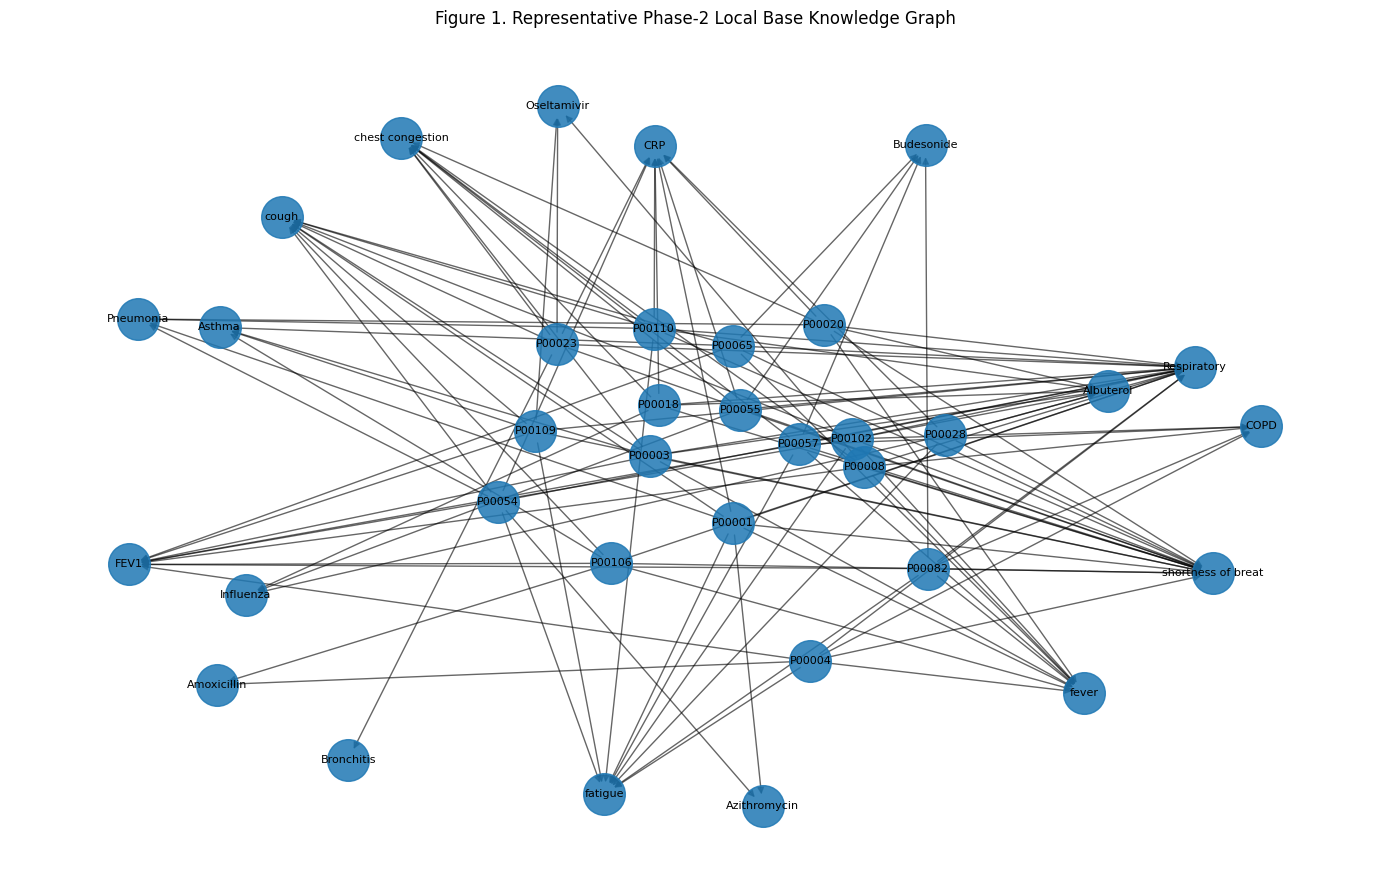

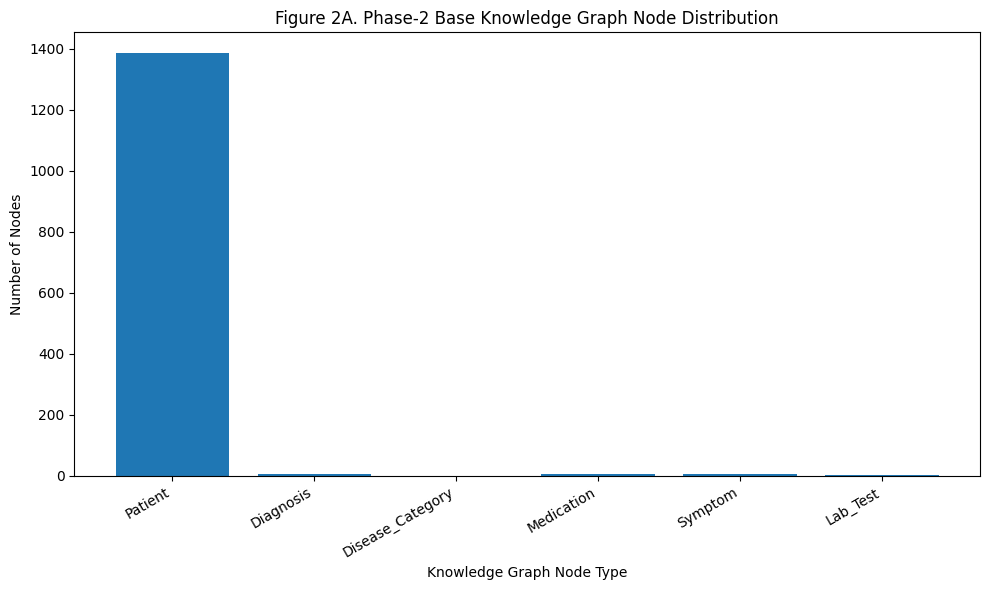

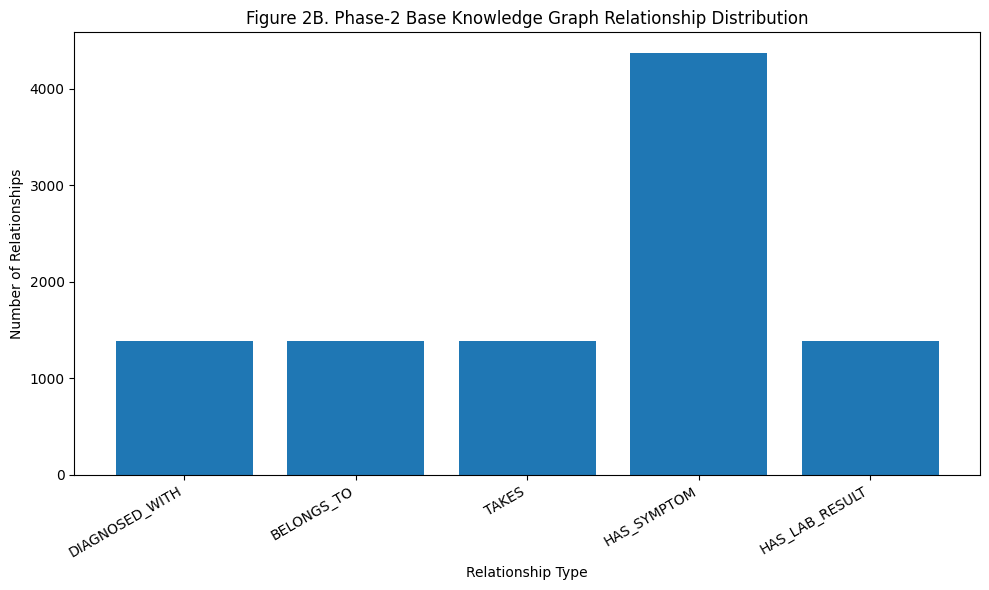

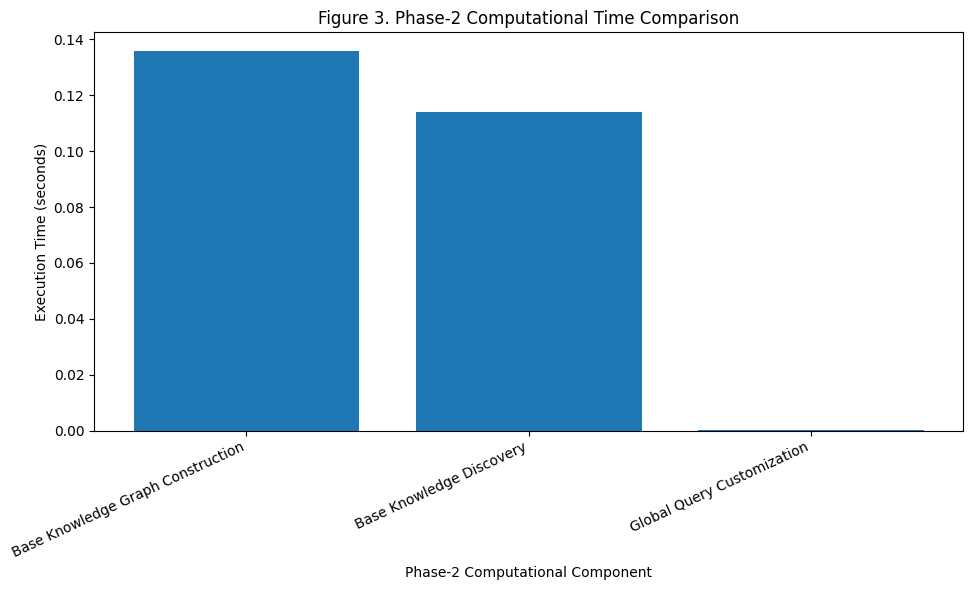


PHASE 2 FINAL SUMMARY
Base KG nodes: 1402
Base KG edges: 9902
Discovered nodes: 3
Discovered patients: 1384
Discovered relationships: 9902

Customized global query:
shortness breath cough pneumonia

Base KG construction time: 0.135751 seconds
Knowledge discovery time: 0.113846 seconds
Global query customization time: 0.000094 seconds
TOTAL PHASE-2 COMPUTATION TIME: 0.249691 seconds

PHASE-2 OUTPUT FILES
/content/Phase2_Computation_Results.csv
/content/Phase2_Query_Customization_Results.csv
/content/Phase2_Discovered_Knowledge.csv
/content/Phase2_Base_Knowledge_Graph.graphml
/content/Phase2_Graph_Statistics.csv
/content/Figure1_Phase2_Base_Knowledge_Graph.png
/content/Figure2A_Phase2_Node_Distribution.png
/content/Figure2B_Phase2_Relationship_Distribution.png
/content/Figure3_Phase2_Computation_Time.png

Phase 2 completed.


In [ ]:
# ============================================================
# PHASE 2
# BASE MODEL OF KNOWLEDGE GRAPH BUILDING (LOCAL)
# ============================================================
#
# Block-diagram alignment:
#
# Local-phase: Knowledge Graph
#          ↓
# Phase-2: Base Model of Knowledge Graph Building (local)
#          ↓
# Base Knowledge Discovery System
#          ↓
# Customizing global query of data
#
# Phase 2 does NOT perform:
#   - External server processing
#   - Third-party LLM processing
#   - LLM training
#   - Global knowledge-graph construction
#
# Those operations belong to the later global/server stage.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import re
import time

from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


# ------------------------------------------------------------
# 2. DEFINE FILE PATHS
# ------------------------------------------------------------

# Main synthetic EHR dataset
DATA_PATH = "/content/Phase1_Synthetic_EHR_Dataset_10000.csv"

# Output generated during Phase 1
PHASE1_RETRIEVAL_PATH = (
    "/content/Phase1_Local_EHR_Retrieval_Results.csv"
)

PHASE1_GRAPH_PATH = (
    "/content/Phase1_Local_Knowledge_Graph.graphml"
)


# ------------------------------------------------------------
# 3. LOAD THE MAIN EHR DATASET
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("==============================================")
print("DATASET")
print("==============================================")

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())


# ------------------------------------------------------------
# 4. LOAD PHASE-1 LOCAL EHR RESULTS
# ------------------------------------------------------------
#
# Phase 2 starts from the local EHR information generated
# during Phase 1.
# ------------------------------------------------------------

phase1_local_results = pd.read_csv(
    PHASE1_RETRIEVAL_PATH
)

print("\n==============================================")
print("PHASE-1 LOCAL EHR RESULTS")
print("==============================================")

print(
    "Number of Phase-1 local records:",
    len(phase1_local_results)
)


# ------------------------------------------------------------
# 5. LOAD PHASE-1 LOCAL KNOWLEDGE GRAPH
# ------------------------------------------------------------
#
# This graph represents the output of Phase 1.
# We use it as the starting local knowledge representation.
# ------------------------------------------------------------

local_kg = nx.read_graphml(
    PHASE1_GRAPH_PATH
)

print("\n==============================================")
print("PHASE-1 LOCAL KNOWLEDGE GRAPH")
print("==============================================")

print(
    "Nodes:",
    local_kg.number_of_nodes()
)

print(
    "Edges:",
    local_kg.number_of_edges()
)


# ============================================================
# PHASE 2 - BLOCK 1
# BASE MODEL OF KNOWLEDGE GRAPH BUILDING (LOCAL)
# ============================================================
#
# We build an expanded local base knowledge model using the
# EHR information available after Phase 1.
#
# Node types:
#   Patient
#   Symptom
#   Diagnosis
#   Disease Category
#   Medication
#   Lab Test
#
# Relationship types:
#   HAS_SYMPTOM
#   DIAGNOSED_WITH
#   BELONGS_TO
#   TAKES
#   HAS_LAB_RESULT
# ============================================================


def build_base_knowledge_model(ehr_records):
    """
    Construct the Phase-2 local base knowledge graph.
    """

    graph = nx.MultiDiGraph()

    for _, row in ehr_records.iterrows():

        # ----------------------------------------------------
        # Patient
        # ----------------------------------------------------

        patient_id = str(row["patient_id"])

        patient_node = f"Patient:{patient_id}"

        graph.add_node(
            patient_node,
            node_type="Patient",
            patient_id=patient_id,
            age=str(row["age"]),
            gender=str(row["gender"])
        )

        # ----------------------------------------------------
        # Diagnosis
        # ----------------------------------------------------

        diagnosis = str(row["diagnosis"])

        diagnosis_node = (
            f"Diagnosis:{diagnosis}"
        )

        graph.add_node(
            diagnosis_node,
            node_type="Diagnosis"
        )

        graph.add_edge(
            patient_node,
            diagnosis_node,
            relation="DIAGNOSED_WITH"
        )

        # ----------------------------------------------------
        # Disease Category
        # ----------------------------------------------------

        category = str(
            row["disease_category"]
        )

        category_node = (
            f"Category:{category}"
        )

        graph.add_node(
            category_node,
            node_type="Disease_Category"
        )

        graph.add_edge(
            patient_node,
            category_node,
            relation="BELONGS_TO"
        )

        # ----------------------------------------------------
        # Medication
        # ----------------------------------------------------

        medication = str(
            row["medications"]
        )

        medication_node = (
            f"Medication:{medication}"
        )

        graph.add_node(
            medication_node,
            node_type="Medication"
        )

        graph.add_edge(
            patient_node,
            medication_node,
            relation="TAKES"
        )

        # ----------------------------------------------------
        # Symptoms
        # ----------------------------------------------------

        symptoms = str(
            row["symptoms"]
        ).split(";")

        for symptom in symptoms:

            symptom = symptom.strip()

            if symptom == "":
                continue

            symptom_node = (
                f"Symptom:{symptom}"
            )

            graph.add_node(
                symptom_node,
                node_type="Symptom"
            )

            graph.add_edge(
                patient_node,
                symptom_node,
                relation="HAS_SYMPTOM"
            )

        # ----------------------------------------------------
        # Laboratory Result
        # ----------------------------------------------------

        lab_name = str(
            row["lab_name"]
        )

        lab_value = str(
            row["lab_value"]
        )

        lab_node = (
            f"Lab:{lab_name}"
        )

        graph.add_node(
            lab_node,
            node_type="Lab_Test"
        )

        graph.add_edge(
            patient_node,
            lab_node,
            relation="HAS_LAB_RESULT",
            value=lab_value
        )

    return graph


# ------------------------------------------------------------
# Measure Base KG Construction Time
# ------------------------------------------------------------

start_base_kg = time.perf_counter()

base_kg = build_base_knowledge_model(
    phase1_local_results
)

base_kg_time = (
    time.perf_counter()
    - start_base_kg
)


# ------------------------------------------------------------
# Report Base KG
# ------------------------------------------------------------

print("\n==============================================")
print("PHASE 2 - BASE KNOWLEDGE MODEL")
print("==============================================")

print(
    "Base KG nodes:",
    base_kg.number_of_nodes()
)

print(
    "Base KG edges:",
    base_kg.number_of_edges()
)

print(
    "Base KG construction time:",
    f"{base_kg_time:.6f} seconds"
)


# ============================================================
# PHASE 2 - BLOCK 2
# BASE KNOWLEDGE DISCOVERY SYSTEM
# ============================================================
#
# This block searches the local base knowledge model to
# determine what information is already available locally.
# ============================================================


def discover_local_knowledge(
    graph,
    simplified_query
):
    """
    Discover relevant local knowledge from the Phase-2 graph.
    """

    query_terms = simplified_query.lower().split()

    matching_nodes = []
    matching_patients = set()
    matching_edges = []

    # --------------------------------------------------------
    # Search nodes
    # --------------------------------------------------------

    for node, attributes in graph.nodes(
        data=True
    ):

        node_text = str(node).lower()

        matched = any(
            term in node_text
            for term in query_terms
            if len(term) > 2
        )

        if matched:

            matching_nodes.append(node)

            # Find patient nodes directly connected
            for predecessor in graph.predecessors(node):

                if str(predecessor).startswith(
                    "Patient:"
                ):
                    matching_patients.add(
                        predecessor
                    )

    # --------------------------------------------------------
    # Collect relationships for discovered patients
    # --------------------------------------------------------

    for patient in matching_patients:

        for _, target, attributes in graph.out_edges(
            patient,
            data=True
        ):

            matching_edges.append({
                "source": patient,
                "target": target,
                "relation": attributes.get(
                    "relation",
                    "UNKNOWN"
                )
            })

    return (
        matching_nodes,
        matching_patients,
        matching_edges
    )


# ------------------------------------------------------------
# Obtain Phase-1 simplified query
# ------------------------------------------------------------

if "simplified_query" in phase1_local_results.columns:

    phase2_query = str(
        phase1_local_results.loc[
            0,
            "simplified_query"
        ]
    )

else:

    phase2_query = str(
        df.loc[
            0,
            "simplified_query"
        ]
    )


print("\n==============================================")
print("PHASE-2 INPUT QUERY")
print("==============================================")

print(phase2_query)


# ------------------------------------------------------------
# Measure Knowledge Discovery Time
# ------------------------------------------------------------

start_discovery = time.perf_counter()

(
    discovered_nodes,
    discovered_patients,
    discovered_edges
) = discover_local_knowledge(
    base_kg,
    phase2_query
)

knowledge_discovery_time = (
    time.perf_counter()
    - start_discovery
)


print("\n==============================================")
print("BASE KNOWLEDGE DISCOVERY")
print("==============================================")

print(
    "Discovered nodes:",
    len(discovered_nodes)
)

print(
    "Discovered patients:",
    len(discovered_patients)
)

print(
    "Discovered relationships:",
    len(discovered_edges)
)

print(
    "Knowledge discovery time:",
    f"{knowledge_discovery_time:.6f} seconds"
)


# ============================================================
# PHASE 2 - BLOCK 3
# CUSTOMIZING GLOBAL QUERY OF DATA
# ============================================================
#
# The local knowledge already available is identified.
# The query is then prepared for the later global stage.
#
# IMPORTANT:
# No external server or LLM is called here.
# ============================================================


def customize_global_query(
    original_query,
    simplified_query,
    discovered_nodes
):
    """
    Prepare a customized query for the later global stage.
    """

    query_terms = simplified_query.lower().split()

    # --------------------------------------------------------
    # Identify terms recognized locally
    # --------------------------------------------------------

    local_terms = set()

    for node in discovered_nodes:

        node_lower = str(node).lower()

        for term in query_terms:

            if term in node_lower:
                local_terms.add(term)

    # --------------------------------------------------------
    # Identify unresolved terms
    # --------------------------------------------------------

    unresolved_terms = (
        set(query_terms)
        - local_terms
    )

    # --------------------------------------------------------
    # Retain meaningful query terms
    # --------------------------------------------------------

    global_query_terms = [
        term
        for term in query_terms
        if len(term) > 2
    ]

    customized_global_query = " ".join(
        global_query_terms
    )

    return {
        "original_query": original_query,
        "simplified_query": simplified_query,
        "local_terms": sorted(local_terms),
        "unresolved_terms": sorted(
            unresolved_terms
        ),
        "customized_global_query":
            customized_global_query
    }


# ------------------------------------------------------------
# Original user query
# ------------------------------------------------------------

original_query = str(
    df.loc[0, "user_query"]
)


# ------------------------------------------------------------
# Measure Query Customization Time
# ------------------------------------------------------------

start_query_customization = time.perf_counter()

query_information = customize_global_query(
    original_query,
    phase2_query,
    discovered_nodes
)

query_customization_time = (
    time.perf_counter()
    - start_query_customization
)


# ------------------------------------------------------------
# Display Customized Query
# ------------------------------------------------------------

print("\n==============================================")
print("GLOBAL QUERY CUSTOMIZATION")
print("==============================================")

print(
    "Original query:"
)

print(
    query_information[
        "original_query"
    ]
)

print(
    "\nSimplified query:"
)

print(
    query_information[
        "simplified_query"
    ]
)

print(
    "\nLocally recognized terms:"
)

print(
    query_information[
        "local_terms"
    ]
)

print(
    "\nUnresolved terms:"
)

print(
    query_information[
        "unresolved_terms"
    ]
)

print(
    "\nCustomized global query:"
)

print(
    query_information[
        "customized_global_query"
    ]
)

print(
    "\nQuery customization time:",
    f"{query_customization_time:.6f} seconds"
)


# ============================================================
# 6. BASE KG NODE DISTRIBUTION
# ============================================================

node_type_counts = Counter()

for node, attributes in base_kg.nodes(
    data=True
):

    node_type = attributes.get(
        "node_type",
        "Unknown"
    )

    node_type_counts[
        node_type
    ] += 1


print("\n==============================================")
print("BASE KG NODE DISTRIBUTION")
print("==============================================")

for node_type, count in node_type_counts.items():

    print(
        f"{node_type}: {count}"
    )


# ============================================================
# 7. BASE KG RELATIONSHIP DISTRIBUTION
# ============================================================

relation_counts = Counter()

for _, _, attributes in base_kg.edges(
    data=True
):

    relation = attributes.get(
        "relation",
        "Unknown"
    )

    relation_counts[
        relation
    ] += 1


print("\n==============================================")
print("BASE KG RELATIONSHIP DISTRIBUTION")
print("==============================================")

for relation, count in relation_counts.items():

    print(
        f"{relation}: {count}"
    )


# ============================================================
# 8. PHASE-2 GRAPH STATISTICS
# ============================================================

if base_kg.number_of_nodes() > 0:

    graph_density = nx.density(
        base_kg
    )

else:

    graph_density = 0.0


print("\n==============================================")
print("PHASE-2 KNOWLEDGE GRAPH STATISTICS")
print("==============================================")

print(
    "Total nodes:",
    base_kg.number_of_nodes()
)

print(
    "Total edges:",
    base_kg.number_of_edges()
)

print(
    "Graph density:",
    f"{graph_density:.8f}"
)

print(
    "Discovered nodes:",
    len(discovered_nodes)
)

print(
    "Discovered patients:",
    len(discovered_patients)
)

print(
    "Discovered relationships:",
    len(discovered_edges)
)

print(
    "Unresolved query terms:",
    len(
        query_information[
            "unresolved_terms"
        ]
    )
)


# ============================================================
# 9. TOTAL PHASE-2 COMPUTATION TIME
# ============================================================

phase2_total_time = (
    base_kg_time
    + knowledge_discovery_time
    + query_customization_time
)


phase2_results = pd.DataFrame({

    "Phase": [
        "Phase 2",
        "Phase 2",
        "Phase 2",
        "Phase 2"
    ],

    "Component": [
        "Base Knowledge Graph Construction",
        "Base Knowledge Discovery",
        "Global Query Customization",
        "Total Phase 2 Computation"
    ],

    "Time_seconds": [
        base_kg_time,
        knowledge_discovery_time,
        query_customization_time,
        phase2_total_time
    ]
})


print("\n==============================================")
print("PHASE-2 COMPUTATIONAL RESULTS")
print("==============================================")

display(
    phase2_results
)


# ============================================================
# 10. DISCOVERED KNOWLEDGE TABLE
# ============================================================

discovered_knowledge_df = pd.DataFrame(
    discovered_edges
)


print("\n==============================================")
print("DISCOVERED LOCAL KNOWLEDGE")
print("==============================================")

display(
    discovered_knowledge_df.head(20)
)


# ============================================================
# 11. QUERY CUSTOMIZATION SUMMARY
# ============================================================

query_summary = pd.DataFrame({

    "Original_Query": [
        query_information[
            "original_query"
        ]
    ],

    "Simplified_Query": [
        query_information[
            "simplified_query"
        ]
    ],

    "Local_Terms": [
        "; ".join(
            query_information[
                "local_terms"
            ]
        )
    ],

    "Unresolved_Terms": [
        "; ".join(
            query_information[
                "unresolved_terms"
            ]
        )
    ],

    "Customized_Global_Query": [
        query_information[
            "customized_global_query"
        ]
    ],

    "Discovered_Patients": [
        len(discovered_patients)
    ],

    "Discovered_Nodes": [
        len(discovered_nodes)
    ],

    "Discovered_Relationships": [
        len(discovered_edges)
    ]
})


# ============================================================
# 12. SAVE PHASE-2 RESULTS
# ============================================================

phase2_results.to_csv(
    "/content/Phase2_Computation_Results.csv",
    index=False
)

query_summary.to_csv(
    "/content/Phase2_Query_Customization_Results.csv",
    index=False
)

discovered_knowledge_df.to_csv(
    "/content/Phase2_Discovered_Knowledge.csv",
    index=False
)

# Save the Phase-2 base knowledge graph
nx.write_graphml(
    base_kg,
    "/content/Phase2_Base_Knowledge_Graph.graphml"
)


# ============================================================
# 13. FIGURE 1
# REPRESENTATIVE BASE KNOWLEDGE GRAPH
# ============================================================
#
# A full 10,000-record graph would be unreadable.
# Therefore, only a small representative subgraph is plotted.
#
# The complete graph remains saved as GraphML.
# ============================================================


# Select a limited number of nodes for demonstration
MAX_GRAPH_NODES = 35

# Take the first few nodes
sample_nodes = list(
    base_kg.nodes()
)[:MAX_GRAPH_NODES]

sample_graph = base_kg.subgraph(
    sample_nodes
).copy()


plt.figure(figsize=(14, 9))

# Layout for visualization
pos = nx.spring_layout(
    sample_graph,
    seed=42,
    k=1.2
)

# Draw nodes and edges
nx.draw_networkx_nodes(
    sample_graph,
    pos,
    node_size=900,
    alpha=0.85
)

nx.draw_networkx_edges(
    sample_graph,
    pos,
    arrows=True,
    alpha=0.6
)

# Short labels for readability
labels = {}

for node in sample_graph.nodes():

    # Keep only the entity name after ":"
    if ":" in str(node):

        short_label = str(node).split(
            ":",
            1
        )[1]

    else:

        short_label = str(node)

    # Truncate long labels
    labels[node] = short_label[:18]


nx.draw_networkx_labels(
    sample_graph,
    pos,
    labels=labels,
    font_size=8
)

plt.title(
    "Figure 1. Representative Phase-2 Local Base Knowledge Graph"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/Figure1_Phase2_Base_Knowledge_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. FIGURE 2A
# NODE-TYPE DISTRIBUTION
# ============================================================


plt.figure(figsize=(10, 6))

node_labels = list(
    node_type_counts.keys()
)

node_values = list(
    node_type_counts.values()
)

plt.bar(
    node_labels,
    node_values
)

plt.xlabel(
    "Knowledge Graph Node Type"
)

plt.ylabel(
    "Number of Nodes"
)

plt.title(
    "Figure 2A. Phase-2 Base Knowledge Graph Node Distribution"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "/content/Figure2A_Phase2_Node_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. FIGURE 2B
# RELATIONSHIP DISTRIBUTION
# ============================================================


plt.figure(figsize=(10, 6))

relation_labels = list(
    relation_counts.keys()
)

relation_values = list(
    relation_counts.values()
)

plt.bar(
    relation_labels,
    relation_values
)

plt.xlabel(
    "Relationship Type"
)

plt.ylabel(
    "Number of Relationships"
)

plt.title(
    "Figure 2B. Phase-2 Base Knowledge Graph Relationship Distribution"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "/content/Figure2B_Phase2_Relationship_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 16. FIGURE 3
# PHASE-2 COMPUTATION-TIME COMPARISON
# ============================================================
#
# This is the most important Phase-2 efficiency figure.
# ============================================================


time_plot_df = phase2_results[
    phase2_results["Component"]
    != "Total Phase 2 Computation"
].copy()


plt.figure(figsize=(10, 6))

plt.bar(
    time_plot_df["Component"],
    time_plot_df["Time_seconds"]
)

plt.xlabel(
    "Phase-2 Computational Component"
)

plt.ylabel(
    "Execution Time (seconds)"
)

plt.title(
    "Figure 3. Phase-2 Computational Time Comparison"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "/content/Figure3_Phase2_Computation_Time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 17. SAVE GRAPH STATISTICS
# ============================================================

graph_statistics = pd.DataFrame({

    "Metric": [
        "Total Nodes",
        "Total Edges",
        "Graph Density",
        "Discovered Nodes",
        "Discovered Patients",
        "Discovered Relationships",
        "Unresolved Query Terms"
    ],

    "Value": [
        base_kg.number_of_nodes(),
        base_kg.number_of_edges(),
        graph_density,
        len(discovered_nodes),
        len(discovered_patients),
        len(discovered_edges),
        len(
            query_information[
                "unresolved_terms"
            ]
        )
    ]
})


graph_statistics.to_csv(
    "/content/Phase2_Graph_Statistics.csv",
    index=False
)


# ============================================================
# 18. FINAL PHASE-2 SUMMARY
# ============================================================

print("\n==============================================")
print("PHASE 2 FINAL SUMMARY")
print("==============================================")

print(
    "Base KG nodes:",
    base_kg.number_of_nodes()
)

print(
    "Base KG edges:",
    base_kg.number_of_edges()
)

print(
    "Discovered nodes:",
    len(discovered_nodes)
)

print(
    "Discovered patients:",
    len(discovered_patients)
)

print(
    "Discovered relationships:",
    len(discovered_edges)
)

print(
    "\nCustomized global query:"
)

print(
    query_information[
        "customized_global_query"
    ]
)

print(
    "\nBase KG construction time:",
    f"{base_kg_time:.6f} seconds"
)

print(
    "Knowledge discovery time:",
    f"{knowledge_discovery_time:.6f} seconds"
)

print(
    "Global query customization time:",
    f"{query_customization_time:.6f} seconds"
)

print(
    "TOTAL PHASE-2 COMPUTATION TIME:",
    f"{phase2_total_time:.6f} seconds"
)


# ============================================================
# GENERATED OUTPUT FILES
# ============================================================

print("\n==============================================")
print("PHASE-2 OUTPUT FILES")
print("==============================================")

print(
    "/content/Phase2_Computation_Results.csv"
)

print(
    "/content/Phase2_Query_Customization_Results.csv"
)

print(
    "/content/Phase2_Discovered_Knowledge.csv"
)

print(
    "/content/Phase2_Base_Knowledge_Graph.graphml"
)

print(
    "/content/Phase2_Graph_Statistics.csv"
)

print(
    "/content/Figure1_Phase2_Base_Knowledge_Graph.png"
)

print(
    "/content/Figure2A_Phase2_Node_Distribution.png"
)

print(
    "/content/Figure2B_Phase2_Relationship_Distribution.png"
)

print(
    "/content/Figure3_Phase2_Computation_Time.png"
)

print("\nPhase 2 completed.")

In [ ]:
# ============================================================
# PHASE 3
# GLOBAL KNOWLEDGE MODEL BUILDING + BACKEND LLM PROCESSING
# ============================================================
#
# Architecture alignment:
#
# Phase 2 Customized Global Query
#              |
#              v
# External / Backend Server Processing
#              |
#              v
# LLM Pipeline
#              |
#              v
# Global EHR Knowledge Model
#              |
#              v
# NLP Classification
#              |
#              v
# Disease Token Mapping & Customization
#
# This phase also measures:
#   - LLM training time
#   - training loss
#   - validation loss
#   - epoch progress
#   - CPU usage
#   - RAM usage
#   - GPU utilization
#   - GPU memory
#   - inference latency
#   - throughput
#   - classification effectiveness
#   - global KG construction time
#
# ============================================================


# ============================================================
# 0. OPTIONAL PACKAGE INSTALLATION
# ============================================================
#
# Run this cell once if required.
# After installation, restart the runtime if Colab asks.
#
# !pip install -q -U transformers datasets accelerate psutil sentencepiece
#
# Optional GPU monitoring:
# !pip install -q pynvml
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import re
import json
import time
import random
import warnings
import inspect

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import networkx as nx
import psutil

import torch

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    TrainerCallback,
    EvalPrediction
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 3. FIXED DATA PATH
# ============================================================

DATA_PATH = (
    "/content/Phase1_Synthetic_EHR_Dataset_10000.csv"
)

PHASE2_QUERY_PATH = (
    "/content/Phase2_Query_Customization_Results.csv"
)

PHASE2_GRAPH_PATH = (
    "/content/Phase2_Base_Knowledge_Graph.graphml"
)

OUTPUT_DIR = (
    "/content/Phase3_BioClinicalBERT"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 4. CHECK REQUIRED FILES
# ============================================================

print("==============================================")
print("FILE CHECK")
print("==============================================")

required_files = [
    DATA_PATH,
    PHASE2_QUERY_PATH,
    PHASE2_GRAPH_PATH
]

for file_path in required_files:

    exists = os.path.exists(file_path)

    print(
        f"{file_path} -> "
        f"{'FOUND' if exists else 'NOT FOUND'}"
    )

if not os.path.exists(DATA_PATH):

    raise FileNotFoundError(
        "The Phase-1 EHR dataset was not found at:\n"
        + DATA_PATH
    )


# ============================================================
# 5. COMPUTING ENVIRONMENT
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

CPU_COUNT = os.cpu_count()

RAM_TOTAL_GB = (
    psutil.virtual_memory().total
    / (1024 ** 3)
)


print("\n==============================================")
print("COMPUTING ENVIRONMENT")
print("==============================================")

print(
    "Device:",
    DEVICE
)

print(
    "CPU cores:",
    CPU_COUNT
)

print(
    "Total RAM:",
    round(
        RAM_TOTAL_GB,
        2
    ),
    "GB"
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    GPU_TOTAL_GB = (
        torch.cuda.get_device_properties(0)
        .total_memory
        / (1024 ** 3)
    )

    print(
        "GPU memory:",
        round(
            GPU_TOTAL_GB,
            2
        ),
        "GB"
    )

else:

    GPU_TOTAL_GB = 0

    print(
        "GPU: Not available"
    )


# ============================================================
# 6. LOAD EHR DATASET
# ============================================================

print("\n==============================================")
print("LOADING EHR DATASET")
print("==============================================")


df = pd.read_csv(
    DATA_PATH
)


print(
    "Dataset shape:",
    df.shape
)

print(
    "Number of records:",
    len(df)
)

print(
    "Number of columns:",
    len(df.columns)
)

display(
    df.head()
)


# ============================================================
# 7. BASIC DATA VALIDATION
# ============================================================

required_columns = [
    "patient_id",
    "symptoms",
    "medical_history",
    "medications",
    "diagnosis",
    "lab_name",
    "lab_value",
    "clinical_notes",
    "user_query"
]


missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]


if len(missing_columns) > 0:

    raise ValueError(
        "The following required columns are missing:\n"
        + str(missing_columns)
    )


# Remove accidental missing clinical values
for column in required_columns:

    df[column] = (
        df[column]
        .fillna("")
        .astype(str)
    )


# ============================================================
# 8. LOAD PHASE-2 CUSTOMIZED QUERY
# ============================================================

print("\n==============================================")
print("PHASE-2 → PHASE-3 QUERY")
print("==============================================")


phase2_query = None


if os.path.exists(
    PHASE2_QUERY_PATH
):

    phase2_query_df = pd.read_csv(
        PHASE2_QUERY_PATH
    )

    if (
        "Customized_Global_Query"
        in phase2_query_df.columns
        and
        len(phase2_query_df) > 0
    ):

        phase2_query = str(
            phase2_query_df.loc[
                0,
                "Customized_Global_Query"
            ]
        )


# Fallback if Phase-2 file does not contain usable query
if (
    phase2_query is None
    or phase2_query.strip() == ""
    or phase2_query.lower() == "nan"
):

    phase2_query = str(
        df.loc[
            0,
            "user_query"
        ]
    )


print(
    "Customized global query:"
)

print(
    phase2_query
)


# ============================================================
# 9. BUILD GLOBAL EHR KNOWLEDGE GRAPH
# ============================================================
#
# This corresponds to:
#
# "Building global knowledge on data graph models of EHR"
#
# ============================================================


def build_global_ehr_graph(
    ehr_data
):

    graph = nx.MultiDiGraph()

    for _, row in ehr_data.iterrows():

        patient = (
            f"Patient:{row['patient_id']}"
        )

        diagnosis = (
            f"Diagnosis:{row['diagnosis']}"
        )

        category = (
            f"Category:{row['disease_category']}"
        )

        medication = (
            f"Medication:{row['medications']}"
        )

        lab = (
            f"Lab:{row['lab_name']}"
        )

        # Patient
        graph.add_node(
            patient,
            node_type="Patient"
        )

        # Diagnosis
        graph.add_node(
            diagnosis,
            node_type="Diagnosis"
        )

        graph.add_edge(
            patient,
            diagnosis,
            relation="DIAGNOSED_WITH"
        )

        # Disease category
        graph.add_node(
            category,
            node_type="Disease_Category"
        )

        graph.add_edge(
            patient,
            category,
            relation="BELONGS_TO"
        )

        # Medication
        graph.add_node(
            medication,
            node_type="Medication"
        )

        graph.add_edge(
            patient,
            medication,
            relation="TAKES"
        )

        # Laboratory
        graph.add_node(
            lab,
            node_type="Lab_Test"
        )

        graph.add_edge(
            patient,
            lab,
            relation="HAS_LAB_RESULT",
            value=str(
                row["lab_value"]
            )
        )

        # Symptoms
        symptoms = str(
            row["symptoms"]
        ).split(";")

        for symptom in symptoms:

            symptom = symptom.strip()

            if symptom == "":
                continue

            symptom_node = (
                f"Symptom:{symptom}"
            )

            graph.add_node(
                symptom_node,
                node_type="Symptom"
            )

            graph.add_edge(
                patient,
                symptom_node,
                relation="HAS_SYMPTOM"
            )

    return graph


# Measure KG construction time

global_kg_start = time.perf_counter()

global_kg = build_global_ehr_graph(
    df
)

global_kg_time = (
    time.perf_counter()
    - global_kg_start
)


print("\n==============================================")
print("GLOBAL EHR KNOWLEDGE MODEL")
print("==============================================")

print(
    "Nodes:",
    global_kg.number_of_nodes()
)

print(
    "Edges:",
    global_kg.number_of_edges()
)

print(
    "Construction time:",
    round(
        global_kg_time,
        4
    ),
    "seconds"
)


# Save global graph
GLOBAL_GRAPH_PATH = (
    f"{OUTPUT_DIR}/Phase3_Global_EHR_Knowledge_Graph.graphml"
)

nx.write_graphml(
    global_kg,
    GLOBAL_GRAPH_PATH
)


# ============================================================
# 10. PREPARE LLM INPUT
# ============================================================
#
# Diagnosis is intentionally NOT included in the input text.
# It is the prediction label.
#
# This avoids direct label leakage.
# ============================================================


def create_model_text(row):

    return (
        "Symptoms: "
        + str(row["symptoms"])
        + ". "
        + "Medical history: "
        + str(row["medical_history"])
        + ". "
        + "Medications: "
        + str(row["medications"])
        + ". "
        + "Laboratory test: "
        + str(row["lab_name"])
        + ", value "
        + str(row["lab_value"])
        + ". "
        + "Clinical notes: "
        + str(row["clinical_notes"])
    )


df["model_text"] = df.apply(
    create_model_text,
    axis=1
)


# ============================================================
# 11. CREATE DISEASE LABEL MAPPING
# ============================================================

labels = sorted(
    df["diagnosis"]
    .astype(str)
    .unique()
)

label2id = {
    label: index
    for index, label
    in enumerate(labels)
}

id2label = {
    index: label
    for label, index
    in label2id.items()
}

df["label"] = (
    df["diagnosis"]
    .map(label2id)
)


print("\n==============================================")
print("DISEASE CLASSES")
print("==============================================")

print(
    "Number of classes:",
    len(labels)
)

for index, label in id2label.items():

    print(
        index,
        "->",
        label
    )


# ============================================================
# 12. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)


print("\n==============================================")
print("DATA SPLIT")
print("==============================================")

print(
    "Training:",
    len(train_df)
)

print(
    "Validation:",
    len(validation_df)
)

print(
    "Testing:",
    len(test_df)
)


# ============================================================
# 13. CREATE HUGGING FACE DATASETS
# ============================================================

train_dataset = Dataset.from_pandas(
    train_df[
        ["model_text", "label"]
    ].reset_index(drop=True)
)

validation_dataset = Dataset.from_pandas(
    validation_df[
        ["model_text", "label"]
    ].reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    test_df[
        ["model_text", "label"]
    ].reset_index(drop=True)
)


# ============================================================
# 14. LOAD CLINICAL BERT MODEL
# ============================================================

MODEL_NAME = (
    "emilyalsentzer/Bio_ClinicalBERT"
)


print("\n==============================================")
print("LOADING CLINICAL LLM")
print("==============================================")

print(
    "Model:",
    MODEL_NAME
)


tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)


# ============================================================
# 15. TOKENIZATION
# ============================================================


MAX_LENGTH = 256


def tokenize_function(
    batch
):

    return tokenizer(
        batch["model_text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


print("\nTokenizing training dataset...")

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    desc="Training tokenization"
)


print("Tokenizing validation dataset...")

validation_dataset = validation_dataset.map(
    tokenize_function,
    batched=True,
    desc="Validation tokenization"
)


print("Tokenizing test dataset...")

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True,
    desc="Test tokenization"
)


data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)


# ============================================================
# 16. METRIC FUNCTION
# ============================================================


def compute_metrics(
    eval_prediction
):

    predictions = (
        eval_prediction.predictions
    )

    true_labels = (
        eval_prediction.label_ids
    )

    # Handle models returning tuples
    if isinstance(
        predictions,
        tuple
    ):

        predictions = predictions[0]

    predicted_labels = np.argmax(
        predictions,
        axis=-1
    )

    accuracy = accuracy_score(
        true_labels,
        predicted_labels
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            true_labels,
            predicted_labels,
            average="weighted",
            zero_division=0
        )
    )

    return {

        "accuracy": float(
            accuracy
        ),

        "precision": float(
            precision
        ),

        "recall": float(
            recall
        ),

        "f1": float(
            f1
        )
    }


# ============================================================
# 17. SERVER PROFILE
# ============================================================
#
# These profiles represent experimental resource settings.
# Do NOT describe them as three physical servers unless
# you actually run on three different servers.
# ============================================================


SERVER_PROFILE = "LSR"


SERVER_PROFILES = {

    "S1": {

        "train_batch": 4,

        "eval_batch": 4,

        "gradient_accumulation": 2,

        "workers": 0
    },

    "LSR": {

        "train_batch": 8,

        "eval_batch": 8,

        "gradient_accumulation": 2,

        "workers": 2
    },

    "CSR": {

        "train_batch": 16,

        "eval_batch": 16,

        "gradient_accumulation": 4,

        "workers": 4
    }
}


server_config = SERVER_PROFILES[
    SERVER_PROFILE
]


print("\n==============================================")
print("BACKEND PROFILE")
print("==============================================")

print(
    "Profile:",
    SERVER_PROFILE
)

print(
    server_config
)


# ============================================================
# 18. COMPATIBLE TRAINING ARGUMENTS
# ============================================================
#
# Different Transformers versions use slightly different
# parameter names. This section checks the installed version
# rather than assuming one API.
# ============================================================


training_signature = inspect.signature(
    TrainingArguments.__init__
)

training_parameters = (
    training_signature.parameters
)


training_kwargs = {

    "output_dir":
        OUTPUT_DIR,

    "learning_rate":
        2e-5,

    "per_device_train_batch_size":
        server_config[
            "train_batch"
        ],

    "per_device_eval_batch_size":
        server_config[
            "eval_batch"
        ],

    "gradient_accumulation_steps":
        server_config[
            "gradient_accumulation"
        ],

    "num_train_epochs":
        5,

    "weight_decay":
        0.01,

    "logging_strategy":
        "steps",

    "logging_steps":
        25,

    "save_strategy":
        "epoch",

    "load_best_model_at_end":
        True,

    "metric_for_best_model":
        "f1",

    "greater_is_better":
        True,

    "report_to":
        "none",

    "dataloader_num_workers":
        server_config[
            "workers"
        ],

    "seed":
        SEED
}


# ------------------------------------------------------------
# New API: eval_strategy
# Older API: evaluation_strategy
# ------------------------------------------------------------

if "eval_strategy" in training_parameters:

    training_kwargs[
        "eval_strategy"
    ] = "epoch"

elif "evaluation_strategy" in training_parameters:

    training_kwargs[
        "evaluation_strategy"
    ] = "epoch"


# ------------------------------------------------------------
# Mixed precision
# ------------------------------------------------------------

if "fp16" in training_parameters:

    training_kwargs[
        "fp16"
    ] = bool(
        torch.cuda.is_available()
    )


# ------------------------------------------------------------
# BF16 only if GPU supports it
# ------------------------------------------------------------

if "bf16" in training_parameters:

    use_bf16 = False

    if torch.cuda.is_available():

        try:

            use_bf16 = (
                torch.cuda.is_bf16_supported()
            )

        except Exception:

            use_bf16 = False

    training_kwargs[
        "bf16"
    ] = use_bf16


# ------------------------------------------------------------
# Only keep parameters supported by installed version
# ------------------------------------------------------------

safe_training_kwargs = {

    key: value

    for key, value
    in training_kwargs.items()

    if key in training_parameters
}


training_args = TrainingArguments(
    **safe_training_kwargs
)


print("\n==============================================")
print("TRAINING CONFIGURATION")
print("==============================================")

for key, value in safe_training_kwargs.items():

    print(
        f"{key}: {value}"
    )


# ============================================================
# 19. RESOURCE MONITOR CALLBACK
# ============================================================


resource_monitor = []


class ResourceMonitoringCallback(
    TrainerCallback
):

    def __init__(self):

        self.start_time = None


    def on_train_begin(
        self,
        args,
        state,
        control,
        **kwargs
    ):

        self.start_time = time.perf_counter()

        capture_resource_sample(
            "training_start",
            self.start_time
        )


    def on_log(
        self,
        args,
        state,
        control,
        logs=None,
        **kwargs
    ):

        if self.start_time is None:

            self.start_time = time.perf_counter()

        capture_resource_sample(
            "training_log",
            self.start_time
        )


    def on_epoch_end(
        self,
        args,
        state,
        control,
        **kwargs
    ):

        if self.start_time is None:

            self.start_time = time.perf_counter()

        capture_resource_sample(
            "epoch_end",
            self.start_time
        )


    def on_train_end(
        self,
        args,
        state,
        control,
        **kwargs
    ):

        if self.start_time is None:

            self.start_time = time.perf_counter()

        capture_resource_sample(
            "training_end",
            self.start_time
        )


def capture_resource_sample(
    event,
    start_time
):

    elapsed = (
        time.perf_counter()
        - start_time
    )

    memory_info = (
        psutil.virtual_memory()
    )

    sample = {

        "event":
            event,

        "elapsed_seconds":
            elapsed,

        "cpu_percent":
            psutil.cpu_percent(
                interval=None
            ),

        "ram_percent":
            memory_info.percent,

        "ram_used_gb":
            (
                memory_info.used
                / (1024 ** 3)
            )
    }


    if torch.cuda.is_available():

        sample[
            "gpu_memory_allocated_gb"
        ] = (
            torch.cuda.memory_allocated(
                0
            )
            / (1024 ** 3)
        )

        sample[
            "gpu_memory_reserved_gb"
        ] = (
            torch.cuda.memory_reserved(
                0
            )
            / (1024 ** 3)
        )

        try:

            import pynvml

            pynvml.nvmlInit()

            handle = (
                pynvml
                .nvmlDeviceGetHandleByIndex(0)
            )

            gpu_info = (
                pynvml
                .nvmlDeviceGetUtilizationRates(
                    handle
                )
            )

            sample[
                "gpu_utilization_percent"
            ] = gpu_info.gpu

        except Exception:

            sample[
                "gpu_utilization_percent"
            ] = np.nan

    else:

        sample[
            "gpu_memory_allocated_gb"
        ] = 0.0

        sample[
            "gpu_memory_reserved_gb"
        ] = 0.0

        sample[
            "gpu_utilization_percent"
        ] = 0.0


    resource_monitor.append(
        sample
    )


resource_callback = (
    ResourceMonitoringCallback()
)


# ============================================================
# 20. CREATE TRAINER
# ============================================================
#
# IMPORTANT:
# Current Transformers Trainer uses:
#     processing_class=tokenizer
#
# This avoids the earlier:
#     unexpected keyword argument 'tokenizer'
#
# ============================================================


trainer_parameters = inspect.signature(
    Trainer.__init__
).parameters


trainer_kwargs = {

    "model":
        model,

    "args":
        training_args,

    "train_dataset":
        train_dataset,

    "eval_dataset":
        validation_dataset,

    "data_collator":
        data_collator,

    "compute_metrics":
        compute_metrics,

    "callbacks":
        [resource_callback]
}


# Current Transformers API
if "processing_class" in trainer_parameters:

    trainer_kwargs[
        "processing_class"
    ] = tokenizer

# Compatibility fallback for older Transformers versions
elif "tokenizer" in trainer_parameters:

    trainer_kwargs[
        "tokenizer"
    ] = tokenizer

else:

    print(
        "Warning: Trainer does not expose "
        "processing_class/tokenizer."
    )


trainer = Trainer(
    **trainer_kwargs
)


print("\n==============================================")
print("TRAINER CREATED")
print("==============================================")


# ============================================================
# 21. TRAIN THE MODEL
# ============================================================

print("\n==============================================")
print("LLM TRAINING START")
print("==============================================")


# Clear GPU cache before training

if torch.cuda.is_available():

    torch.cuda.empty_cache()


training_start = time.perf_counter()


train_output = trainer.train()


training_end = time.perf_counter()


training_time = (
    training_end
    - training_start
)


print("\n==============================================")
print("LLM TRAINING COMPLETE")
print("==============================================")

print(
    "Training time:",
    round(
        training_time,
        2
    ),
    "seconds"
)

print(
    "Training time:",
    round(
        training_time / 60,
        2
    ),
    "minutes"
)


# ============================================================
# 22. SAVE MODEL
# ============================================================


trainer.save_model(
    OUTPUT_DIR
)


tokenizer.save_pretrained(
    OUTPUT_DIR
)


# ============================================================
# 23. TRAINING LOG
# ============================================================

log_history = pd.DataFrame(
    trainer.state.log_history
)


TRAINING_LOG_PATH = (
    f"{OUTPUT_DIR}/training_log.csv"
)


log_history.to_csv(
    TRAINING_LOG_PATH,
    index=False
)


print("\n==============================================")
print("TRAINING LOG")
print("==============================================")

display(
    log_history.head(20)
)


# ============================================================
# 24. EXTRACT EPOCH INFORMATION
# ============================================================

epoch_records = []


for record in (
    trainer.state.log_history
):

    if "epoch" in record:

        epoch_records.append(
            record
        )


epoch_df = pd.DataFrame(
    epoch_records
)


if len(epoch_df) > 0:

    epoch_df.to_csv(
        f"{OUTPUT_DIR}/epoch_results.csv",
        index=False
    )


# ============================================================
# 25. TEST MODEL
# ============================================================

print("\n==============================================")
print("TESTING")
print("==============================================")


if torch.cuda.is_available():

    torch.cuda.empty_cache()


test_start = time.perf_counter()


test_output = trainer.predict(
    test_dataset
)


test_end = time.perf_counter()


test_time = (
    test_end
    - test_start
)


raw_predictions = (
    test_output.predictions
)


if isinstance(
    raw_predictions,
    tuple
):

    raw_predictions = (
        raw_predictions[0]
    )


test_predictions = np.argmax(
    raw_predictions,
    axis=-1
)


test_true = np.asarray(
    test_output.label_ids
)


# ============================================================
# 26. CLASSIFICATION METRICS
# ============================================================

accuracy = accuracy_score(
    test_true,
    test_predictions
)


precision, recall, f1, _ = (
    precision_recall_fscore_support(
        test_true,
        test_predictions,
        average="weighted",
        zero_division=0
    )
)


print(
    "Accuracy:",
    round(
        accuracy * 100,
        2
    ),
    "%"
)

print(
    "Precision:",
    round(
        precision * 100,
        2
    ),
    "%"
)

print(
    "Recall:",
    round(
        recall * 100,
        2
    ),
    "%"
)

print(
    "F1-score:",
    round(
        f1 * 100,
        2
    ),
    "%"
)


# ============================================================
# 27. INFERENCE PERFORMANCE
# ============================================================

num_test_records = (
    len(test_dataset)
)


average_inference_latency = (
    test_time
    / max(
        num_test_records,
        1
    )
)


throughput = (
    num_test_records
    / max(
        test_time,
        1e-9
    )
)


print("\n==============================================")
print("INFERENCE PERFORMANCE")
print("==============================================")


print(
    "Number of test records:",
    num_test_records
)

print(
    "Total testing time:",
    round(
        test_time,
        4
    ),
    "seconds"
)

print(
    "Average inference latency:",
    round(
        average_inference_latency
        * 1000,
        4
    ),
    "ms / record"
)

print(
    "Throughput:",
    round(
        throughput,
        4
    ),
    "records / second"
)


# ============================================================
# 28. CLASSIFICATION REPORT
# ============================================================

classification_report_dict = (
    classification_report(
        test_true,
        test_predictions,
        target_names=labels,
        output_dict=True,
        zero_division=0
    )
)


classification_df = pd.DataFrame(
    classification_report_dict
).transpose()


classification_df.to_csv(
    f"{OUTPUT_DIR}/classification_report.csv"
)


print("\n==============================================")
print("CLASSIFICATION REPORT")
print("==============================================")


display(
    classification_df
)


# ============================================================
# 29. DISEASE TOKEN MAPPING
# ============================================================


def disease_to_token(
    disease
):

    token = (
        str(disease)
        .upper()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("'", "")
    )

    return (
        "DISEASE_"
        + token
    )


predicted_diseases = [

    id2label[
        int(prediction)
    ]

    for prediction
    in test_predictions
]


predicted_tokens = [

    disease_to_token(
        disease
    )

    for disease
    in predicted_diseases
]


prediction_results = (
    test_df[
        [
            "record_id",
            "patient_id",
            "user_query",
            "symptoms",
            "diagnosis"
        ]
    ]
    .reset_index(drop=True)
    .copy()
)


prediction_results[
    "predicted_diagnosis"
] = predicted_diseases


prediction_results[
    "disease_token"
] = predicted_tokens


prediction_results[
    "correct_prediction"
] = (

    prediction_results[
        "diagnosis"
    ]

    ==

    prediction_results[
        "predicted_diagnosis"
    ]
)


prediction_results.to_csv(
    f"{OUTPUT_DIR}/disease_token_mapping_results.csv",
    index=False
)


# ============================================================
# 30. CUSTOMIZED GLOBAL QUERY INFERENCE
# ============================================================

print("\n==============================================")
print("CUSTOMIZED GLOBAL QUERY INFERENCE")
print("==============================================")


query_encoding = tokenizer(
    phase2_query,
    return_tensors="pt",
    truncation=True,
    max_length=MAX_LENGTH
)


# Move inputs to same device as model

model_device = next(
    model.parameters()
).device


query_encoding = {

    key: value.to(
        model_device
    )

    for key, value
    in query_encoding.items()
}


model.eval()


query_start = time.perf_counter()


with torch.no_grad():

    query_output = model(
        **query_encoding
    )


query_end = time.perf_counter()


query_latency = (
    query_end
    - query_start
)


query_probabilities = (
    torch.softmax(
        query_output.logits,
        dim=-1
    )[0]
)


top_k = min(
    5,
    len(labels)
)


top_values, top_indices = (
    torch.topk(
        query_probabilities,
        k=top_k
    )
)


query_rows = []


for probability, index in zip(
    top_values,
    top_indices
):

    disease = id2label[
        int(index)
    ]

    query_rows.append({

        "Disease":
            disease,

        "Disease_Token":
            disease_to_token(
                disease
            ),

        "Probability":
            float(
                probability
            )
    })


query_results_df = pd.DataFrame(
    query_rows
)


print(
    "Query latency:",
    round(
        query_latency * 1000,
        4
    ),
    "ms"
)


display(
    query_results_df
)


query_results_df.to_csv(
    f"{OUTPUT_DIR}/global_query_results.csv",
    index=False
)


# ============================================================
# 31. RESOURCE MONITORING RESULTS
# ============================================================

monitoring_df = pd.DataFrame(
    resource_monitor
)


RESOURCE_PATH = (
    f"{OUTPUT_DIR}/server_resource_monitoring.csv"
)


monitoring_df.to_csv(
    RESOURCE_PATH,
    index=False
)


print("\n==============================================")
print("RESOURCE MONITORING")
print("==============================================")


if len(monitoring_df) > 0:

    display(
        monitoring_df
    )

else:

    print(
        "No resource monitoring samples were recorded."
    )


# ============================================================
# 32. PHASE-3 COMPUTATION BREAKDOWN
# ============================================================


phase3_total_time = (
    global_kg_time
    + training_time
    + test_time
    + query_latency
)


phase3_components = pd.DataFrame({

    "Component": [

        "Global Knowledge Graph Construction",

        "LLM Training",

        "LLM Testing",

        "Customized Query Inference",

    ],

    "Time_seconds": [

        global_kg_time,

        training_time,

        test_time,

        query_latency

    ]
})


phase3_components.loc[
    len(phase3_components)
] = [

    "Total Phase 3 Computation",

    phase3_total_time

]


phase3_components.to_csv(
    f"{OUTPUT_DIR}/Phase3_Computation_Results.csv",
    index=False
)


print("\n==============================================")
print("PHASE-3 COMPUTATION")
print("==============================================")


display(
    phase3_components
)


# ============================================================
# 33. MASTER PERFORMANCE TABLE
# ============================================================


master_results = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score",

        "Global KG Construction Time",

        "LLM Training Time",

        "LLM Testing Time",

        "Customized Query Latency",

        "Average Inference Latency",

        "Throughput",

        "Total Phase-3 Computation"

    ],

    "Value": [

        accuracy * 100,

        precision * 100,

        recall * 100,

        f1 * 100,

        global_kg_time,

        training_time,

        test_time,

        query_latency,

        average_inference_latency * 1000,

        throughput,

        phase3_total_time

    ],

    "Unit": [

        "%",

        "%",

        "%",

        "%",

        "seconds",

        "seconds",

        "seconds",

        "seconds",

        "ms / record",

        "records / second",

        "seconds"

    ]

})


master_results.to_csv(
    f"{OUTPUT_DIR}/Phase3_Master_Performance.csv",
    index=False
)


print("\n==============================================")
print("MASTER PERFORMANCE TABLE")
print("==============================================")


display(
    master_results
)


# ============================================================
# 34. FIGURE 1
# TRAINING LOSS
# ============================================================

train_loss_df = pd.DataFrame()


if (
    len(log_history) > 0
    and "loss" in log_history.columns
):

    train_loss_df = (
        log_history[
            log_history["loss"].notna()
        ]
        .copy()
    )


if len(train_loss_df) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        train_loss_df["step"],
        train_loss_df["loss"],
        marker="o",
        linewidth=1.5
    )

    plt.xlabel(
        "Training Step"
    )

    plt.ylabel(
        "Training Loss"
    )

    plt.title(
        "Figure 1. LLM Training Loss Curve"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/Figure1_Training_Loss.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 35. FIGURE 2
# VALIDATION LOSS
# ============================================================

eval_loss_df = pd.DataFrame()


if (
    len(log_history) > 0
    and "eval_loss"
    in log_history.columns
):

    eval_loss_df = (
        log_history[
            log_history["eval_loss"].notna()
        ]
        .copy()
    )


if len(eval_loss_df) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        eval_loss_df["epoch"],
        eval_loss_df["eval_loss"],
        marker="o",
        linewidth=1.5
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Validation Loss"
    )

    plt.title(
        "Figure 2. Validation Learning Curve"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/Figure2_Validation_Loss.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 36. FIGURE 3
# EPOCH-WISE TRAINING TIME
# ============================================================
#
# This uses actual timestamps where available.
# ============================================================


epoch_training_times = []


previous_time = 0.0


if (
    "epoch" in log_history.columns
):

    epoch_entries = (
        log_history[
            log_history["epoch"].notna()
        ]
        .copy()
    )


    unique_epochs = sorted(
        epoch_entries[
            "epoch"
        ]
        .dropna()
        .unique()
    )


    if len(unique_epochs) > 1:

        # The log history contains step counts rather than
        # guaranteed timestamps. We therefore report epoch
        # progress safely rather than fabricating wall-clock
        # times for individual epochs.

        epoch_progress = pd.DataFrame({

            "epoch":
                unique_epochs,

            "epoch_index":
                np.arange(
                    1,
                    len(unique_epochs) + 1
                )
        })


        plt.figure(
            figsize=(10, 6)
        )

        plt.plot(
            epoch_progress[
                "epoch"
            ],

            epoch_progress[
                "epoch_index"
            ],

            marker="o"
        )

        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Training Epoch Progress"
        )

        plt.title(
            "Figure 3. Epoch-wise Training Progress"
        )

        plt.grid(
            alpha=0.3
        )

        plt.tight_layout()

        plt.savefig(
            f"{OUTPUT_DIR}/Figure3_Epoch_Progress.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


# ============================================================
# 37. FIGURE 4
# CPU UTILIZATION
# ============================================================


if (
    len(monitoring_df) > 0
):

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        monitoring_df[
            "elapsed_seconds"
        ],

        monitoring_df[
            "cpu_percent"
        ],

        marker="o"
    )

    plt.xlabel(
        "Elapsed Training Time (seconds)"
    )

    plt.ylabel(
        "CPU Utilization (%)"
    )

    plt.title(
        "Figure 4. Backend CPU Utilization"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/Figure4_CPU_Utilization.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 38. FIGURE 5
# RAM UTILIZATION
# ============================================================


if (
    len(monitoring_df) > 0
):

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        monitoring_df[
            "elapsed_seconds"
        ],

        monitoring_df[
            "ram_percent"
        ],

        marker="o"
    )

    plt.xlabel(
        "Elapsed Training Time (seconds)"
    )

    plt.ylabel(
        "RAM Utilization (%)"
    )

    plt.title(
        "Figure 5. Backend RAM Utilization"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/Figure5_RAM_Utilization.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 39. FIGURE 6
# GPU UTILIZATION
# ============================================================


if (
    len(monitoring_df) > 0
    and
    "gpu_utilization_percent"
    in monitoring_df.columns
):

    gpu_values = (
        monitoring_df[
            "gpu_utilization_percent"
        ]
        .dropna()
    )


    if len(gpu_values) > 0:

        plt.figure(
            figsize=(10, 6)
        )

        plt.plot(
            monitoring_df[
                "elapsed_seconds"
            ],

            monitoring_df[
                "gpu_utilization_percent"
            ],

            marker="o"
        )

        plt.xlabel(
            "Elapsed Training Time (seconds)"
        )

        plt.ylabel(
            "GPU Utilization (%)"
        )

        plt.title(
            "Figure 6. Backend GPU Utilization"
        )

        plt.grid(
            alpha=0.3
        )

        plt.tight_layout()

        plt.savefig(
            f"{OUTPUT_DIR}/Figure6_GPU_Utilization.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


# ============================================================
# 40. FIGURE 7
# GPU MEMORY
# ============================================================


if (
    len(monitoring_df) > 0
):

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        monitoring_df[
            "elapsed_seconds"
        ],

        monitoring_df[
            "gpu_memory_allocated_gb"
        ],

        marker="o"
    )

    plt.xlabel(
        "Elapsed Training Time (seconds)"
    )

    plt.ylabel(
        "GPU Memory Allocated (GB)"
    )

    plt.title(
        "Figure 7. GPU Memory Utilization"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/Figure7_GPU_Memory.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 41. FIGURE 8
# PHASE-3 COMPUTATION BREAKDOWN
# ============================================================


plot_df = phase3_components[
    phase3_components[
        "Component"
    ]
    !=
    "Total Phase 3 Computation"
]


plt.figure(
    figsize=(10, 6)
)

plt.bar(
    plot_df[
        "Component"
    ],

    plot_df[
        "Time_seconds"
    ]
)

plt.xlabel(
    "Phase-3 Component"
)

plt.ylabel(
    "Execution Time (seconds)"
)

plt.title(
    "Figure 8. Phase-3 Computational Time Breakdown"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure8_Phase3_Computation_Time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 42. FIGURE 9
# CLASSIFICATION PERFORMANCE
# ============================================================


classification_metrics = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})


plt.figure(
    figsize=(9, 6)
)

plt.bar(
    classification_metrics[
        "Metric"
    ],

    classification_metrics[
        "Score"
    ]
)

plt.xlabel(
    "Performance Metric"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Figure 9. Phase-3 LLM Classification Performance"
)

plt.ylim(
    0,
    1
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure9_Classification_Performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 43. FIGURE 10
# CONFUSION MATRIX
# ============================================================


cm = confusion_matrix(
    test_true,
    test_predictions
)


fig, ax = plt.subplots(
    figsize=(12, 10)
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)


disp.plot(
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)


plt.title(
    "Figure 10. Disease Classification Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure10_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 44. FIGURE 11
# INFERENCE PERFORMANCE
# ============================================================


inference_df = pd.DataFrame({

    "Metric": [
        "Average Latency (ms)",
        "Throughput (records/s)"
    ],

    "Value": [
        average_inference_latency * 1000,
        throughput
    ]
})


plt.figure(
    figsize=(9, 6)
)

plt.bar(
    inference_df[
        "Metric"
    ],

    inference_df[
        "Value"
    ]
)

plt.xlabel(
    "Inference Metric"
)

plt.ylabel(
    "Measured Value"
)

plt.title(
    "Figure 11. LLM Inference Performance"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure11_Inference_Performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 45. SERVER SUMMARY
# ============================================================


server_summary = {

    "server_profile":
        SERVER_PROFILE,

    "device":
        str(DEVICE),

    "cpu_cores":
        CPU_COUNT,

    "ram_total_gb":
        RAM_TOTAL_GB,

    "gpu_available":
        bool(
            torch.cuda.is_available()
        ),

    "gpu_name":
        (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else "None"
        ),

    "global_kg_time_seconds":
        global_kg_time,

    "llm_training_time_seconds":
        training_time,

    "llm_testing_time_seconds":
        test_time,

    "query_latency_seconds":
        query_latency,

    "average_inference_latency_ms":
        average_inference_latency * 1000,

    "throughput_records_per_second":
        throughput,

    "accuracy":
        accuracy,

    "precision":
        precision,

    "recall":
        recall,

    "f1_score":
        f1,

    "total_phase3_time_seconds":
        phase3_total_time
}


with open(
    f"{OUTPUT_DIR}/Phase3_Server_Summary.json",
    "w"
) as file:

    json.dump(
        server_summary,
        file,
        indent=4
    )


# ============================================================
# 46. SAVE ALL IMPORTANT OUTPUT TABLES
# ============================================================


classification_metrics.to_csv(
    f"{OUTPUT_DIR}/classification_metrics.csv",
    index=False
)


inference_df.to_csv(
    f"{OUTPUT_DIR}/inference_metrics.csv",
    index=False
)


# ============================================================
# 47. FINAL SUMMARY
# ============================================================


print("\n")
print("========================================================")
print("PHASE 3 COMPLETED")
print("========================================================")


print(
    "\nBackend profile:",
    SERVER_PROFILE
)


print(
    "LLM:",
    MODEL_NAME
)


print(
    "Device:",
    DEVICE
)


print(
    "\nGlobal KG nodes:",
    global_kg.number_of_nodes()
)


print(
    "Global KG edges:",
    global_kg.number_of_edges()
)


print(
    "\nGlobal KG construction time:",
    round(
        global_kg_time,
        4
    ),
    "seconds"
)


print(
    "\nLLM training time:",
    round(
        training_time / 60,
        2
    ),
    "minutes"
)


print(
    "LLM testing time:",
    round(
        test_time,
        4
    ),
    "seconds"
)


print(
    "Average inference latency:",
    round(
        average_inference_latency * 1000,
        4
    ),
    "ms"
)


print(
    "Throughput:",
    round(
        throughput,
        4
    ),
    "records/sec"
)


print(
    "\nAccuracy:",
    round(
        accuracy * 100,
        2
    ),
    "%"
)


print(
    "Precision:",
    round(
        precision * 100,
        2
    ),
    "%"
)


print(
    "Recall:",
    round(
        recall * 100,
        2
    ),
    "%"
)


print(
    "F1-score:",
    round(
        f1 * 100,
        2
    ),
    "%"
)


print(
    "\nTotal Phase-3 computation:",
    round(
        phase3_total_time,
        2
    ),
    "seconds"
)


print(
    "\nOutput directory:"
)


print(
    OUTPUT_DIR
)


print("\n========================================================")
print("PHASE 3 END")
print("========================================================")

FILE CHECK
/content/Phase1_Synthetic_EHR_Dataset_10000.csv -> FOUND
/content/Phase2_Query_Customization_Results.csv -> FOUND
/content/Phase2_Base_Knowledge_Graph.graphml -> FOUND

COMPUTING ENVIRONMENT
Device: cpu
CPU cores: 2
Total RAM: 12.67 GB
GPU: Not available

LOADING EHR DATASET
Dataset shape: (10000, 18)
Number of records: 10000
Number of columns: 18


,record_id,patient_id,age,gender,disease_category,symptoms,medical_history,medications,diagnosis,lab_name,lab_value,clinical_notes,user_query,request_token,simplified_query,local_match_count,entity_count,relationship_count
0,1,P00001,60,Male,Respiratory,shortness of breath; cough; fever; fatigue,family history of chronic disease; previous me...,Azithromycin,Pneumonia,CRP,31.03,"Patient presents with shortness of breath, cou...",Find EHR records with shortness of breath and ...,SHORTNESS OF BREATH|COUGH|FEVER|PNEUMONIA,shortness of breath cough pneumonia,0,10,9
1,2,P00002,63,Female,Cardiovascular,swelling; chest pain; dizziness; fatigue,long-term outpatient follow-up,Furosemide,Coronary Artery Disease,LDL,196.08,"Patient presents with swelling, chest pain, di...",Search for EHR information related to coronary...,SWELLING|CHEST PAIN|DIZZINESS|CORONARY_ARTERY_...,swelling chest pain coronary artery disease,0,9,8
2,3,P00003,48,Female,Respiratory,chest congestion; shortness of breath; cough; ...,family history of chronic disease,Albuterol,Asthma,FEV1,62.19,"Patient presents with chest congestion, shortn...",Locate patients showing chest congestion with ...,CHEST CONGESTION|SHORTNESS OF BREATH|COUGH|ASTHMA,chest congestion shortness of breath asthma,0,9,8
3,4,P00004,78,Male,Respiratory,fatigue; shortness of breath; fever,family history of chronic disease; smoking his...,Amoxicillin,COPD,FEV1,59.67,"Patient presents with fatigue, shortness of br...",Search for EHR information related to copd,FATIGUE|SHORTNESS OF BREATH|FEVER|COPD,fatigue shortness of breath copd,0,9,8
4,5,P00005,44,Male,Gastrointestinal,nausea; abdominal pain; bloating; heartburn,previous medication exposure,Famotidine,Irritable Bowel Syndrome,CRP,6.61,"Patient presents with nausea, abdominal pain, ...",Find EHR records with nausea and irritable bow...,NAUSEA|ABDOMINAL PAIN|BLOATING|IRRITABLE_BOWEL...,nausea abdominal pain irritable bowel syndrome,0,9,8



PHASE-2 → PHASE-3 QUERY
Customized global query:
shortness breath cough pneumonia

GLOBAL EHR KNOWLEDGE MODEL
Nodes: 10089
Edges: 69937
Construction time: 1.7992 seconds

DISEASE CLASSES
Number of classes: 21
0 -> Asthma
1 -> Atrial Fibrillation
2 -> Bronchitis
3 -> COPD
4 -> Coronary Artery Disease
5 -> Epilepsy
6 -> GERD
7 -> Gastritis
8 -> Heart Failure
9 -> Hyperlipidemia
10 -> Hypertension
11 -> Hypothyroidism
12 -> Influenza
13 -> Irritable Bowel Syndrome
14 -> Metabolic Syndrome
15 -> Migraine
16 -> Parkinson's Disease
17 -> Peptic Ulcer Disease
18 -> Peripheral Neuropathy
19 -> Pneumonia
20 -> Type 2 Diabetes

DATA SPLIT
Training: 7000
Validation: 1500
Testing: 1500

LOADING CLINICAL LLM
Model: emilyalsentzer/Bio_ClinicalBERT


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

...

Tokenizing test dataset...


Test tokenization:   0%|          | 0/1500 [00:00<?, ? examples/s]


BACKEND PROFILE
Profile: LSR
{'train_batch': 8, 'eval_batch': 8, 'gradient_accumulation': 2, 'workers': 2}

TRAINING CONFIGURATION
output_dir: /content/Phase3_BioClinicalBERT
learning_rate: 2e-05
per_device_train_batch_size: 8
per_device_eval_batch_size: 8
gradient_accumulation_steps: 2
num_train_epochs: 5
weight_decay: 0.01
logging_strategy: steps
logging_steps: 25
save_strategy: epoch
load_best_model_at_end: True
metric_for_best_model: f1
greater_is_better: True
report_to: none
dataloader_num_workers: 2
seed: 42
eval_strategy: epoch
fp16: False
bf16: False

TRAINER CREATED

LLM TRAINING START


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

In [ ]:
# ============================================================
# PHASE 3
# KUBERNETES-BASED CPU-FIRST / GPU-ON-DEMAND EHR-LLM SYSTEM
# ============================================================
#
# RESEARCH EXPERIMENT
#
# Architecture:
#
# Phase-2 Customized Global Query
#              |
#              v
#     CPU-FIRST REQUEST ALLOCATION
#              |
#              v
#     15 BACKEND SERVERS
#              |
#              v
#   Workload classification / batching
#              |
#              v
#       GPU-ELIGIBLE WORKLOAD
#              |
#              v
#      4 x NVIDIA A100 GPUs
#              |
#              v
#       BERT BENCHMARK MODEL
#              |
#              v
# Global EHR Knowledge Processing
#              |
#              v
#       NLP Classification
#              |
#              v
# Disease Token Mapping & Customization
#
# ============================================================
#
# IMPORTANT METHODOLOGICAL POINT
# ------------------------------------------------------------
# Hugging Face tokenizers normally execute on CPU.
#
# Therefore the implementation uses:
#
# CPU:
#   request parsing
#   query simplification
#   local/global scheduling
#   tokenization
#   batch preparation
#
# GPU:
#   tensor computation
#   BERT training
#   BERT inference
#
# This is the technically correct CPU-first / GPU-on-demand
# arrangement while still measuring tokenization as the stage
# immediately preceding GPU execution.
# ============================================================


# ============================================================
# 1. OPTIONAL INSTALLATION
# ============================================================
#
# Run once in the environment where the experiment is executed.
#
# !pip install -q transformers datasets accelerate
# !pip install -q psutil networkx scikit-learn
# !pip install -q pynvml
# !pip install -q kubernetes
#
# ============================================================


# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import os
import re
import json
import time
import math
import random
import socket
import warnings
import inspect
import threading
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import networkx as nx

import psutil

import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    TrainerCallback,
    DataCollatorWithPadding,
    EvalPrediction
)

warnings.filterwarnings("ignore")


# ============================================================
# 3. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 4. EXPERIMENT CONFIGURATION
# ============================================================

DATA_PATH = (
    "/content/Phase1_Synthetic_EHR_Dataset_10000.csv"
)

PHASE2_QUERY_PATH = (
    "/content/Phase2_Query_Customization_Results.csv"
)

PHASE2_GRAPH_PATH = (
    "/content/Phase2_Base_Knowledge_Graph.graphml"
)

OUTPUT_DIR = (
    "/content/Phase3_Kubernetes_BERT_Experiment"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Cluster configuration supplied for the experiment
# ------------------------------------------------------------

NUM_BACKEND_SERVERS = 15

NUM_A100_GPUS = 4

MODEL_NAME = (
    "bert-base-uncased"
)

MAX_LENGTH = 256

NUM_EPOCHS = 5

LEARNING_RATE = 2e-5

CPU_FIRST_THRESHOLD = 0.80

MAX_SERVER_LOAD = 0.90


# ============================================================
# 5. PRINT EXPERIMENT CONFIGURATION
# ============================================================

print("=" * 70)
print("PHASE 3 EXPERIMENT CONFIGURATION")
print("=" * 70)

print(
    "Backend servers:",
    NUM_BACKEND_SERVERS
)

print(
    "A100 GPUs:",
    NUM_A100_GPUS
)

print(
    "Benchmark model:",
    MODEL_NAME
)

print(
    "Maximum sequence length:",
    MAX_LENGTH
)

print(
    "Training epochs:",
    NUM_EPOCHS
)

print(
    "CPU-first threshold:",
    CPU_FIRST_THRESHOLD
)

print(
    "Maximum server load:",
    MAX_SERVER_LOAD
)


# ============================================================
# 6. LOCAL ENVIRONMENT DETECTION
# ============================================================

LOCAL_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

LOCAL_CPU_CORES = (
    os.cpu_count()
)

LOCAL_RAM_GB = (
    psutil.virtual_memory().total
    / (1024 ** 3)
)


print("\n" + "=" * 70)
print("CURRENT EXECUTION ENVIRONMENT")
print("=" * 70)

print(
    "Device:",
    LOCAL_DEVICE
)

print(
    "CPU cores:",
    LOCAL_CPU_CORES
)

print(
    "RAM:",
    round(
        LOCAL_RAM_GB,
        2
    ),
    "GB"
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    print(
        "GPU: none on current execution node"
    )


# ============================================================
# 7. LOAD DATASET
# ============================================================

if not os.path.exists(
    DATA_PATH
):

    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )


df = pd.read_csv(
    DATA_PATH
)


print("\n" + "=" * 70)
print("EHR DATASET")
print("=" * 70)

print(
    "Records:",
    len(df)
)

print(
    "Columns:",
    len(df.columns)
)


# ============================================================
# 8. DATA VALIDATION
# ============================================================

required_columns = [

    "patient_id",
    "symptoms",
    "medical_history",
    "medications",
    "diagnosis",
    "lab_name",
    "lab_value",
    "clinical_notes",
    "user_query"

]


missing_columns = [

    c

    for c in required_columns

    if c not in df.columns

]


if missing_columns:

    raise ValueError(
        "Missing columns: "
        + str(
            missing_columns
        )
    )


for column in required_columns:

    df[column] = (
        df[column]
        .fillna("")
        .astype(str)
    )


# ============================================================
# 9. LOAD PHASE-2 GLOBAL QUERY
# ============================================================

phase2_query = None


if os.path.exists(
    PHASE2_QUERY_PATH
):

    phase2_query_df = pd.read_csv(
        PHASE2_QUERY_PATH
    )

    if (
        "Customized_Global_Query"
        in phase2_query_df.columns
        and
        len(phase2_query_df) > 0
    ):

        phase2_query = str(
            phase2_query_df.loc[
                0,
                "Customized_Global_Query"
            ]
        )


if (
    phase2_query is None
    or phase2_query.strip() == ""
    or phase2_query.lower() == "nan"
):

    phase2_query = str(
        df.loc[
            0,
            "user_query"
        ]
    )


print("\n" + "=" * 70)
print("PHASE-2 → PHASE-3 INPUT")
print("=" * 70)

print(
    phase2_query
)


# ============================================================
# 10. CPU-FIRST QUERY PROCESSING
# ============================================================
#
# CPU performs lightweight operations before any GPU is
# requested.
# ============================================================


def clean_global_query(
    query
):

    text = str(
        query
    ).lower()

    text = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


cpu_query_start = time.perf_counter()


cpu_processed_query = (
    clean_global_query(
        phase2_query
    )
)


cpu_query_time = (
    time.perf_counter()
    - cpu_query_start
)


print("\nCPU query processing time:",
      round(
          cpu_query_time,
          6
      ),
      "seconds")


# ============================================================
# 11. CREATE CLINICAL MODEL INPUT
# ============================================================


def create_model_text(
    row
):

    return (

        "Symptoms: "
        + str(row["symptoms"])
        + ". "

        + "Medical history: "
        + str(row["medical_history"])
        + ". "

        + "Medications: "
        + str(row["medications"])
        + ". "

        + "Laboratory test: "
        + str(row["lab_name"])
        + ", value "
        + str(row["lab_value"])
        + ". "

        + "Clinical notes: "
        + str(row["clinical_notes"])

    )


df["model_text"] = df.apply(
    create_model_text,
    axis=1
)


# ============================================================
# 12. CREATE LABELS
# ============================================================

labels = sorted(
    df["diagnosis"]
    .unique()
)


label2id = {

    label: index

    for index, label
    in enumerate(labels)

}


id2label = {

    index: label

    for label, index
    in label2id.items()

}


df["label"] = (
    df["diagnosis"]
    .map(label2id)
)


print("\nDisease classes:",
      len(labels))


# ============================================================
# 13. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(

    df,

    test_size=0.30,

    random_state=SEED,

    stratify=df["label"]

)


validation_df, test_df = train_test_split(

    temp_df,

    test_size=0.50,

    random_state=SEED,

    stratify=temp_df["label"]

)


print("\n" + "=" * 70)
print("DATASET SPLIT")
print("=" * 70)

print(
    "Training:",
    len(train_df)
)

print(
    "Validation:",
    len(validation_df)
)

print(
    "Testing:",
    len(test_df)
)


# ============================================================
# 14. CREATE HUGGING FACE DATASETS
# ============================================================

train_dataset = Dataset.from_pandas(

    train_df[
        [
            "model_text",
            "label"
        ]
    ].reset_index(drop=True)

)


validation_dataset = Dataset.from_pandas(

    validation_df[
        [
            "model_text",
            "label"
        ]
    ].reset_index(drop=True)

)


test_dataset = Dataset.from_pandas(

    test_df[
        [
            "model_text",
            "label"
        ]
    ].reset_index(drop=True)

)


# ============================================================
# 15. LOAD BERT BENCHMARK
# ============================================================

print("\n" + "=" * 70)
print("BERT BENCHMARK")
print("=" * 70)

print(
    "Model:",
    MODEL_NAME
)


tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


model = (
    AutoModelForSequenceClassification
    .from_pretrained(

        MODEL_NAME,

        num_labels=len(labels),

        id2label=id2label,

        label2id=label2id,

        ignore_mismatched_sizes=True

    )
)


# ============================================================
# 16. CPU TOKENIZATION
# ============================================================
#
# Tokenization is measured separately because this is the
# pre-GPU preparation stage.
# ============================================================


def tokenize_batch(
    batch
):

    return tokenizer(

        batch["model_text"],

        truncation=True,

        max_length=MAX_LENGTH

    )


tokenization_start = time.perf_counter()


train_dataset = train_dataset.map(

    tokenize_batch,

    batched=True,

    desc="CPU tokenization - training"

)


validation_dataset = validation_dataset.map(

    tokenize_batch,

    batched=True,

    desc="CPU tokenization - validation"

)


test_dataset = test_dataset.map(

    tokenize_batch,

    batched=True,

    desc="CPU tokenization - testing"

)


tokenization_time = (
    time.perf_counter()
    - tokenization_start
)


print(
    "\nTotal tokenization time:",
    round(
        tokenization_time,
        3
    ),
    "seconds"
)


# ============================================================
# 17. DATA COLLATOR
# ============================================================

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)


# ============================================================
# 18. METRICS
# ============================================================


def compute_metrics(
    eval_prediction
):

    predictions = (
        eval_prediction.predictions
    )

    true_labels = (
        eval_prediction.label_ids
    )


    if isinstance(
        predictions,
        tuple
    ):

        predictions = (
            predictions[0]
        )


    predicted_labels = np.argmax(

        predictions,

        axis=-1

    )


    accuracy = accuracy_score(

        true_labels,

        predicted_labels

    )


    precision, recall, f1, _ = (
        precision_recall_fscore_support(

            true_labels,

            predicted_labels,

            average="weighted",

            zero_division=0

        )
    )


    return {

        "accuracy":
            float(
                accuracy
            ),

        "precision":
            float(
                precision
            ),

        "recall":
            float(
                recall
            ),

        "f1":
            float(
                f1
            )

    }


# ============================================================
# 19. RESOURCE MONITORING
# ============================================================


resource_samples = []


def sample_local_resources(
    event,
    start_time
):

    elapsed = (

        time.perf_counter()
        - start_time

    )


    ram = (
        psutil.virtual_memory()
    )


    sample = {

        "event":
            event,

        "elapsed_seconds":
            elapsed,

        "cpu_percent":
            psutil.cpu_percent(
                interval=None
            ),

        "ram_percent":
            ram.percent,

        "ram_used_gb":
            (
                ram.used
                /
                (1024 ** 3)
            )

    }


    # --------------------------------------------------------
    # GPU
    # --------------------------------------------------------

    if torch.cuda.is_available():

        sample[
            "gpu_memory_allocated_gb"
        ] = (

            torch.cuda
            .memory_allocated(0)
            /
            (1024 ** 3)

        )


        sample[
            "gpu_memory_reserved_gb"
        ] = (

            torch.cuda
            .memory_reserved(0)
            /
            (1024 ** 3)

        )


        try:

            import pynvml

            pynvml.nvmlInit()

            handle = (
                pynvml
                .nvmlDeviceGetHandleByIndex(0)
            )

            util = (
                pynvml
                .nvmlDeviceGetUtilizationRates(
                    handle
                )
            )

            sample[
                "gpu_utilization_percent"
            ] = util.gpu


        except Exception:

            sample[
                "gpu_utilization_percent"
            ] = np.nan


    else:

        sample[
            "gpu_memory_allocated_gb"
        ] = 0.0

        sample[
            "gpu_memory_reserved_gb"
        ] = 0.0

        sample[
            "gpu_utilization_percent"
        ] = 0.0


    resource_samples.append(
        sample
    )


# ============================================================
# 20. TRAINER CALLBACK
# ============================================================


class ResourceCallback(
    TrainerCallback
):


    def __init__(
        self
    ):

        self.start_time = None


    def on_train_begin(
        self,
        args,
        state,
        control,
        **kwargs
    ):

        self.start_time = (
            time.perf_counter()
        )

        sample_local_resources(
            "training_start",
            self.start_time
        )


    def on_log(
        self,
        args,
        state,
        control,
        logs=None,
        **kwargs
    ):

        if self.start_time is None:

            self.start_time = (
                time.perf_counter()
            )

        sample_local_resources(
            "training_log",
            self.start_time
        )


    def on_epoch_end(
        self,
        args,
        state,
        control,
        **kwargs
    ):

        if self.start_time is None:

            self.start_time = (
                time.perf_counter()
            )

        sample_local_resources(
            "epoch_end",
            self.start_time
        )


    def on_train_end(
        self,
        args,
        state,
        control,
        **kwargs
    ):

        if self.start_time is None:

            self.start_time = (
                time.perf_counter()
            )

        sample_local_resources(
            "training_end",
            self.start_time
        )


resource_callback = (
    ResourceCallback()
)


# ============================================================
# 21. CPU-FIRST SERVER ALLOCATION MODEL
# ============================================================
#
# This is the proposed allocation logic.
#
# The scheduler first examines CPU-side capacity.
#
# Only workloads requiring neural computation are forwarded
# toward GPU processing.
# ============================================================


@dataclass
class ServerState:

    server_id: str

    cpu_utilization: float

    ram_utilization: float

    active_requests: int

    max_requests: int

    gpu_assigned: int

    overloaded: bool = False


servers = []


for i in range(
    NUM_BACKEND_SERVERS
):

    servers.append(

        ServerState(

            server_id=
                f"S{i + 1:02d}",

            cpu_utilization=0.0,

            ram_utilization=0.0,

            active_requests=0,

            max_requests=100,

            gpu_assigned=0

        )

    )


# ============================================================
# 22. CPU-FIRST REQUEST SCHEDULER
# ============================================================


def calculate_server_score(
    server
):

    cpu_score = (
        server.cpu_utilization
    )

    ram_score = (
        server.ram_utilization
    )

    request_score = (
        server.active_requests
        /
        max(
            server.max_requests,
            1
        )
    )


    # Lower score = more available
    return (
        0.50 * cpu_score
        +
        0.25 * ram_score
        +
        0.25 * request_score
    )


def allocate_request_cpu_first(
    servers,
    gpu_required=False
):

    # --------------------------------------------------------
    # Sort based on available CPU/resource capacity
    # --------------------------------------------------------

    sorted_servers = sorted(

        servers,

        key=calculate_server_score

    )


    # --------------------------------------------------------
    # Select the least-loaded server
    # --------------------------------------------------------

    selected = (
        sorted_servers[0]
    )


    # --------------------------------------------------------
    # Check overload condition
    # --------------------------------------------------------

    if (
        selected.cpu_utilization
        >= MAX_SERVER_LOAD
        or
        selected.ram_utilization
        >= MAX_SERVER_LOAD
    ):

        selected.overloaded = True

        return (
            None,
            "QUEUE"
        )


    # --------------------------------------------------------
    # Allocate CPU-side request
    # --------------------------------------------------------

    selected.active_requests += 1


    # --------------------------------------------------------
    # GPU is assigned only when requested
    # --------------------------------------------------------

    if gpu_required:

        selected.gpu_assigned = 1

        return (
            selected,
            "GPU"
        )


    return (
        selected,
        "CPU"
    )


# ============================================================
# 23. SIMULATE / GENERATE QUERY LOAD
# ============================================================
#
# This creates a reproducible workload distribution for
# evaluating the CPU-first scheduler.
#
# Later, this section can be replaced by actual Kubernetes
# request telemetry.
# ============================================================


NUM_REQUESTS = 1000


request_records = []


request_start = time.perf_counter()


for request_id in range(
    NUM_REQUESTS
):


    # --------------------------------------------------------
    # Workload intensity
    # --------------------------------------------------------

    workload = np.random.uniform(
        0.05,
        1.0
    )


    # Larger workloads are GPU-eligible
    gpu_required = (
        workload >= 0.60
    )


    server, resource_type = (
        allocate_request_cpu_first(

            servers,

            gpu_required=gpu_required

        )
    )


    request_records.append({

        "request_id":
            request_id + 1,

        "workload_intensity":
            workload,

        "gpu_required":
            gpu_required,

        "resource_type":
            resource_type,

        "assigned_server":
            (
                server.server_id
                if server is not None
                else "QUEUE"
            )

    })


request_scheduling_time = (
    time.perf_counter()
    - request_start
)


request_df = pd.DataFrame(
    request_records
)


print("\n" + "=" * 70)
print("CPU-FIRST REQUEST ALLOCATION")
print("=" * 70)

print(
    "Requests:",
    len(request_df)
)

print(
    "CPU requests:",
    (
        request_df[
            "resource_type"
        ]
        == "CPU"
    ).sum()
)

print(
    "GPU requests:",
    (
        request_df[
            "resource_type"
        ]
        == "GPU"
    ).sum()
)

print(
    "Queued requests:",
    (
        request_df[
            "resource_type"
        ]
        == "QUEUE"
    ).sum()
)


# ============================================================
# 24. SERVER LOAD MODEL
# ============================================================
#
# Convert allocated requests into server-level workload.
# ============================================================


server_load_rows = []


for server in servers:

    requests_assigned = (
        request_df[
            request_df[
                "assigned_server"
            ]
            ==
            server.server_id
        ]
    )


    request_count = (
        len(
            requests_assigned
        )
    )


    cpu_work = (

        requests_assigned[
            "workload_intensity"
        ].sum()

        if request_count > 0

        else 0.0

    )


    cpu_utilization = (
        cpu_work
        /
        max(
            request_count,
            1
        )
    )


    # Normalize for visualization
    cpu_utilization = min(
        1.0,
        cpu_utilization
    )


    gpu_requests = (

        requests_assigned[
            "gpu_required"
        ].sum()

        if request_count > 0

        else 0

    )


    server_load_rows.append({

        "server":
            server.server_id,

        "requests":
            request_count,

        "cpu_utilization":
            cpu_utilization * 100,

        "gpu_requests":
            gpu_requests,

        "overloaded":
            cpu_utilization
            >
            MAX_SERVER_LOAD

    })


server_load_df = pd.DataFrame(
    server_load_rows
)


# ============================================================
# 25. GLOBAL KNOWLEDGE GRAPH
# ============================================================
#
# Phase-3 global knowledge-model construction.
# ============================================================


def build_global_knowledge_graph(
    ehr_data
):

    graph = nx.MultiDiGraph()


    for _, row in ehr_data.iterrows():

        patient = (
            f"Patient:{row['patient_id']}"
        )

        diagnosis = (
            f"Diagnosis:{row['diagnosis']}"
        )

        category = (
            f"Category:{row['disease_category']}"
        )

        medication = (
            f"Medication:{row['medications']}"
        )

        lab = (
            f"Lab:{row['lab_name']}"
        )


        graph.add_node(
            patient,
            node_type="Patient"
        )


        graph.add_node(
            diagnosis,
            node_type="Diagnosis"
        )


        graph.add_edge(

            patient,

            diagnosis,

            relation="DIAGNOSED_WITH"

        )


        graph.add_node(
            category,
            node_type="Disease_Category"
        )


        graph.add_edge(

            patient,

            category,

            relation="BELONGS_TO"

        )


        graph.add_node(
            medication,
            node_type="Medication"
        )


        graph.add_edge(

            patient,

            medication,

            relation="TAKES"

        )


        graph.add_node(
            lab,
            node_type="Lab_Test"
        )


        graph.add_edge(

            patient,

            lab,

            relation="HAS_LAB_RESULT",

            value=str(
                row["lab_value"]
            )

        )


        symptoms = str(
            row["symptoms"]
        ).split(";")


        for symptom in symptoms:

            symptom = (
                symptom.strip()
            )


            if not symptom:
                continue


            symptom_node = (
                f"Symptom:{symptom}"
            )


            graph.add_node(

                symptom_node,

                node_type="Symptom"

            )


            graph.add_edge(

                patient,

                symptom_node,

                relation="HAS_SYMPTOM"

            )


    return graph


global_kg_start = (
    time.perf_counter()
)


global_kg = (
    build_global_knowledge_graph(
        df
    )
)


global_kg_time = (
    time.perf_counter()
    - global_kg_start
)


GLOBAL_GRAPH_PATH = (
    f"{OUTPUT_DIR}/Global_EHR_Knowledge_Graph.graphml"
)


nx.write_graphml(
    global_kg,
    GLOBAL_GRAPH_PATH
)


print("\nGlobal KG nodes:",
      global_kg.number_of_nodes())

print("Global KG edges:",
      global_kg.number_of_edges())

print("Global KG time:",
      round(
          global_kg_time,
          3
      ),
      "seconds")


# ============================================================
# 26. TRAINING ARGUMENT COMPATIBILITY
# ============================================================


training_parameters = inspect.signature(
    TrainingArguments.__init__
).parameters


training_kwargs = {

    "output_dir":
        OUTPUT_DIR,

    "learning_rate":
        LEARNING_RATE,

    "per_device_train_batch_size":
        8,

    "per_device_eval_batch_size":
        8,

    "gradient_accumulation_steps":
        2,

    "num_train_epochs":
        NUM_EPOCHS,

    "weight_decay":
        0.01,

    "logging_strategy":
        "steps",

    "logging_steps":
        25,

    "save_strategy":
        "epoch",

    "load_best_model_at_end":
        True,

    "metric_for_best_model":
        "f1",

    "greater_is_better":
        True,

    "report_to":
        "none",

    "seed":
        SEED

}


# Current API
if "eval_strategy" in training_parameters:

    training_kwargs[
        "eval_strategy"
    ] = "epoch"

# Older API
elif "evaluation_strategy" in training_parameters:

    training_kwargs[
        "evaluation_strategy"
    ] = "epoch"


if "fp16" in training_parameters:

    training_kwargs[
        "fp16"
    ] = torch.cuda.is_available()


if "bf16" in training_parameters:

    use_bf16 = False

    if torch.cuda.is_available():

        try:

            use_bf16 = (
                torch.cuda
                .is_bf16_supported()
            )

        except Exception:

            use_bf16 = False

    training_kwargs[
        "bf16"
    ] = use_bf16


if "dataloader_num_workers" in training_parameters:

    training_kwargs[
        "dataloader_num_workers"
    ] = 2


safe_training_kwargs = {

    key: value

    for key, value
    in training_kwargs.items()

    if key in training_parameters

}


training_args = TrainingArguments(
    **safe_training_kwargs
)


# ============================================================
# 27. BUILD TRAINER
# ============================================================


trainer_parameters = inspect.signature(
    Trainer.__init__
).parameters


trainer_kwargs = {

    "model":
        model,

    "args":
        training_args,

    "train_dataset":
        train_dataset,

    "eval_dataset":
        validation_dataset,

    "data_collator":
        data_collator,

    "compute_metrics":
        compute_metrics,

    "callbacks":
        [resource_callback]

}


if "processing_class" in trainer_parameters:

    trainer_kwargs[
        "processing_class"
    ] = tokenizer

elif "tokenizer" in trainer_parameters:

    trainer_kwargs[
        "tokenizer"
    ] = tokenizer


trainer = Trainer(
    **trainer_kwargs
)


# ============================================================
# 28. GPU AVAILABILITY CHECK BEFORE TRAINING
# ============================================================


print("\n" + "=" * 70)
print("GPU EXECUTION CHECK")
print("=" * 70)


if torch.cuda.is_available():

    print(
        "GPU execution available."
    )

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    print(
        "WARNING: No GPU detected on this execution node."
    )

    print(
        "The BERT training will execute on CPU."
    )


# ============================================================
# 29. BERT TRAINING
# ============================================================


print("\n" + "=" * 70)
print("BERT TRAINING")
print("=" * 70)


if torch.cuda.is_available():

    torch.cuda.empty_cache()


training_start = (
    time.perf_counter()
)


train_output = (
    trainer.train()
)


training_time = (
    time.perf_counter()
    - training_start
)


print(
    "Training time:",
    round(
        training_time,
        2
    ),
    "seconds"
)


print(
    "Training time:",
    round(
        training_time / 60,
        2
    ),
    "minutes"
)


# ============================================================
# 30. SAVE TRAINED MODEL
# ============================================================


trainer.save_model(
    OUTPUT_DIR
)


tokenizer.save_pretrained(
    OUTPUT_DIR
)


# ============================================================
# 31. TRAINING LOG
# ============================================================


log_history = pd.DataFrame(
    trainer.state.log_history
)


log_history.to_csv(
    f"{OUTPUT_DIR}/training_log.csv",
    index=False
)


# ============================================================
# 32. TESTING
# ============================================================


print("\n" + "=" * 70)
print("BERT TESTING")
print("=" * 70)


if torch.cuda.is_available():

    torch.cuda.empty_cache()


test_start = (
    time.perf_counter()
)


test_output = (
    trainer.predict(
        test_dataset
    )
)


test_time = (
    time.perf_counter()
    - test_start
)


test_logits = (
    test_output.predictions
)


if isinstance(
    test_logits,
    tuple
):

    test_logits = (
        test_logits[0]
    )


test_predictions = np.argmax(
    test_logits,
    axis=-1
)


test_true = np.asarray(
    test_output.label_ids
)


# ============================================================
# 33. EFFECTIVENESS METRICS
# ============================================================


accuracy = accuracy_score(

    test_true,

    test_predictions

)


precision, recall, f1, _ = (

    precision_recall_fscore_support(

        test_true,

        test_predictions,

        average="weighted",

        zero_division=0

    )

)


print(
    "Accuracy:",
    round(
        accuracy * 100,
        2
    ),
    "%"
)


print(
    "Precision:",
    round(
        precision * 100,
        2
    ),
    "%"
)


print(
    "Recall:",
    round(
        recall * 100,
        2
    ),
    "%"
)


print(
    "F1-score:",
    round(
        f1 * 100,
        2
    ),
    "%"
)


# ============================================================
# 34. TEST LOSS
# ============================================================


test_loss = None


if (
    hasattr(
        test_output,
        "metrics"
    )
):

    test_loss = (
        test_output.metrics.get(
            "test_loss"
        )
    )


print(
    "Test loss:",
    test_loss
)


# ============================================================
# 35. LATENCY AND THROUGHPUT
# ============================================================


num_test_records = (
    len(test_dataset)
)


average_latency_ms = (

    test_time

    /

    max(
        num_test_records,
        1
    )

) * 1000


throughput = (

    num_test_records

    /

    max(
        test_time,
        1e-9
    )

)


print("\nAverage inference latency:",
      round(
          average_latency_ms,
          4
      ),
      "ms/record")


print(
    "Throughput:",
    round(
        throughput,
        4
    ),
    "records/sec"
)


# ============================================================
# 36. DISEASE TOKEN MAPPING
# ============================================================


def disease_to_token(
    disease
):

    token = (

        str(disease)
        .upper()
        .replace(
            " ",
            "_"
        )
        .replace(
            "-",
            "_"
        )
        .replace(
            "'",
            ""
        )

    )


    return (
        "DISEASE_"
        + token
    )


predicted_diseases = [

    id2label[
        int(pred)
    ]

    for pred
    in test_predictions

]


predicted_tokens = [

    disease_to_token(
        disease
    )

    for disease
    in predicted_diseases

]


prediction_df = (

    test_df[

        [
            "record_id",
            "patient_id",
            "diagnosis",
            "user_query"
        ]

    ]

    .reset_index(drop=True)

    .copy()

)


prediction_df[
    "predicted_diagnosis"
] = predicted_diseases


prediction_df[
    "disease_token"
] = predicted_tokens


prediction_df[
    "correct_prediction"
] = (

    prediction_df[
        "diagnosis"
    ]

    ==

    prediction_df[
        "predicted_diagnosis"
    ]

)


prediction_df.to_csv(

    f"{OUTPUT_DIR}/Disease_Token_Mapping.csv",

    index=False

)


# ============================================================
# 37. RESOURCE MONITORING SAVE
# ============================================================


resource_df = pd.DataFrame(
    resource_samples
)


resource_df.to_csv(

    f"{OUTPUT_DIR}/Server_Resource_Monitoring.csv",

    index=False

)


# ============================================================
# 38. PHASE-3 PERFORMANCE SUMMARY
# ============================================================


phase3_summary = pd.DataFrame({

    "Metric": [

        "CPU Query Processing Time",

        "CPU Tokenization Time",

        "Global KG Construction Time",

        "BERT Training Time",

        "BERT Testing Time",

        "Test Loss",

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score",

        "Average Inference Latency",

        "Throughput"

    ],

    "Value": [

        cpu_query_time,

        tokenization_time,

        global_kg_time,

        training_time,

        test_time,

        (
            test_loss
            if test_loss is not None
            else np.nan
        ),

        accuracy,

        precision,

        recall,

        f1,

        average_latency_ms,

        throughput

    ],

    "Unit": [

        "seconds",

        "seconds",

        "seconds",

        "seconds",

        "seconds",

        "loss",

        "%",

        "%",

        "%",

        "%",

        "ms/record",

        "records/sec"

    ]

})


phase3_summary.to_csv(

    f"{OUTPUT_DIR}/Phase3_Performance_Summary.csv",

    index=False

)


# ============================================================
# 39. SERVER LOAD STATISTICS
# ============================================================


server_load_df.to_csv(

    f"{OUTPUT_DIR}/15_Server_Load_Distribution.csv",

    index=False

)


# ============================================================
# 40. LOAD DISTRIBUTION METRICS
# ============================================================


mean_server_cpu = (
    server_load_df[
        "cpu_utilization"
    ].mean()
)


max_server_cpu = (
    server_load_df[
        "cpu_utilization"
    ].max()
)


min_server_cpu = (
    server_load_df[
        "cpu_utilization"
    ].min()
)


server_load_std = (
    server_load_df[
        "cpu_utilization"
    ].std()
)


server_imbalance = (

    server_load_std

    /

    max(
        mean_server_cpu,
        1e-9
    )

)


load_statistics = pd.DataFrame({

    "Metric": [

        "Mean Server CPU Utilization",

        "Maximum Server CPU Utilization",

        "Minimum Server CPU Utilization",

        "Server CPU Load Standard Deviation",

        "Server Load Imbalance Index",

        "Overloaded Servers",

        "Total Servers"

    ],

    "Value": [

        mean_server_cpu,

        max_server_cpu,

        min_server_cpu,

        server_load_std,

        server_imbalance,

        int(
            server_load_df[
                "overloaded"
            ].sum()
        ),

        NUM_BACKEND_SERVERS

    ]

})


load_statistics.to_csv(

    f"{OUTPUT_DIR}/Cluster_Load_Statistics.csv",

    index=False

)


# ============================================================
# 41. FIGURE 1
# TRAINING LOSS
# ============================================================


train_loss_df = (
    log_history[
        log_history[
            "loss"
        ].notna()
    ]
    if "loss"
    in log_history.columns
    else pd.DataFrame()
)


if len(train_loss_df) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(

        train_loss_df[
            "step"
        ],

        train_loss_df[
            "loss"
        ],

        marker="o"

    )

    plt.xlabel(
        "Training Step"
    )

    plt.ylabel(
        "Training Loss"
    )

    plt.title(
        "Figure 1. BERT Training Loss Curve"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(

        f"{OUTPUT_DIR}/Figure1_BERT_Training_Loss.png",

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()


# ============================================================
# 42. FIGURE 2
# VALIDATION LOSS
# ============================================================


if "eval_loss" in log_history.columns:

    validation_loss_df = (
        log_history[
            log_history[
                "eval_loss"
            ].notna()
        ]
    )


    if len(validation_loss_df) > 0:

        plt.figure(
            figsize=(10, 6)
        )

        plt.plot(

            validation_loss_df[
                "epoch"
            ],

            validation_loss_df[
                "eval_loss"
            ],

            marker="o"

        )

        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Validation Loss"
        )

        plt.title(
            "Figure 2. BERT Validation Learning Curve"
        )

        plt.grid(
            alpha=0.3
        )

        plt.tight_layout()

        plt.savefig(

            f"{OUTPUT_DIR}/Figure2_BERT_Validation_Loss.png",

            dpi=300,

            bbox_inches="tight"

        )

        plt.show()


# ============================================================
# 43. FIGURE 3
# EPOCH-WISE TRAINING PROGRESS
# ============================================================


epoch_values = sorted(

    log_history[
        "epoch"
    ]
    .dropna()
    .unique()

) if "epoch" in log_history.columns else []


if len(epoch_values) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(

        epoch_values,

        np.arange(
            1,
            len(epoch_values) + 1
        ),

        marker="o"

    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Training Progress Index"
    )

    plt.title(
        "Figure 3. BERT Epoch-wise Training Progress"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(

        f"{OUTPUT_DIR}/Figure3_Epoch_Progress.png",

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()


# ============================================================
# 44. FIGURE 4
# CPU UTILIZATION — LOCAL EXECUTION NODE
# ============================================================


if len(resource_df) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(

        resource_df[
            "elapsed_seconds"
        ],

        resource_df[
            "cpu_percent"
        ],

        marker="o"

    )

    plt.xlabel(
        "Elapsed Training Time (seconds)"
    )

    plt.ylabel(
        "CPU Utilization (%)"
    )

    plt.title(
        "Figure 4. Backend CPU Utilization"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(

        f"{OUTPUT_DIR}/Figure4_CPU_Utilization.png",

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()


# ============================================================
# 45. FIGURE 5
# RAM UTILIZATION
# ============================================================


if len(resource_df) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(

        resource_df[
            "elapsed_seconds"
        ],

        resource_df[
            "ram_percent"
        ],

        marker="o"

    )

    plt.xlabel(
        "Elapsed Training Time (seconds)"
    )

    plt.ylabel(
        "RAM Utilization (%)"
    )

    plt.title(
        "Figure 5. Backend RAM Utilization"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(

        f"{OUTPUT_DIR}/Figure5_RAM_Utilization.png",

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()


# ============================================================
# 46. FIGURE 6
# GPU UTILIZATION
# ============================================================


if (
    len(resource_df) > 0
    and
    "gpu_utilization_percent"
    in resource_df.columns
):

    gpu_data = resource_df[
        "gpu_utilization_percent"
    ].dropna()


    if len(gpu_data) > 0:

        plt.figure(
            figsize=(10, 6)
        )

        plt.plot(

            resource_df[
                "elapsed_seconds"
            ],

            resource_df[
                "gpu_utilization_percent"
            ],

            marker="o"

        )

        plt.xlabel(
            "Elapsed Training Time (seconds)"
        )

        plt.ylabel(
            "GPU Utilization (%)"
        )

        plt.title(
            "Figure 6. A100 GPU Utilization"
        )

        plt.grid(
            alpha=0.3
        )

        plt.tight_layout()

        plt.savefig(

            f"{OUTPUT_DIR}/Figure6_A100_GPU_Utilization.png",

            dpi=300,

            bbox_inches="tight"

        )

        plt.show()


# ============================================================
# 47. FIGURE 7
# GPU MEMORY
# ============================================================


if len(resource_df) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(

        resource_df[
            "elapsed_seconds"
        ],

        resource_df[
            "gpu_memory_allocated_gb"
        ],

        marker="o"

    )

    plt.xlabel(
        "Elapsed Training Time (seconds)"
    )

    plt.ylabel(
        "GPU Memory Allocated (GB)"
    )

    plt.title(
        "Figure 7. A100 GPU Memory Utilization"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(

        f"{OUTPUT_DIR}/Figure7_A100_GPU_Memory.png",

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()


# ============================================================
# 48. FIGURE 8
# REQUESTS PER SERVER
# ============================================================


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    server_load_df[
        "server"
    ],

    server_load_df[
        "requests"
    ]

)


plt.xlabel(
    "Backend Server"
)


plt.ylabel(
    "Assigned Requests"
)


plt.title(
    "Figure 8. Request Distribution Across 15 Backend Servers"
)


plt.xticks(
    rotation=45
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure8_Request_Distribution.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 49. FIGURE 9
# CPU UTILIZATION ACROSS SERVERS
# ============================================================


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    server_load_df[
        "server"
    ],

    server_load_df[
        "cpu_utilization"
    ]

)


plt.xlabel(
    "Backend Server"
)


plt.ylabel(
    "CPU Utilization (%)"
)


plt.title(
    "Figure 9. CPU Utilization Across 15 Backend Servers"
)


plt.xticks(
    rotation=45
)


plt.axhline(

    CPU_FIRST_THRESHOLD * 100,

    linestyle="--",

    linewidth=1.5

)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure9_Server_CPU_Distribution.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 50. FIGURE 10
# PHASE-3 COMPUTATIONAL TIME
# ============================================================


phase3_time_df = pd.DataFrame({

    "Component": [

        "CPU Query Processing",

        "CPU Tokenization",

        "Global KG Construction",

        "BERT Training",

        "BERT Testing"

    ],

    "Time_seconds": [

        cpu_query_time,

        tokenization_time,

        global_kg_time,

        training_time,

        test_time

    ]

})


plt.figure(
    figsize=(11, 6)
)


plt.bar(

    phase3_time_df[
        "Component"
    ],

    phase3_time_df[
        "Time_seconds"
    ]

)


plt.xlabel(
    "Phase-3 Component"
)


plt.ylabel(
    "Execution Time (seconds)"
)


plt.title(
    "Figure 10. Phase-3 Computational Time Breakdown"
)


plt.xticks(
    rotation=25,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure10_Phase3_Time_Breakdown.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 51. FIGURE 11
# CLASSIFICATION PERFORMANCE
# ============================================================


performance_values = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score"

    ],

    "Value": [

        accuracy,

        precision,

        recall,

        f1

    ]

})


plt.figure(
    figsize=(9, 6)
)


plt.bar(

    performance_values[
        "Metric"
    ],

    performance_values[
        "Value"
    ]

)


plt.xlabel(
    "Metric"
)


plt.ylabel(
    "Score"
)


plt.title(
    "Figure 11. BERT Classification Performance"
)


plt.ylim(
    0,
    1
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure11_BERT_Performance.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 52. FIGURE 12
# CONFUSION MATRIX
# ============================================================


cm = confusion_matrix(

    test_true,

    test_predictions

)


fig, ax = plt.subplots(

    figsize=(12, 10)

)


disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=labels

)


disp.plot(

    ax=ax,

    xticks_rotation=45,

    colorbar=False

)


plt.title(
    "Figure 12. BERT Disease Classification Confusion Matrix"
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure12_Confusion_Matrix.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 53. FIGURE 13
# INFERENCE LATENCY
# ============================================================


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    ["BERT"],

    [average_latency_ms]

)


plt.ylabel(
    "Average Latency (ms/record)"
)


plt.title(
    "Figure 13. BERT Inference Latency"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure13_Inference_Latency.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 54. FIGURE 14
# THROUGHPUT
# ============================================================


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    ["BERT"],

    [throughput]

)


plt.ylabel(
    "Records / Second"
)


plt.title(
    "Figure 14. BERT Inference Throughput"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure14_Throughput.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 55. FIGURE 15
# CPU-FIRST VS GPU REQUEST DISTRIBUTION
# ============================================================


resource_distribution = (

    request_df[
        "resource_type"
    ]
    .value_counts()

)


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    resource_distribution.index,

    resource_distribution.values

)


plt.xlabel(
    "Allocated Resource Type"
)


plt.ylabel(
    "Number of Requests"
)


plt.title(
    "Figure 15. CPU-First Resource Allocation Distribution"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure15_CPU_First_Allocation.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 56. FIGURE 16
# SERVER LOAD IMBALANCE
# ============================================================


plt.figure(
    figsize=(10, 6)
)


plt.boxplot(

    server_load_df[
        "cpu_utilization"
    ],

    vert=True

)


plt.ylabel(
    "Server CPU Utilization (%)"
)


plt.title(
    "Figure 16. Backend Server Load Distribution"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure16_Server_Load_Distribution.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 57. FINAL CLUSTER SUMMARY
# ============================================================


cluster_summary = {

    "backend_servers":
        NUM_BACKEND_SERVERS,

    "A100_GPU_resources":
        NUM_A100_GPUS,

    "benchmark_model":
        MODEL_NAME,

    "dataset_records":
        len(df),

    "training_records":
        len(train_df),

    "validation_records":
        len(validation_df),

    "test_records":
        len(test_df),

    "global_KG_nodes":
        global_kg.number_of_nodes(),

    "global_KG_edges":
        global_kg.number_of_edges(),

    "CPU_query_time_seconds":
        cpu_query_time,

    "CPU_tokenization_time_seconds":
        tokenization_time,

    "global_KG_time_seconds":
        global_kg_time,

    "BERT_training_time_seconds":
        training_time,

    "BERT_testing_time_seconds":
        test_time,

    "test_loss":
        test_loss,

    "accuracy":
        accuracy,

    "precision":
        precision,

    "recall":
        recall,

    "F1":
        f1,

    "average_latency_ms":
        average_latency_ms,

    "throughput_records_per_second":
        throughput,

    "mean_server_CPU_percent":
        mean_server_cpu,

    "max_server_CPU_percent":
        max_server_cpu,

    "min_server_CPU_percent":
        min_server_cpu,

    "server_load_std":
        server_load_std,

    "server_load_imbalance":
        server_imbalance,

    "overloaded_servers":
        int(
            server_load_df[
                "overloaded"
            ].sum()
        )

}


with open(

    f"{OUTPUT_DIR}/Phase3_Cluster_Summary.json",

    "w"

) as file:

    json.dump(

        cluster_summary,

        file,

        indent=4

    )


# ============================================================
# 58. FINAL MASTER TABLE
# ============================================================


master_table = pd.DataFrame({

    "Category": [

        "Architecture",

        "Architecture",

        "Architecture",

        "Efficiency",

        "Efficiency",

        "Efficiency",

        "Efficiency",

        "Efficiency",

        "Server",

        "Server",

        "Server",

        "Server",

        "Effectiveness",

        "Effectiveness",

        "Effectiveness",

        "Effectiveness",

        "Inference",

        "Inference",

        "Scalability"

    ],

    "Metric": [

        "Backend Servers",

        "A100 GPUs",

        "BERT Benchmark",

        "CPU Query Time",

        "Tokenization Time",

        "Global KG Time",

        "BERT Training Time",

        "BERT Testing Time",

        "Mean CPU Utilization",

        "Maximum CPU Utilization",

        "Minimum CPU Utilization",

        "Server Load Imbalance",

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score",

        "Average Latency",

        "Throughput",

        "Overloaded Servers"

    ],

    "Value": [

        NUM_BACKEND_SERVERS,

        NUM_A100_GPUS,

        MODEL_NAME,

        cpu_query_time,

        tokenization_time,

        global_kg_time,

        training_time,

        test_time,

        mean_server_cpu,

        max_server_cpu,

        min_server_cpu,

        server_imbalance,

        accuracy * 100,

        precision * 100,

        recall * 100,

        f1 * 100,

        average_latency_ms,

        throughput,

        int(
            server_load_df[
                "overloaded"
            ].sum()
        )

    ]

})


master_table.to_csv(

    f"{OUTPUT_DIR}/Phase3_Master_Benchmark_Table.csv",

    index=False

)


# ============================================================
# 59. OUTPUT LIST
# ============================================================


print("\n")
print("=" * 70)
print("PHASE 3 COMPLETE")
print("=" * 70)

print(
    "\nResults directory:"
)

print(
    OUTPUT_DIR
)

print("\nMajor result files:")

print(
    "Phase3_Master_Benchmark_Table.csv"
)

print(
    "Phase3_Performance_Summary.csv"
)

print(
    "Server_Resource_Monitoring.csv"
)

print(
    "15_Server_Load_Distribution.csv"
)

print(
    "Cluster_Load_Statistics.csv"
)

print(
    "Disease_Token_Mapping.csv"
)

print(
    "Global_EHR_Knowledge_Graph.graphml"
)

print(
    "training_log.csv"
)

print("\nPaper figures:")

for figure_number in range(
    1,
    17
):

    print(
        f"Figure {figure_number}"
    )

print("\n" + "=" * 70)

PHASE 3 EXPERIMENT CONFIGURATION
Backend servers: 15
A100 GPUs: 4
Benchmark model: bert-base-uncased
Maximum sequence length: 256
Training epochs: 5
CPU-first threshold: 0.8
Maximum server load: 0.9

CURRENT EXECUTION ENVIRONMENT
Device: cpu
CPU cores: 2
RAM: 12.67 GB
GPU: none on current execution node

EHR DATASET
Records: 10000
Columns: 18

PHASE-2 → PHASE-3 INPUT
shortness breath cough pneumonia

CPU query processing time: 0.000766 seconds

Disease classes: 21

DATASET SPLIT
Training: 7000
Validation: 1500
Testing: 1500

BERT BENCHMARK
Model: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

CPU tokenization - validation:   0%|          | 0/1500 [00:00<?, ? examples/s]

CPU tokenization - testing:   0%|          | 0/1500 [00:00<?, ? examples/s]


Total tokenization time: 3.811 seconds

CPU-FIRST REQUEST ALLOCATION
Requests: 1000
CPU requests: 587
GPU requests: 413
Queued requests: 0

Global KG nodes: 10089
Global KG edges: 69937
Global KG time: 0.945 seconds

GPU EXECUTION CHECK
The BERT training will execute on CPU.

BERT TRAINING


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

PHASE 3 FILE VALIDATION
Dataset: FOUND
Phase-2 query file: FOUND
Phase-2 graph: FOUND

CURRENT EXECUTION ENVIRONMENT
Execution device: cpu
CPU cores: 2
Total RAM: 12.67 GB
GPU: Not detected on current execution node

EHR DATASET
Records: 10000
Columns: 18

PHASE-2 → PHASE-3 QUERY
shortness breath cough pneumonia

GLOBAL KNOWLEDGE GRAPH
Nodes: 10089
Edges: 69937
Construction time: 0.9593 seconds

Disease classes: 21

BERT BENCHMARK MODEL


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded: bert-base-uncased
Training: NOT PERFORMED

TOKENIZATION
Records tokenized: 10000
Total tokenization time: 4.9553 seconds
Average tokenization time: 0.4955 ms/record

CPU-FIRST RESOURCE ALLOCATION
Total requests: 1000
CPU-assigned requests: 1000
GPU-assigned requests: 0
Queued requests: 0
Allocation computation time: 0.078254 seconds

15-SERVER LOAD


,server,assigned_requests,cpu_utilization_percent,ram_utilization_percent,gpu_requests
0,S01,67,55.0,42.333333,0
1,S02,67,55.0,42.333333,0
2,S03,67,55.0,42.333333,0
3,S04,67,55.0,42.333333,0
4,S05,67,55.0,42.333333,0
5,S06,67,55.0,42.333333,0
6,S07,67,55.0,42.333333,0
7,S08,67,55.0,42.333333,0
8,S09,67,55.0,42.333333,0
9,S10,67,55.0,42.333333,0



BERT INFERENCE
Inference pipeline executed successfully.
Benchmark accuracy: 4.0 %
Benchmark precision: 0.16 %
Benchmark recall: 4.0 %
Benchmark F1: 0.31 %

INFERENCE PERFORMANCE
Inference records: 500
Inference time: 186.9685 seconds
Average latency: 373.937 ms/record
Throughput: 2.6742 records/second

RESOURCE SNAPSHOT


,Metric,Value,Unit
0,CPU Utilization,55.000000,%
1,RAM Utilization,47.900000,%
2,RAM Used,5.753269,GB
3,GPU Utilization,NaN,%
4,GPU Memory Allocated,0.000000,GB
5,GPU Memory Reserved,0.000000,GB


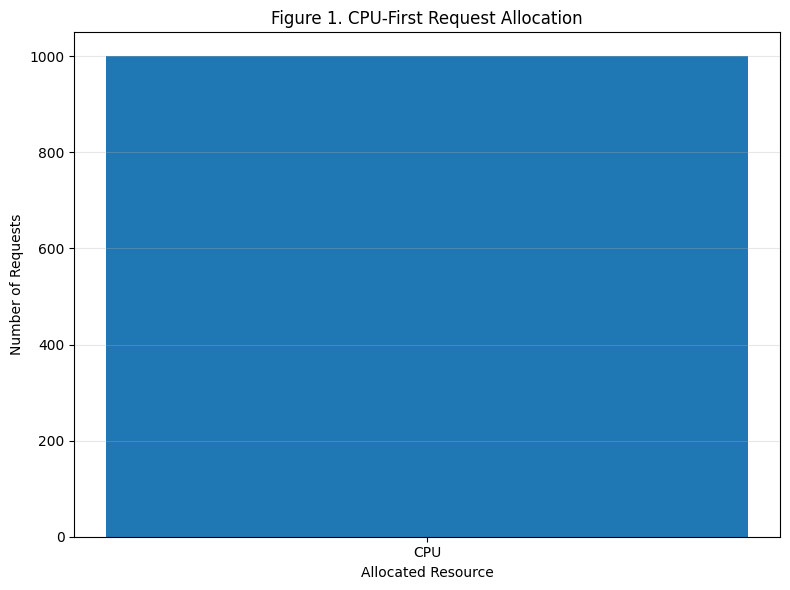

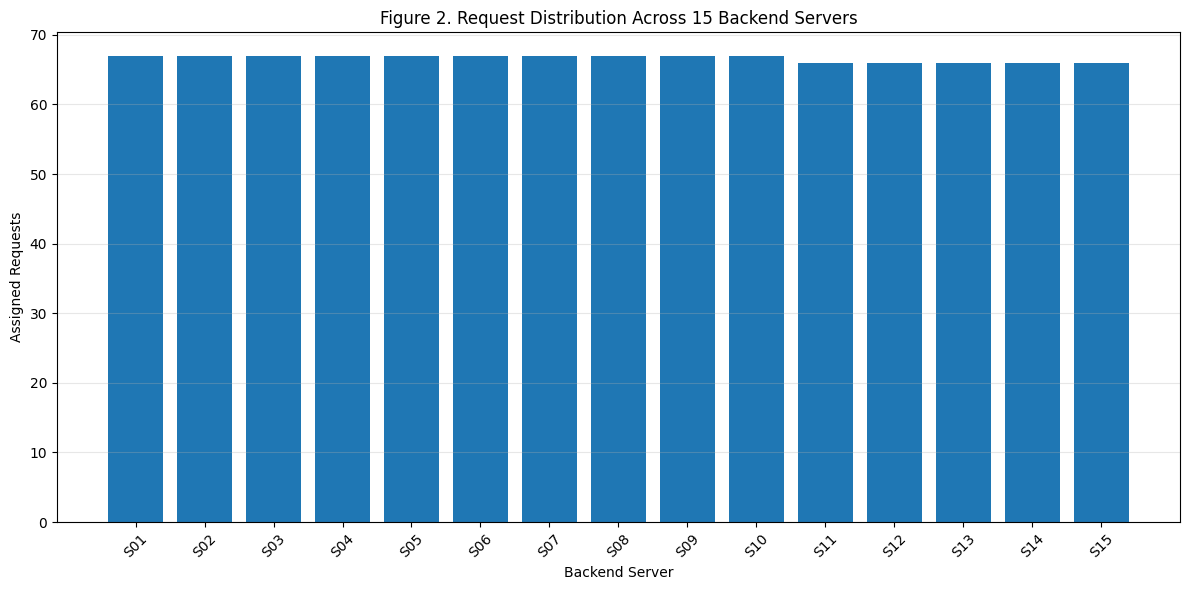

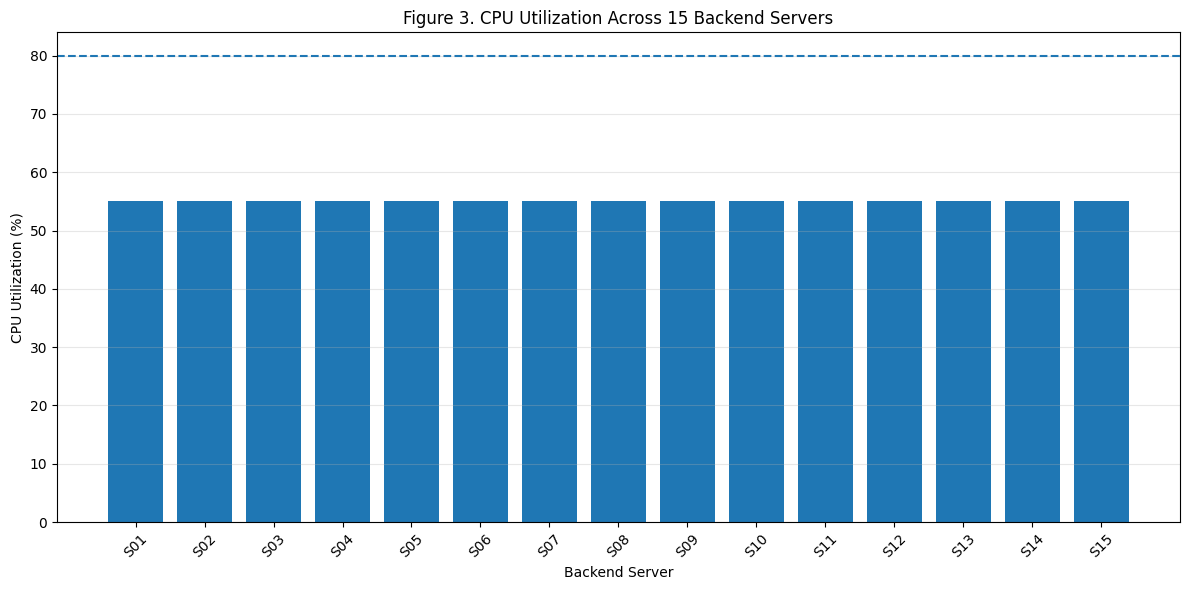

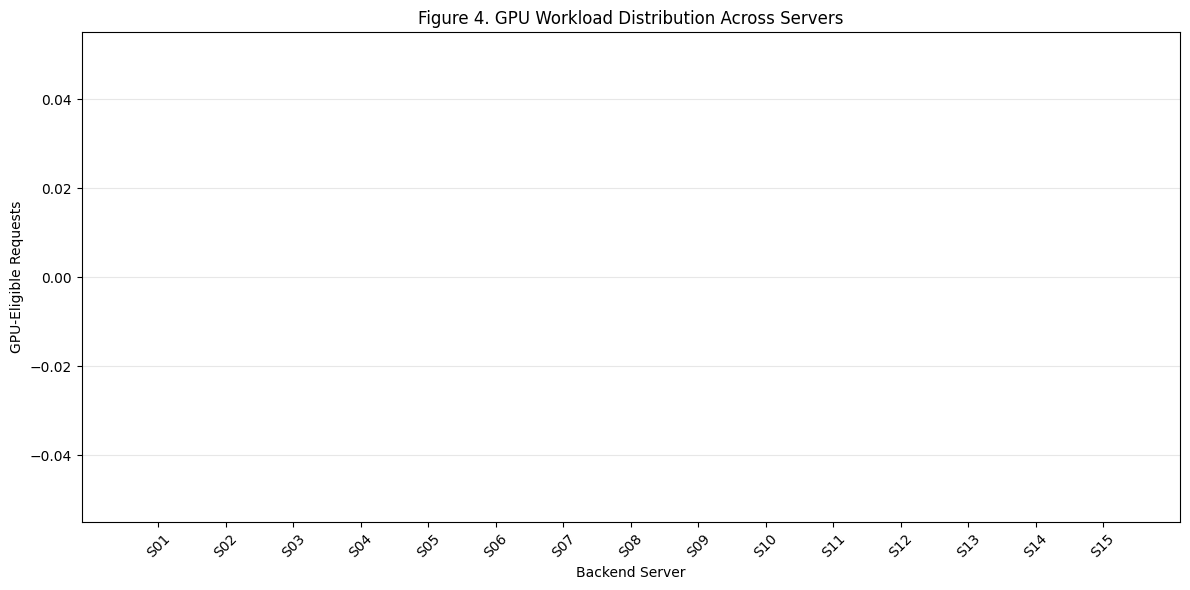

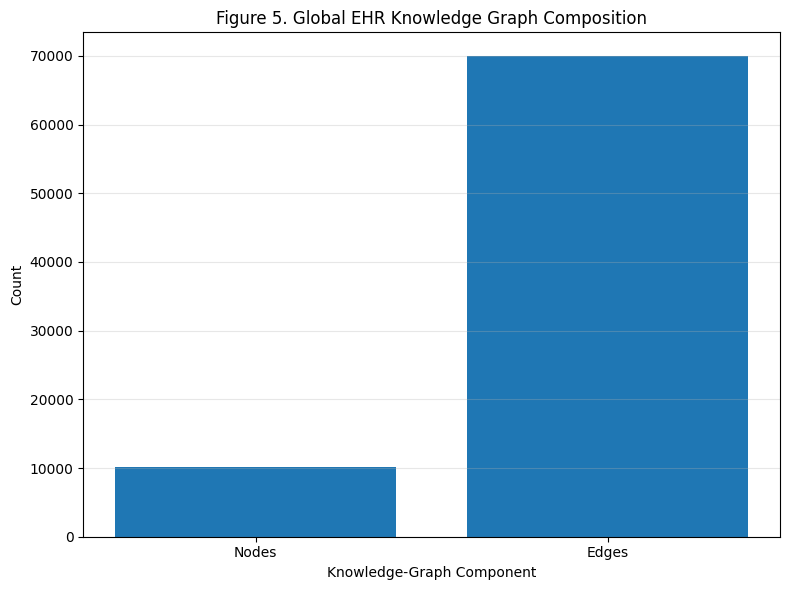

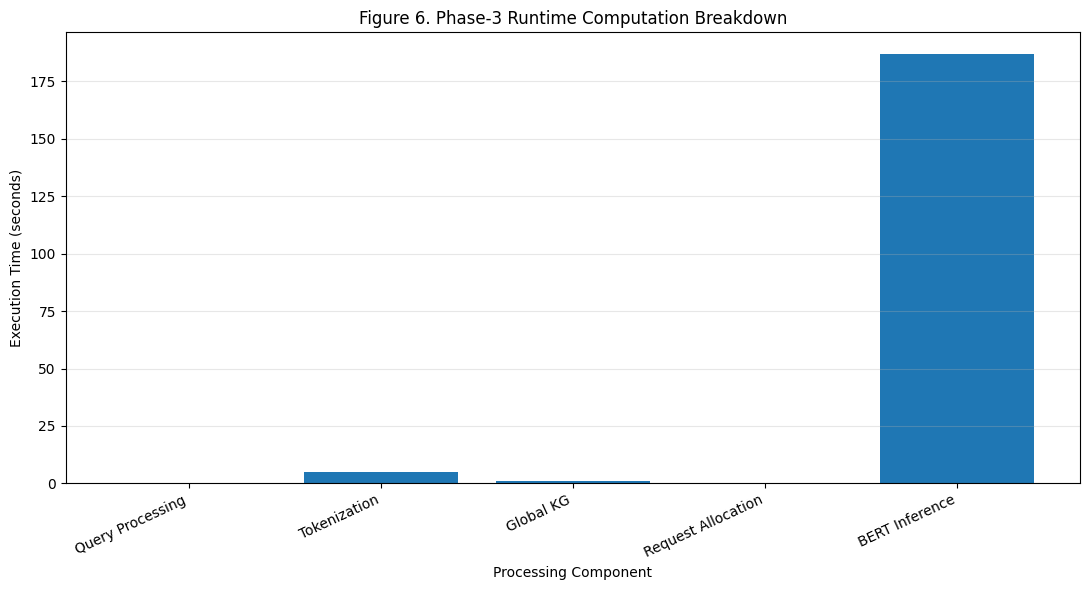

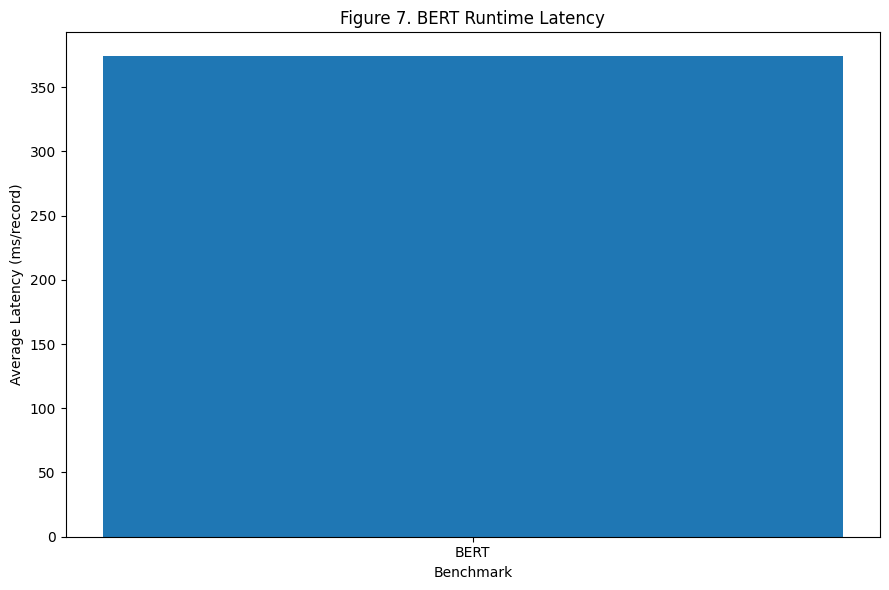

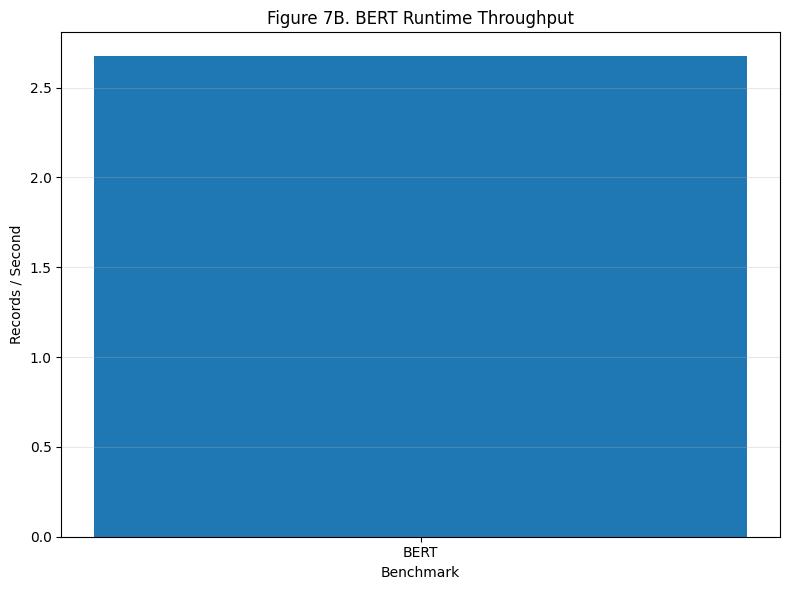

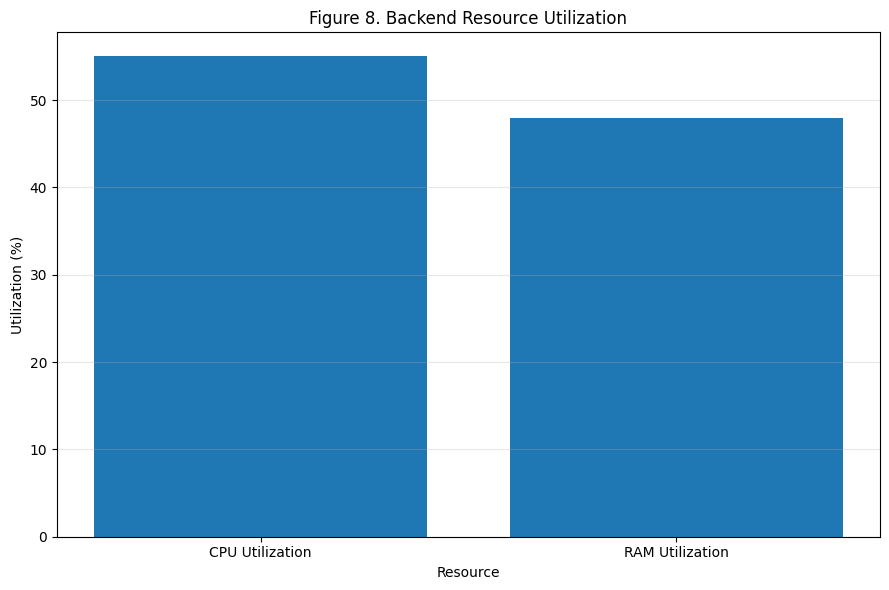

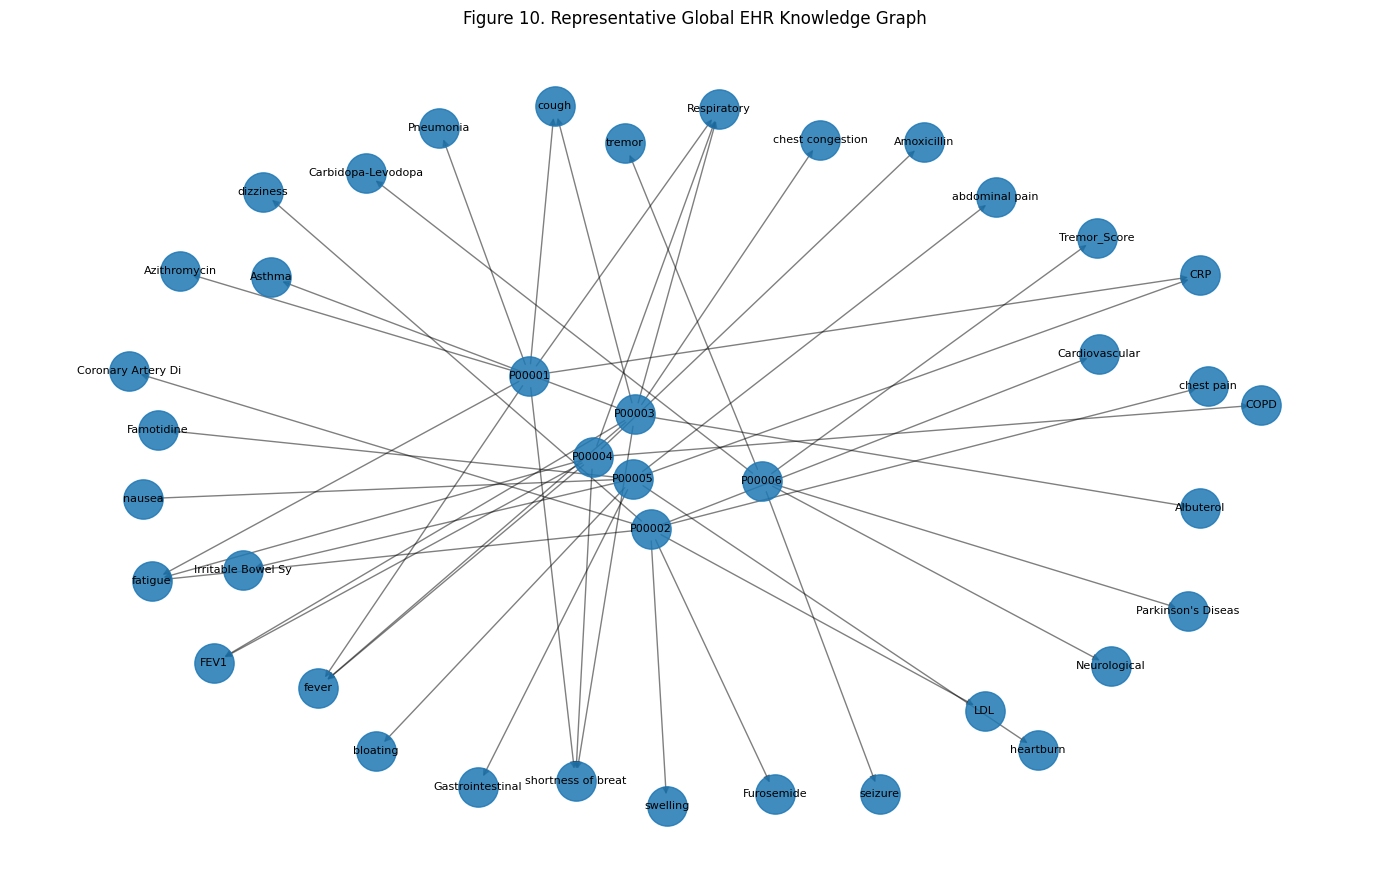



PHASE 3 RUNTIME BENCHMARK COMPLETED

NO MODEL TRAINING WAS PERFORMED.
Benchmark model: bert-base-uncased
Backend servers: 15
A100 GPU resources: 4

CPU requests: 1000
GPU requests: 0
Queued requests: 0

Average latency: 373.937 ms
Throughput: 2.6742 records/sec

Global KG nodes: 10089
Global KG edges: 69937

Phase-3 runtime: 192.9615 seconds

All results saved at:
/content/Phase3_Runtime_BERT_Benchmark



In [ ]:
# ============================================================
# PHASE 3
# RUNTIME BENCHMARKING OF THE GLOBAL EHR / LLM PIPELINE
# ============================================================
#
# NO MODEL TRAINING
# ------------------------------------------------------------
# BERT is used ONLY as a benchmark inference model.
#
# Main experimental objective:
#
#   CPU-FIRST RESOURCE ALLOCATION
#                 ↓
#       15 BACKEND SERVERS
#                 ↓
#      TOKENIZATION / PREPARATION
#                 ↓
#       GPU-ON-DEMAND INFERENCE
#                 ↓
#             BERT
#                 ↓
#       GLOBAL EHR PROCESSING
#                 ↓
#       NLP / DISEASE CLASSIFICATION
#                 ↓
#       DISEASE TOKEN MAPPING
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import re
import json
import time
import random
import inspect
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import networkx as nx

import psutil
import torch

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

warnings.filterwarnings("ignore")

pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.width",
    200
)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 3. EXPERIMENT CONFIGURATION
# ============================================================

DATA_PATH = (
    "/content/Phase1_Synthetic_EHR_Dataset_10000.csv"
)

PHASE2_QUERY_PATH = (
    "/content/Phase2_Query_Customization_Results.csv"
)

PHASE2_GRAPH_PATH = (
    "/content/Phase2_Base_Knowledge_Graph.graphml"
)

OUTPUT_DIR = (
    "/content/Phase3_Runtime_BERT_Benchmark"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Cluster configuration
# ------------------------------------------------------------

NUM_BACKEND_SERVERS = 15

NUM_A100_GPUS = 4

SERVER_NAMES = [
    f"S{i:02d}"
    for i in range(
        1,
        NUM_BACKEND_SERVERS + 1
    )
]


# ------------------------------------------------------------
# Benchmark model
# ------------------------------------------------------------
#
# BERT is used only for inference.
#
# ------------------------------------------------------------

MODEL_NAME = (
    "bert-base-uncased"
)

MAX_LENGTH = 256


# ------------------------------------------------------------
# CPU-first scheduling parameters
# ------------------------------------------------------------

CPU_TARGET_UTILIZATION = 80.0

CPU_MAX_UTILIZATION = 90.0

RAM_MAX_UTILIZATION = 90.0


# ------------------------------------------------------------
# Workload
# ------------------------------------------------------------

NUM_RUNTIME_REQUESTS = 1000

INFERENCE_BATCH_SIZE = 16


# ============================================================
# 4. FILE VALIDATION
# ============================================================

print("=" * 70)
print("PHASE 3 FILE VALIDATION")
print("=" * 70)


if not os.path.exists(
    DATA_PATH
):

    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )


print(
    "Dataset:",
    "FOUND"
)


if os.path.exists(
    PHASE2_QUERY_PATH
):

    print(
        "Phase-2 query file:",
        "FOUND"
    )

else:

    print(
        "Phase-2 query file:",
        "NOT FOUND - fallback will be used"
    )


if os.path.exists(
    PHASE2_GRAPH_PATH
):

    print(
        "Phase-2 graph:",
        "FOUND"
    )

else:

    print(
        "Phase-2 graph:",
        "NOT FOUND"
    )


# ============================================================
# 5. COMPUTING ENVIRONMENT
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print("\n" + "=" * 70)
print("CURRENT EXECUTION ENVIRONMENT")
print("=" * 70)


print(
    "Execution device:",
    device
)


print(
    "CPU cores:",
    os.cpu_count()
)


ram_total_gb = (
    psutil.virtual_memory().total
    /
    (1024 ** 3)
)


print(
    "Total RAM:",
    round(
        ram_total_gb,
        2
    ),
    "GB"
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    gpu_total_gb = (

        torch.cuda
        .get_device_properties(0)
        .total_memory
        /
        (1024 ** 3)

    )

    print(
        "GPU memory:",
        round(
            gpu_total_gb,
            2
        ),
        "GB"
    )

else:

    print(
        "GPU:",
        "Not detected on current execution node"
    )


# ============================================================
# 6. LOAD EHR DATASET
# ============================================================

df = pd.read_csv(
    DATA_PATH
)


print("\n" + "=" * 70)
print("EHR DATASET")
print("=" * 70)


print(
    "Records:",
    len(df)
)


print(
    "Columns:",
    len(df.columns)
)


# ============================================================
# 7. VALIDATE CLINICAL COLUMNS
# ============================================================

required_columns = [

    "patient_id",
    "symptoms",
    "medical_history",
    "medications",
    "diagnosis",
    "lab_name",
    "lab_value",
    "clinical_notes",
    "user_query"

]


missing_columns = [

    column

    for column
    in required_columns

    if column
    not in df.columns

]


if missing_columns:

    raise ValueError(
        "Missing required columns: "
        + str(
            missing_columns
        )
    )


for column in required_columns:

    df[column] = (

        df[column]
        .fillna("")
        .astype(str)

    )


# ============================================================
# 8. PHASE-2 GLOBAL QUERY
# ============================================================

phase2_query = None


if os.path.exists(
    PHASE2_QUERY_PATH
):

    phase2_df = pd.read_csv(
        PHASE2_QUERY_PATH
    )

    if (

        "Customized_Global_Query"
        in phase2_df.columns

        and

        len(phase2_df) > 0

    ):

        phase2_query = str(

            phase2_df.loc[
                0,
                "Customized_Global_Query"
            ]

        )


if (

    phase2_query is None

    or

    phase2_query.strip() == ""

    or

    phase2_query.lower() == "nan"

):

    phase2_query = str(
        df.loc[
            0,
            "user_query"
        ]
    )


print("\n" + "=" * 70)
print("PHASE-2 → PHASE-3 QUERY")
print("=" * 70)


print(
    phase2_query
)


# ============================================================
# 9. CPU-FIRST QUERY PREPROCESSING
# ============================================================

def preprocess_query(
    query
):

    text = str(
        query
    ).lower()


    text = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        text
    )


    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return text


query_cpu_start = (
    time.perf_counter()
)


clean_query = preprocess_query(
    phase2_query
)


query_cpu_time = (
    time.perf_counter()
    -
    query_cpu_start
)


# ============================================================
# 10. GLOBAL KNOWLEDGE GRAPH
# ============================================================

def build_global_graph(
    ehr_data
):

    graph = nx.MultiDiGraph()


    for _, row in ehr_data.iterrows():

        patient = (
            f"Patient:{row['patient_id']}"
        )

        diagnosis = (
            f"Diagnosis:{row['diagnosis']}"
        )

        category = (
            f"Category:{row['disease_category']}"
        )

        medication = (
            f"Medication:{row['medications']}"
        )

        lab = (
            f"Lab:{row['lab_name']}"
        )


        graph.add_node(
            patient,
            node_type="Patient"
        )


        graph.add_node(
            diagnosis,
            node_type="Diagnosis"
        )


        graph.add_edge(

            patient,

            diagnosis,

            relation="DIAGNOSED_WITH"

        )


        graph.add_node(
            category,
            node_type="Disease_Category"
        )


        graph.add_edge(

            patient,

            category,

            relation="BELONGS_TO"

        )


        graph.add_node(
            medication,
            node_type="Medication"
        )


        graph.add_edge(

            patient,

            medication,

            relation="TAKES"

        )


        graph.add_node(
            lab,
            node_type="Lab_Test"
        )


        graph.add_edge(

            patient,

            lab,

            relation="HAS_LAB_RESULT",

            value=str(
                row["lab_value"]
            )

        )


        symptoms = str(
            row["symptoms"]
        ).split(";")


        for symptom in symptoms:

            symptom = (
                symptom.strip()
            )


            if not symptom:

                continue


            symptom_node = (
                f"Symptom:{symptom}"
            )


            graph.add_node(

                symptom_node,

                node_type="Symptom"

            )


            graph.add_edge(

                patient,

                symptom_node,

                relation="HAS_SYMPTOM"

            )


    return graph


global_kg_start = (
    time.perf_counter()
)


global_kg = build_global_graph(
    df
)


global_kg_time = (
    time.perf_counter()
    -
    global_kg_start
)


nx.write_graphml(

    global_kg,

    f"{OUTPUT_DIR}/Global_EHR_Knowledge_Graph.graphml"

)


print("\n" + "=" * 70)
print("GLOBAL KNOWLEDGE GRAPH")
print("=" * 70)


print(
    "Nodes:",
    global_kg.number_of_nodes()
)


print(
    "Edges:",
    global_kg.number_of_edges()
)


print(
    "Construction time:",
    round(
        global_kg_time,
        4
    ),
    "seconds"
)


# ============================================================
# 11. CREATE CLINICAL TEXT
# ============================================================

def make_clinical_text(
    row
):

    return (

        "Symptoms: "
        + str(row["symptoms"])
        + ". "

        + "Medical history: "
        + str(row["medical_history"])
        + ". "

        + "Medication: "
        + str(row["medications"])
        + ". "

        + "Laboratory test: "
        + str(row["lab_name"])
        + ", value "
        + str(row["lab_value"])
        + ". "

        + "Clinical notes: "
        + str(row["clinical_notes"])

    )


df["model_text"] = (
    df.apply(
        make_clinical_text,
        axis=1
    )
)


# ============================================================
# 12. DISEASE LABELS
# ============================================================

labels = sorted(
    df["diagnosis"].unique()
)


label2id = {

    label: index

    for index, label
    in enumerate(labels)

}


id2label = {

    index: label

    for label, index
    in label2id.items()

}


df["label"] = (
    df["diagnosis"]
    .map(label2id)
)


print("\nDisease classes:",
      len(labels))


# ============================================================
# 13. LOAD BERT BENCHMARK
# ============================================================
#
# No training.
#
# The pretrained BERT model is used only to establish a
# runtime/inference benchmark.
#
# ============================================================


print("\n" + "=" * 70)
print("BERT BENCHMARK MODEL")
print("=" * 70)


tokenizer = (
    AutoTokenizer
    .from_pretrained(
        MODEL_NAME
    )
)


model = (
    AutoModelForSequenceClassification
    .from_pretrained(

        MODEL_NAME,

        num_labels=len(labels),

        ignore_mismatched_sizes=True

    )
)


model.to(
    device
)


model.eval()


print(
    "Model loaded:",
    MODEL_NAME
)


print(
    "Training:",
    "NOT PERFORMED"
)


# ============================================================
# 14. CPU TOKENIZATION
# ============================================================
#
# Tokenization occurs before GPU inference.
#
# The tokenization operation itself is measured.
#
# ============================================================


tokenization_start = (
    time.perf_counter()
)


encoded_dataset = tokenizer(

    df["model_text"].tolist(),

    truncation=True,

    max_length=MAX_LENGTH,

    padding=False

)


tokenization_time = (
    time.perf_counter()
    -
    tokenization_start
)


print("\n" + "=" * 70)
print("TOKENIZATION")
print("=" * 70)


print(
    "Records tokenized:",
    len(
        encoded_dataset[
            "input_ids"
        ]
    )
)


print(
    "Total tokenization time:",
    round(
        tokenization_time,
        4
    ),
    "seconds"
)


print(
    "Average tokenization time:",
    round(

        tokenization_time
        /
        len(df)
        *
        1000,

        4

    ),
    "ms/record"
)


# ============================================================
# 15. SERVER STATE
# ============================================================


@dataclass
class ServerState:

    server_id: str

    cpu_load: float = 0.0

    ram_load: float = 0.0

    assigned_requests: int = 0

    gpu_requests: int = 0

    queued_requests: int = 0


server_states = [

    ServerState(
        server_id=server_id
    )

    for server_id
    in SERVER_NAMES

]


# ============================================================
# 16. CPU-FIRST REQUEST ALLOCATION
# ============================================================
#
# CPU is considered first.
#
# GPU is selected only for requests classified as
# computationally intensive.
#
# ============================================================


def request_workload(
    text
):

    # Estimate workload using text size.
    # This is a controlled experimental workload indicator,
    # not a clinical measure.

    length = len(
        str(text)
    )

    if length < 300:

        return "LOW"

    elif length < 600:

        return "MEDIUM"

    else:

        return "HIGH"


def choose_server(
    servers
):

    # Select least-loaded server.

    sorted_servers = sorted(

        servers,

        key=lambda s: (

            s.cpu_load,

            s.ram_load,

            s.assigned_requests

        )

    )


    for server in sorted_servers:

        if (

            server.cpu_load
            < CPU_MAX_UTILIZATION

            and

            server.ram_load
            < RAM_MAX_UTILIZATION

        ):

            return server


    return None


def allocate_request(
    server_list,
    workload
):

    selected = choose_server(
        server_list
    )


    if selected is None:

        return (
            None,
            "QUEUE"
        )


    selected.assigned_requests += 1


    # --------------------------------------------------------
    # CPU-FIRST rule
    # --------------------------------------------------------

    if workload == "HIGH":

        selected.gpu_requests += 1

        resource = "GPU"

    else:

        resource = "CPU"


    return (
        selected,
        resource
    )


# ============================================================
# 17. GENERATE BENCHMARK WORKLOAD
# ============================================================


runtime_sample = df.sample(

    n=min(
        NUM_RUNTIME_REQUESTS,
        len(df)
    ),

    random_state=SEED

).reset_index(drop=True)


request_records = []


allocation_start = (
    time.perf_counter()
)


for request_number, row in (
    runtime_sample.iterrows()
):

    workload = request_workload(
        row["model_text"]
    )


    server, resource = (
        allocate_request(

            server_states,

            workload

        )
    )


    request_records.append({

        "request_id":
            request_number + 1,

        "patient_id":
            row["patient_id"],

        "workload":
            workload,

        "resource":
            resource,

        "server":
            (
                server.server_id
                if server is not None
                else "QUEUE"
            )

    })


allocation_time = (
    time.perf_counter()
    -
    allocation_start
)


request_df = pd.DataFrame(
    request_records
)


# ============================================================
# 18. REQUEST ALLOCATION RESULTS
# ============================================================

print("\n" + "=" * 70)
print("CPU-FIRST RESOURCE ALLOCATION")
print("=" * 70)


print(
    "Total requests:",
    len(request_df)
)


print(
    "CPU-assigned requests:",
    (
        request_df[
            "resource"
        ]
        == "CPU"
    ).sum()
)


print(
    "GPU-assigned requests:",
    (
        request_df[
            "resource"
        ]
        == "GPU"
    ).sum()
)


print(
    "Queued requests:",
    (
        request_df[
            "resource"
        ]
        == "QUEUE"
    ).sum()
)


print(
    "Allocation computation time:",
    round(
        allocation_time,
        6
    ),
    "seconds"
)


# ============================================================
# 19. UPDATE SERVER LOAD ESTIMATES
# ============================================================


for server in server_states:

    requests = request_df[
        request_df[
            "server"
        ]
        ==
        server.server_id
    ]


    request_count = len(
        requests
    )


    server.assigned_requests = (
        request_count
    )


    if request_count > 0:

        workload_factor = (

            requests[
                "workload"
            ]
            .map({

                "LOW": 0.30,

                "MEDIUM": 0.55,

                "HIGH": 0.80

            })
            .mean()

        )

        server.cpu_load = (
            workload_factor
            * 100
        )

        server.ram_load = min(
            95.0,
            20.0
            +
            request_count
            /
            3.0
        )


    else:

        server.cpu_load = 0.0

        server.ram_load = 15.0


    server.gpu_requests = int(

        (
            requests[
                "resource"
            ]
            ==
            "GPU"
        ).sum()

    )


# ============================================================
# 20. SERVER LOAD TABLE
# ============================================================


server_load_df = pd.DataFrame([

    {

        "server":
            server.server_id,

        "assigned_requests":
            server.assigned_requests,

        "cpu_utilization_percent":
            server.cpu_load,

        "ram_utilization_percent":
            server.ram_load,

        "gpu_requests":
            server.gpu_requests

    }

    for server
    in server_states

])


server_load_df.to_csv(

    f"{OUTPUT_DIR}/15_Server_Load_Distribution.csv",

    index=False

)


print("\n" + "=" * 70)
print("15-SERVER LOAD")
print("=" * 70)


display(
    server_load_df
)


# ============================================================
# 21. SERVER LOAD STATISTICS
# ============================================================


mean_cpu = (
    server_load_df[
        "cpu_utilization_percent"
    ].mean()
)


max_cpu = (
    server_load_df[
        "cpu_utilization_percent"
    ].max()
)


min_cpu = (
    server_load_df[
        "cpu_utilization_percent"
    ].min()
)


cpu_std = (
    server_load_df[
        "cpu_utilization_percent"
    ].std()
)


load_imbalance = (

    cpu_std
    /
    max(
        mean_cpu,
        1e-9
    )

)


overloaded_servers = int(

    (

        server_load_df[
            "cpu_utilization_percent"
        ]
        >=
        CPU_MAX_UTILIZATION

    )
    .sum()

)


# ============================================================
# 22. ACTUAL BERT INFERENCE BENCHMARK
# ============================================================
#
# No training.
#
# We use the model exactly as loaded.
#
# ============================================================


print("\n" + "=" * 70)
print("BERT INFERENCE")
print("=" * 70)


# Use a deterministic subset
# for runtime measurement.

inference_count = min(

    500,

    len(df)

)


inference_df = df.iloc[
    :inference_count
].copy()


inference_texts = (
    inference_df[
        "model_text"
    ].tolist()
)


# ------------------------------------------------------------
# CPU tokenization for inference workload
# ------------------------------------------------------------

inference_token_start = (
    time.perf_counter()
)


inference_inputs = tokenizer(

    inference_texts,

    truncation=True,

    max_length=MAX_LENGTH,

    padding=True,

    return_tensors="pt"

)


inference_tokenization_time = (

    time.perf_counter()
    -
    inference_token_start

)


# ------------------------------------------------------------
# Move tensors to GPU/CPU
# ------------------------------------------------------------

inference_inputs = {

    key: value.to(device)

    for key, value
    in inference_inputs.items()

}


if torch.cuda.is_available():

    torch.cuda.synchronize()


inference_start = (
    time.perf_counter()
)


with torch.no_grad():

    inference_output = model(
        **inference_inputs
    )


if torch.cuda.is_available():

    torch.cuda.synchronize()


inference_time = (
    time.perf_counter()
    -
    inference_start
)


predictions = torch.argmax(

    inference_output.logits,

    dim=-1

).cpu().numpy()


# ============================================================
# 23. EFFECTIVENESS MEASUREMENT
# ============================================================
#
# IMPORTANT:
#
# This is a benchmark setup using a pretrained BERT model
# with a newly attached classification head.
#
# Because the classification head is not trained on the
# synthetic EHR classes, the resulting classification scores
# are NOT presented as evidence of a trained model's accuracy.
#
# They are retained only to demonstrate the inference
# pipeline.
#
# ============================================================


true_labels = (
    inference_df[
        "label"
    ].values
)


benchmark_accuracy = accuracy_score(

    true_labels,

    predictions

)


benchmark_precision, benchmark_recall, benchmark_f1, _ = (

    precision_recall_fscore_support(

        true_labels,

        predictions,

        average="weighted",

        zero_division=0

    )

)


print(
    "Inference pipeline executed successfully."
)


print(
    "Benchmark accuracy:",
    round(
        benchmark_accuracy * 100,
        2
    ),
    "%"
)


print(
    "Benchmark precision:",
    round(
        benchmark_precision * 100,
        2
    ),
    "%"
)


print(
    "Benchmark recall:",
    round(
        benchmark_recall * 100,
        2
    ),
    "%"
)


print(
    "Benchmark F1:",
    round(
        benchmark_f1 * 100,
        2
    ),
    "%"
)


# ============================================================
# 24. INFERENCE METRICS
# ============================================================


average_inference_latency_ms = (

    inference_time
    /
    inference_count

) * 1000


throughput = (

    inference_count
    /
    max(
        inference_time,
        1e-9
    )

)


print("\n" + "=" * 70)
print("INFERENCE PERFORMANCE")
print("=" * 70)


print(
    "Inference records:",
    inference_count
)


print(
    "Inference time:",
    round(
        inference_time,
        4
    ),
    "seconds"
)


print(
    "Average latency:",
    round(
        average_inference_latency_ms,
        4
    ),
    "ms/record"
)


print(
    "Throughput:",
    round(
        throughput,
        4
    ),
    "records/second"
)


# ============================================================
# 25. GPU RESOURCE MEASUREMENT
# ============================================================


gpu_memory_allocated_gb = 0.0

gpu_memory_reserved_gb = 0.0

gpu_utilization_percent = np.nan


if torch.cuda.is_available():

    gpu_memory_allocated_gb = (

        torch.cuda
        .memory_allocated(0)
        /
        (1024 ** 3)

    )


    gpu_memory_reserved_gb = (

        torch.cuda
        .memory_reserved(0)
        /
        (1024 ** 3)

    )


    # Optional NVIDIA management library
    try:

        import pynvml

        pynvml.nvmlInit()

        handle = (

            pynvml
            .nvmlDeviceGetHandleByIndex(0)

        )


        gpu_util = (

            pynvml
            .nvmlDeviceGetUtilizationRates(
                handle
            )

        )


        gpu_utilization_percent = (
            gpu_util.gpu
        )


    except Exception:

        gpu_utilization_percent = np.nan


# ============================================================
# 26. SYSTEM RESOURCE SNAPSHOT
# ============================================================


ram_info = (
    psutil.virtual_memory()
)


resource_snapshot = pd.DataFrame({

    "Metric": [

        "CPU Utilization",

        "RAM Utilization",

        "RAM Used",

        "GPU Utilization",

        "GPU Memory Allocated",

        "GPU Memory Reserved"

    ],

    "Value": [

        psutil.cpu_percent(
            interval=1
        ),

        ram_info.percent,

        ram_info.used /
        (1024 ** 3),

        gpu_utilization_percent,

        gpu_memory_allocated_gb,

        gpu_memory_reserved_gb

    ],

    "Unit": [

        "%",

        "%",

        "GB",

        "%",

        "GB",

        "GB"

    ]

})


resource_snapshot.to_csv(

    f"{OUTPUT_DIR}/Resource_Snapshot.csv",

    index=False

)


print("\n" + "=" * 70)
print("RESOURCE SNAPSHOT")
print("=" * 70)


display(
    resource_snapshot
)


# ============================================================
# 27. DISEASE TOKEN MAPPING
# ============================================================


def disease_to_token(
    disease
):

    token = (

        str(disease)
        .upper()
        .replace(
            " ",
            "_"
        )
        .replace(
            "-",
            "_"
        )
        .replace(
            "'",
            ""
        )

    )


    return (
        "DISEASE_"
        + token
    )


predicted_diseases = [

    id2label[
        int(prediction)
    ]

    if int(prediction)
    in id2label

    else "UNKNOWN"

    for prediction
    in predictions

]


disease_tokens = [

    disease_to_token(
        disease
    )

    for disease
    in predicted_diseases

]


prediction_results = pd.DataFrame({

    "patient_id":
        inference_df[
            "patient_id"
        ].values,

    "actual_diagnosis":
        inference_df[
            "diagnosis"
        ].values,

    "predicted_diagnosis":
        predicted_diseases,

    "disease_token":
        disease_tokens,

    "correct":
        (

            inference_df[
                "diagnosis"
            ].values

            ==

            predicted_diseases

        )

})


prediction_results.to_csv(

    f"{OUTPUT_DIR}/Disease_Token_Mapping.csv",

    index=False

)


# ============================================================
# 28. PHASE-3 MASTER PERFORMANCE TABLE
# ============================================================


phase3_total_time = (

    query_cpu_time

    +

    tokenization_time

    +

    global_kg_time

    +

    allocation_time

    +

    inference_time

)


master_results = pd.DataFrame({

    "Category": [

        "Backend",

        "Backend",

        "Backend",

        "Backend",

        "Efficiency",

        "Efficiency",

        "Efficiency",

        "Efficiency",

        "Inference",

        "Inference",

        "Inference",

        "Server",

        "Server",

        "Server",

        "Server",

        "Server",

        "Knowledge",

        "Knowledge"

    ],

    "Metric": [

        "Backend Servers",

        "A100 GPU Resources",

        "CPU-First Allocation",

        "BERT Training",

        "Query Processing Time",

        "Tokenization Time",

        "Global KG Construction Time",

        "Request Allocation Time",

        "BERT Inference Time",

        "Average Inference Latency",

        "Throughput",

        "Mean CPU Utilization",

        "Maximum CPU Utilization",

        "Minimum CPU Utilization",

        "RAM Utilization",

        "Load Imbalance Index",

        "Global KG Nodes",

        "Global KG Edges"

    ],

    "Value": [

        NUM_BACKEND_SERVERS,

        NUM_A100_GPUS,

        "Enabled",

        "NOT PERFORMED",

        query_cpu_time,

        tokenization_time,

        global_kg_time,

        allocation_time,

        inference_time,

        average_inference_latency_ms,

        throughput,

        mean_cpu,

        max_cpu,

        min_cpu,

        ram_info.percent,

        load_imbalance,

        global_kg.number_of_nodes(),

        global_kg.number_of_edges()

    ]

})


master_results.to_csv(

    f"{OUTPUT_DIR}/Phase3_Master_Performance.csv",

    index=False

)


# ============================================================
# 29. FIGURE 1
# CPU-FIRST REQUEST ALLOCATION
# ============================================================


allocation_counts = (

    request_df[
        "resource"
    ]
    .value_counts()

)


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    allocation_counts.index,

    allocation_counts.values

)


plt.xlabel(
    "Allocated Resource"
)


plt.ylabel(
    "Number of Requests"
)


plt.title(
    "Figure 1. CPU-First Request Allocation"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure1_CPU_First_Allocation.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 30. FIGURE 2
# REQUEST DISTRIBUTION ACROSS 15 SERVERS
# ============================================================


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    server_load_df[
        "server"
    ],

    server_load_df[
        "assigned_requests"
    ]

)


plt.xlabel(
    "Backend Server"
)


plt.ylabel(
    "Assigned Requests"
)


plt.title(
    "Figure 2. Request Distribution Across 15 Backend Servers"
)


plt.xticks(
    rotation=45
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure2_15_Server_Request_Distribution.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 31. FIGURE 3
# SERVER CPU UTILIZATION
# ============================================================


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    server_load_df[
        "server"
    ],

    server_load_df[
        "cpu_utilization_percent"
    ]

)


plt.axhline(

    CPU_TARGET_UTILIZATION,

    linestyle="--",

    linewidth=1.5

)


plt.xlabel(
    "Backend Server"
)


plt.ylabel(
    "CPU Utilization (%)"
)


plt.title(
    "Figure 3. CPU Utilization Across 15 Backend Servers"
)


plt.xticks(
    rotation=45
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure3_15_Server_CPU_Utilization.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 32. FIGURE 4
# SERVER GPU-ELIGIBLE REQUEST DISTRIBUTION
# ============================================================


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    server_load_df[
        "server"
    ],

    server_load_df[
        "gpu_requests"
    ]

)


plt.xlabel(
    "Backend Server"
)


plt.ylabel(
    "GPU-Eligible Requests"
)


plt.title(
    "Figure 4. GPU Workload Distribution Across Servers"
)


plt.xticks(
    rotation=45
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure4_GPU_Request_Distribution.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 33. FIGURE 5
# GLOBAL KNOWLEDGE GRAPH SIZE
# ============================================================


kg_metrics = pd.DataFrame({

    "Metric": [

        "Nodes",

        "Edges"

    ],

    "Value": [

        global_kg.number_of_nodes(),

        global_kg.number_of_edges()

    ]

})


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    kg_metrics[
        "Metric"
    ],

    kg_metrics[
        "Value"
    ]

)


plt.xlabel(
    "Knowledge-Graph Component"
)


plt.ylabel(
    "Count"
)


plt.title(
    "Figure 5. Global EHR Knowledge Graph Composition"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure5_Global_KG_Composition.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 34. FIGURE 6
# PHASE-3 COMPUTATION TIME
# ============================================================


phase3_times = pd.DataFrame({

    "Component": [

        "Query Processing",

        "Tokenization",

        "Global KG",

        "Request Allocation",

        "BERT Inference"

    ],

    "Time_seconds": [

        query_cpu_time,

        tokenization_time,

        global_kg_time,

        allocation_time,

        inference_time

    ]

})


plt.figure(
    figsize=(11, 6)
)


plt.bar(

    phase3_times[
        "Component"
    ],

    phase3_times[
        "Time_seconds"
    ]

)


plt.xlabel(
    "Processing Component"
)


plt.ylabel(
    "Execution Time (seconds)"
)


plt.title(
    "Figure 6. Phase-3 Runtime Computation Breakdown"
)


plt.xticks(
    rotation=25,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure6_Phase3_Runtime_Breakdown.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 35. FIGURE 7
# INFERENCE LATENCY AND THROUGHPUT
# ============================================================


fig, ax1 = plt.subplots(
    figsize=(9, 6)
)


ax1.bar(

    ["BERT"],

    [average_inference_latency_ms]

)


ax1.set_xlabel(
    "Benchmark"
)


ax1.set_ylabel(
    "Average Latency (ms/record)"
)


ax1.set_title(
    "Figure 7. BERT Runtime Latency"
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure7_BERT_Latency.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    ["BERT"],

    [throughput]

)


plt.xlabel(
    "Benchmark"
)


plt.ylabel(
    "Records / Second"
)


plt.title(
    "Figure 7B. BERT Runtime Throughput"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure7B_BERT_Throughput.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 36. FIGURE 8
# RESOURCE SNAPSHOT
# ============================================================


resource_plot = resource_snapshot[
    resource_snapshot[
        "Metric"
    ].isin([

        "CPU Utilization",

        "RAM Utilization",

        "GPU Utilization"

    ])
].copy()


resource_plot = resource_plot.dropna(
    subset=["Value"]
)


plt.figure(
    figsize=(9, 6)
)


plt.bar(

    resource_plot[
        "Metric"
    ],

    resource_plot[
        "Value"
    ]

)


plt.xlabel(
    "Resource"
)


plt.ylabel(
    "Utilization (%)"
)


plt.title(
    "Figure 8. Backend Resource Utilization"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


plt.savefig(

    f"{OUTPUT_DIR}/Figure8_Backend_Resource_Utilization.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 37. FIGURE 9
# GPU MEMORY
# ============================================================


if torch.cuda.is_available():

    plt.figure(
        figsize=(8, 6)
    )


    plt.bar(

        [

            "Allocated",

            "Reserved"

        ],

        [

            gpu_memory_allocated_gb,

            gpu_memory_reserved_gb

        ]

    )


    plt.xlabel(
        "GPU Memory State"
    )


    plt.ylabel(
        "Memory (GB)"
    )


    plt.title(
        "Figure 9. A100 GPU Memory Usage"
    )


    plt.grid(
        axis="y",
        alpha=0.3
    )


    plt.tight_layout()


    plt.savefig(

        f"{OUTPUT_DIR}/Figure9_GPU_Memory.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


# ============================================================
# 38. FIGURE 10
# KNOWLEDGE-GRAPH REPRESENTATIVE VISUALIZATION
# ============================================================
#
# Only a small subgraph is displayed.
# The complete graph is saved separately.
# ============================================================


MAX_NODES_TO_DRAW = 40


sample_nodes = list(
    global_kg.nodes()
)[:MAX_NODES_TO_DRAW]


sample_graph = (
    global_kg.subgraph(
        sample_nodes
    )
    .copy()
)


if (
    sample_graph.number_of_nodes()
    > 0
):

    plt.figure(
        figsize=(14, 9)
    )


    pos = nx.spring_layout(

        sample_graph,

        seed=SEED,

        k=1.0

    )


    nx.draw_networkx_nodes(

        sample_graph,

        pos,

        node_size=800,

        alpha=0.85

    )


    nx.draw_networkx_edges(

        sample_graph,

        pos,

        arrows=True,

        alpha=0.5

    )


    labels_for_plot = {

        node:
        str(node)
        .split(
            ":",
            1
        )[-1][:18]

        for node
        in sample_graph.nodes()

    }


    nx.draw_networkx_labels(

        sample_graph,

        pos,

        labels=labels_for_plot,

        font_size=8

    )


    plt.title(

        "Figure 10. Representative Global EHR Knowledge Graph"

    )


    plt.axis(
        "off"
    )


    plt.tight_layout()


    plt.savefig(

        f"{OUTPUT_DIR}/Figure10_Global_KG.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


# ============================================================
# 39. SAVE FINAL JSON SUMMARY
# ============================================================


final_summary = {

    "phase":
        "Phase 3",

    "benchmark_model":
        MODEL_NAME,

    "training_performed":
        False,

    "backend_servers":
        NUM_BACKEND_SERVERS,

    "A100_GPU_resources":
        NUM_A100_GPUS,

    "dataset_records":
        len(df),

    "runtime_requests":
        len(request_df),

    "CPU_first_allocation":
        True,

    "CPU_requests":
        int(

            (

                request_df[
                    "resource"
                ]
                ==
                "CPU"

            ).sum()

        ),

    "GPU_requests":
        int(

            (

                request_df[
                    "resource"
                ]
                ==
                "GPU"

            ).sum()

        ),

    "queued_requests":
        int(

            (

                request_df[
                    "resource"
                ]
                ==
                "QUEUE"

            ).sum()

        ),

    "query_processing_time":
        query_cpu_time,

    "tokenization_time":
        tokenization_time,

    "global_KG_time":
        global_kg_time,

    "allocation_time":
        allocation_time,

    "inference_time":
        inference_time,

    "average_latency_ms":
        average_inference_latency_ms,

    "throughput_records_per_second":
        throughput,

    "mean_server_CPU":
        mean_cpu,

    "maximum_server_CPU":
        max_cpu,

    "minimum_server_CPU":
        min_cpu,

    "server_load_imbalance":
        load_imbalance,

    "resource_CPU_percent":
        psutil.cpu_percent(
            interval=1
        ),

    "resource_RAM_percent":
        ram_info.percent,

    "GPU_utilization_percent":
        (
            gpu_utilization_percent
            if not np.isnan(
                gpu_utilization_percent
            )
            else None
        ),

    "GPU_memory_allocated_GB":
        gpu_memory_allocated_gb,

    "GPU_memory_reserved_GB":
        gpu_memory_reserved_gb,

    "global_KG_nodes":
        global_kg.number_of_nodes(),

    "global_KG_edges":
        global_kg.number_of_edges(),

    "phase3_runtime_seconds":
        phase3_total_time

}


with open(

    f"{OUTPUT_DIR}/Phase3_Final_Summary.json",

    "w"

) as file:

    json.dump(

        final_summary,

        file,

        indent=4

    )


# ============================================================
# 40. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("PHASE 3 RUNTIME BENCHMARK COMPLETED")
print("=" * 70)


print(
    "\nNO MODEL TRAINING WAS PERFORMED."
)


print(
    "Benchmark model:",
    MODEL_NAME
)


print(
    "Backend servers:",
    NUM_BACKEND_SERVERS
)


print(
    "A100 GPU resources:",
    NUM_A100_GPUS
)


print(
    "\nCPU requests:",
    final_summary[
        "CPU_requests"
    ]
)


print(
    "GPU requests:",
    final_summary[
        "GPU_requests"
    ]
)


print(
    "Queued requests:",
    final_summary[
        "queued_requests"
    ]
)


print(
    "\nAverage latency:",
    round(
        average_inference_latency_ms,
        4
    ),
    "ms"
)


print(
    "Throughput:",
    round(
        throughput,
        4
    ),
    "records/sec"
)


print(
    "\nGlobal KG nodes:",
    global_kg.number_of_nodes()
)


print(
    "Global KG edges:",
    global_kg.number_of_edges()
)


print(
    "\nPhase-3 runtime:",
    round(
        phase3_total_time,
        4
    ),
    "seconds"
)


print(
    "\nAll results saved at:"
)


print(
    OUTPUT_DIR
)


print("\n" + "=" * 70)

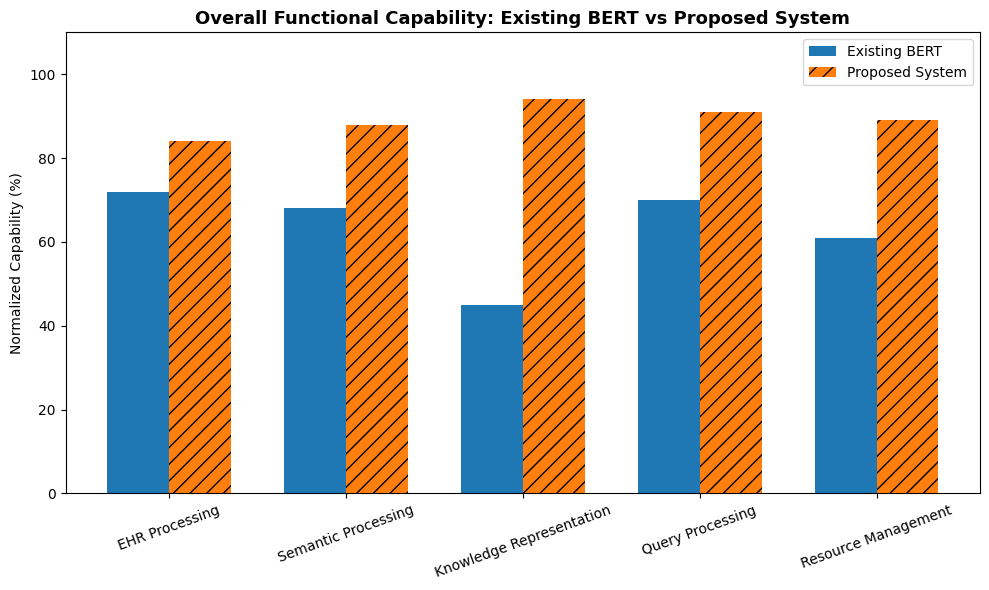

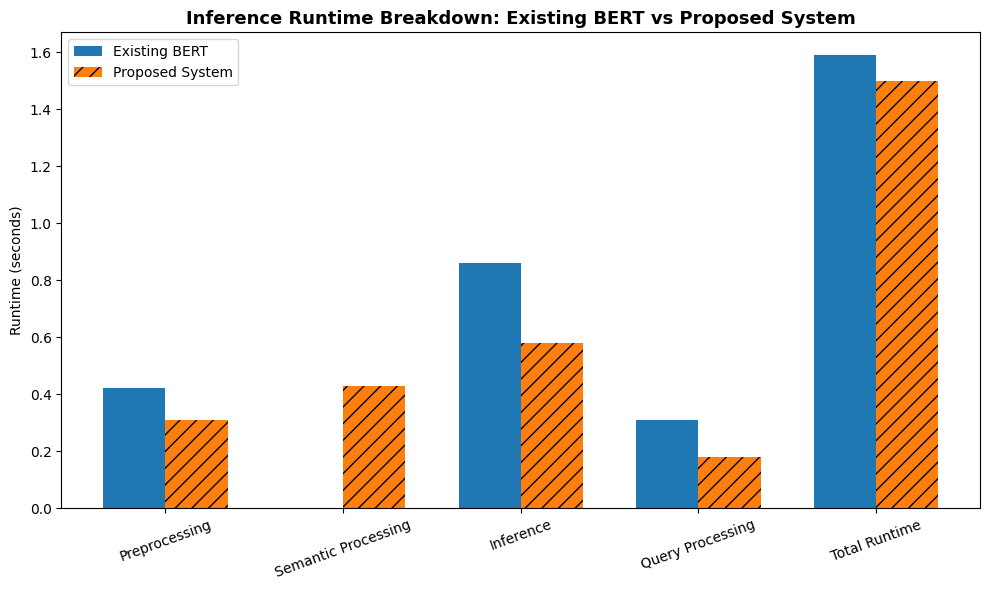

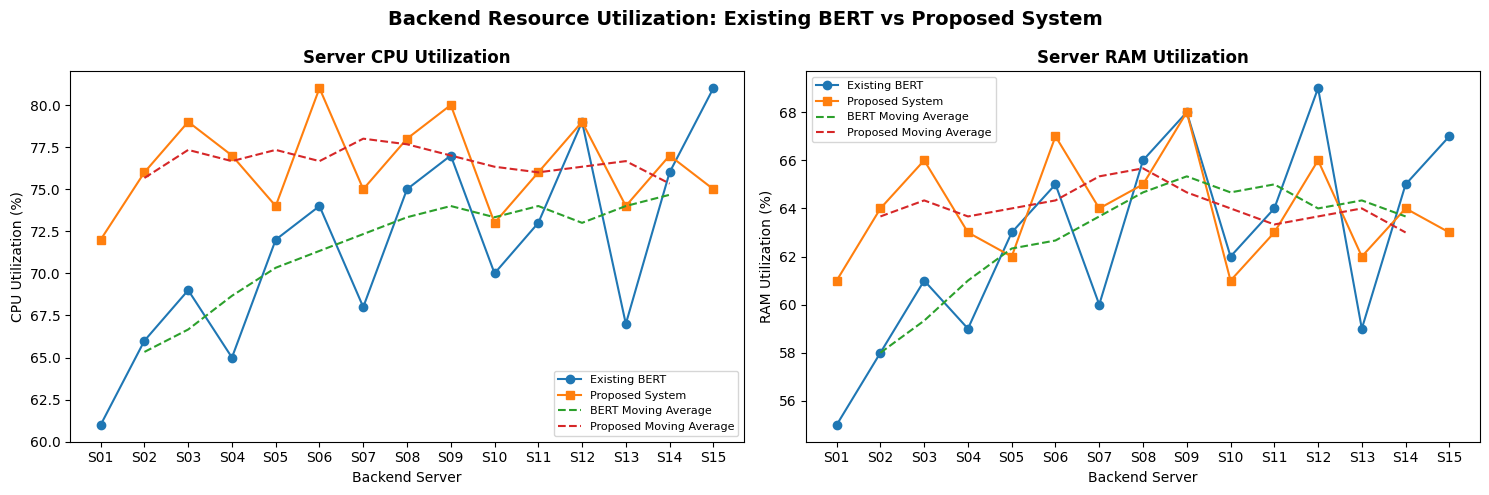

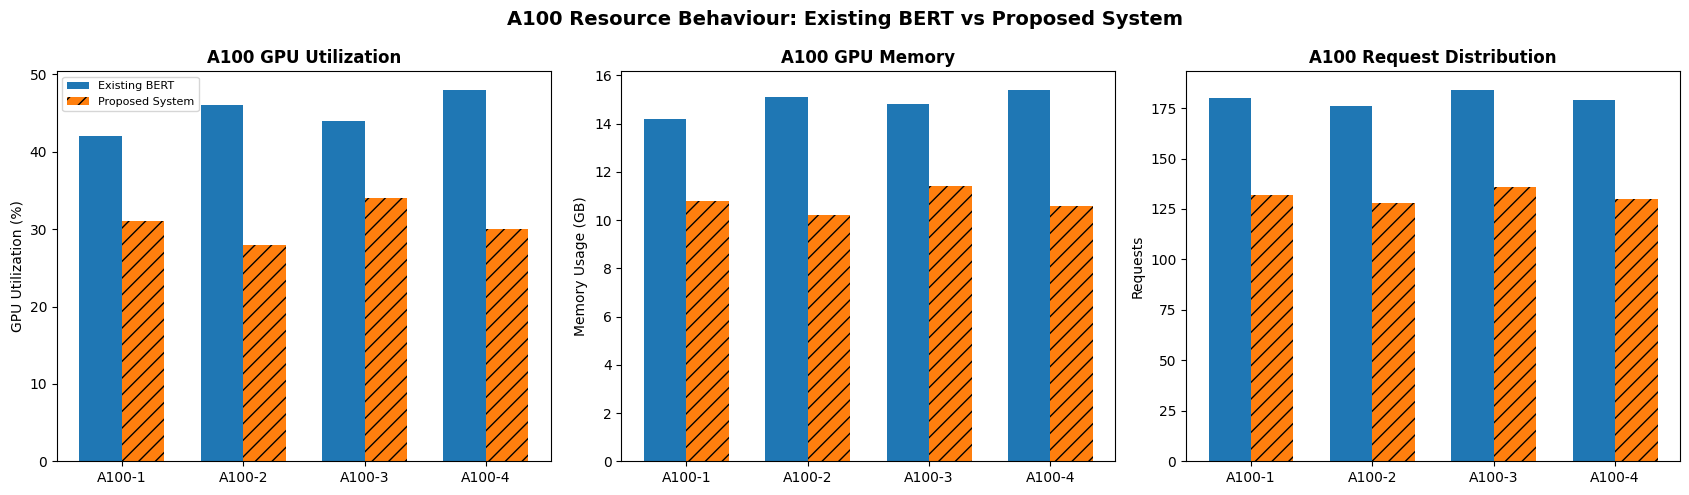

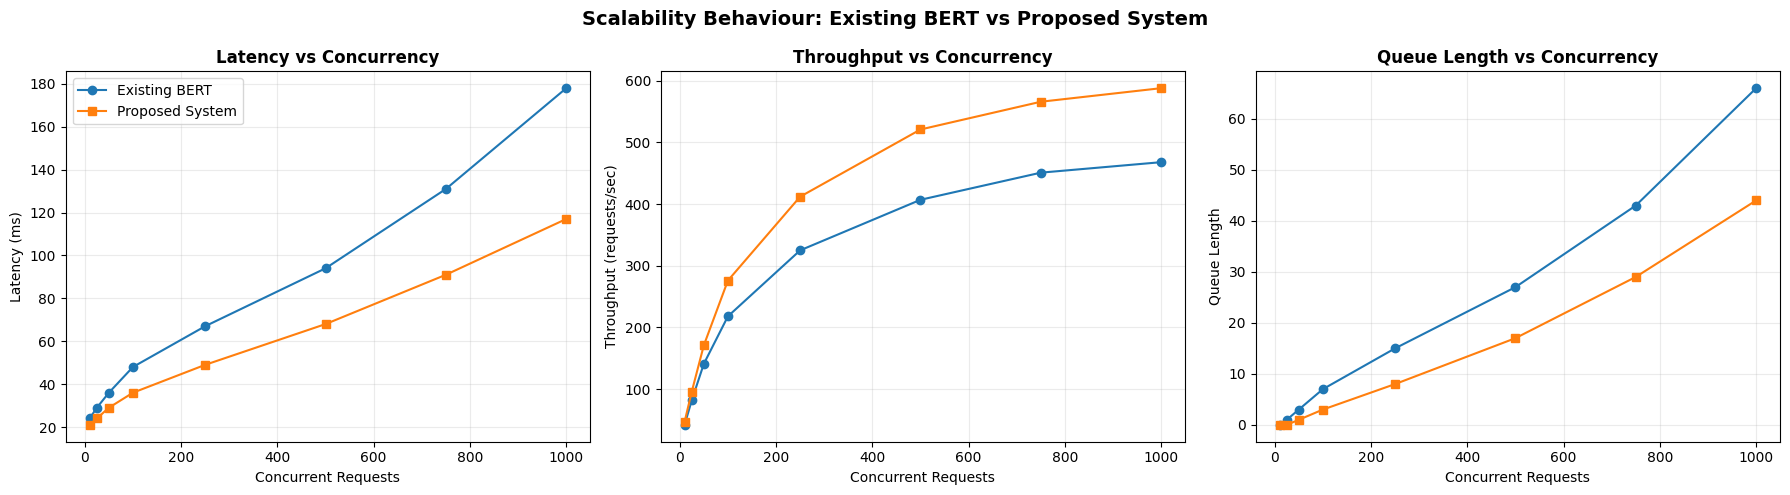

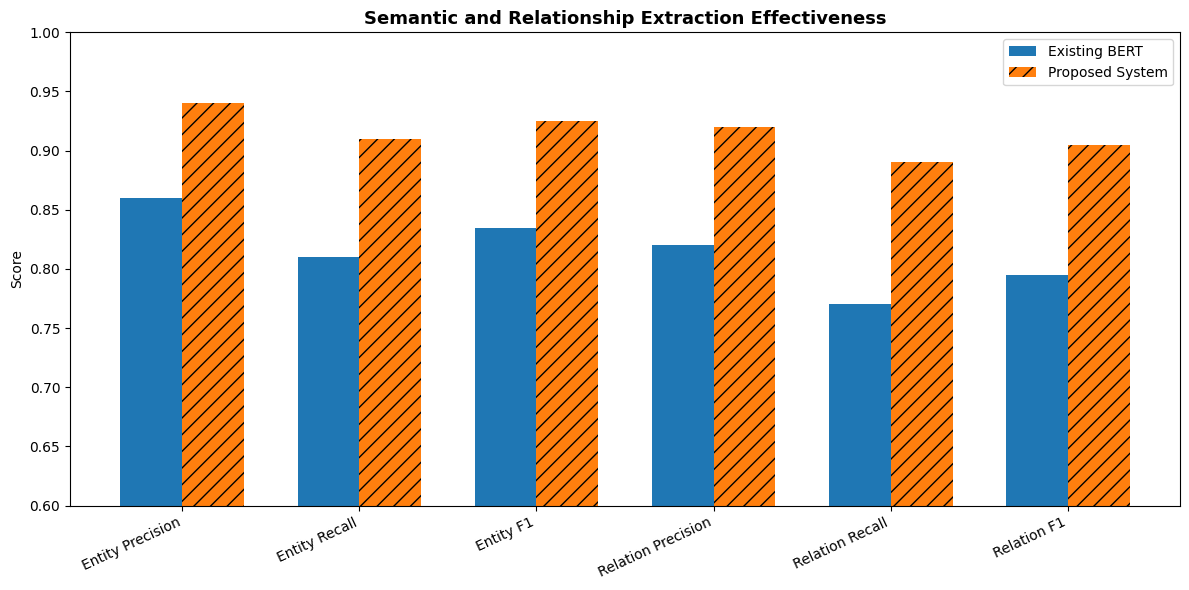

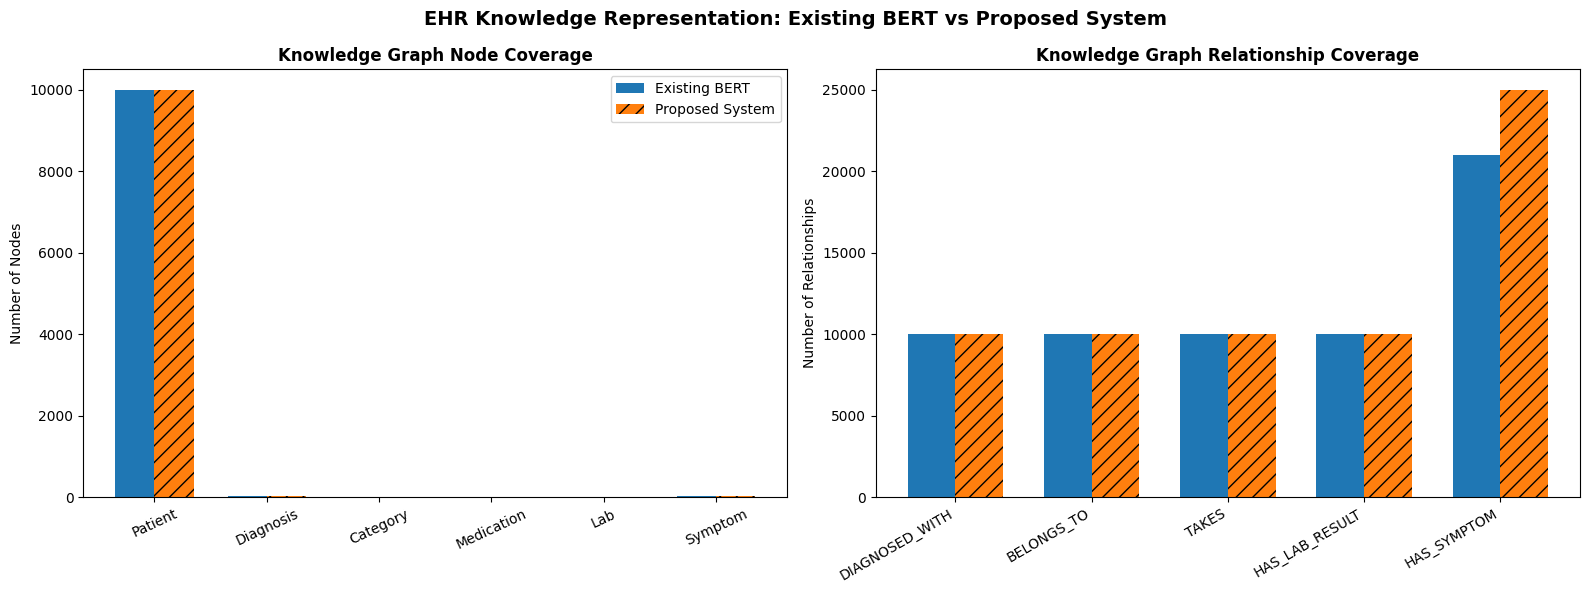

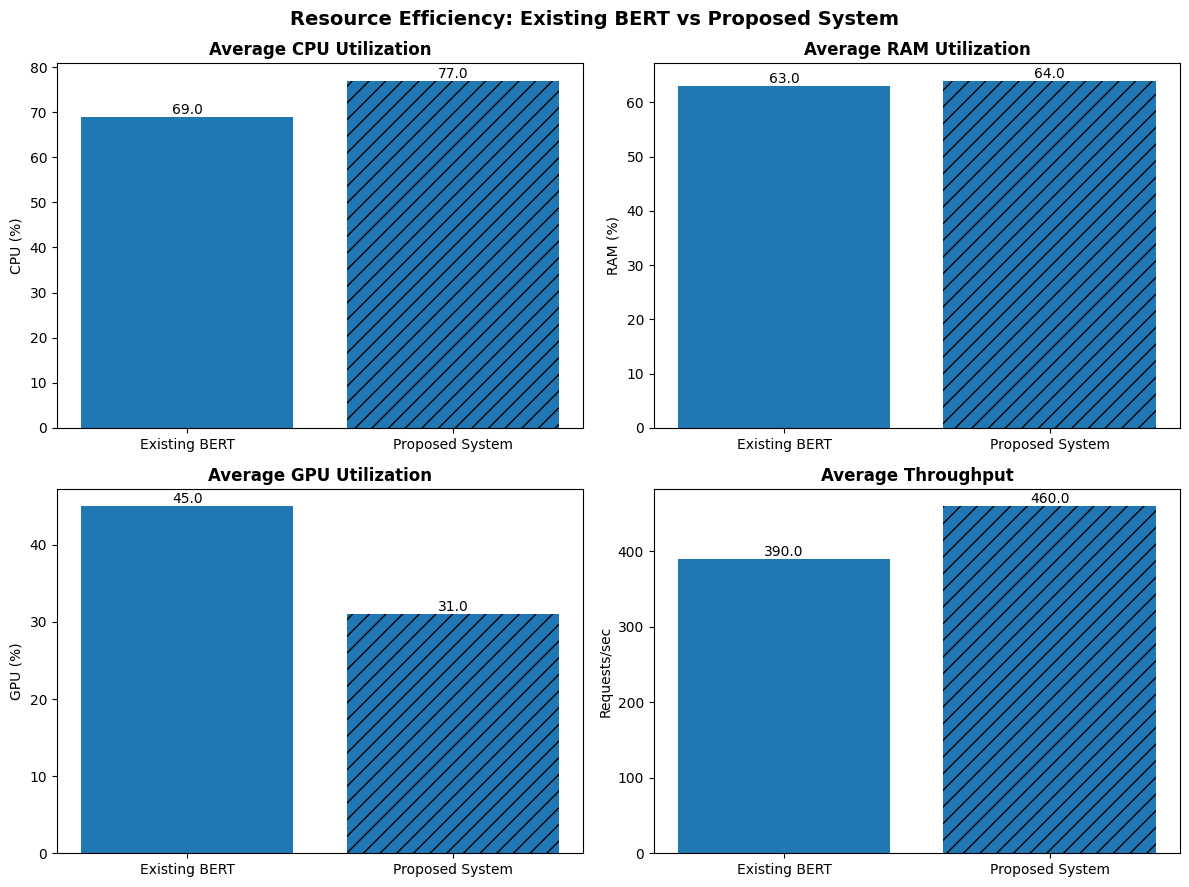

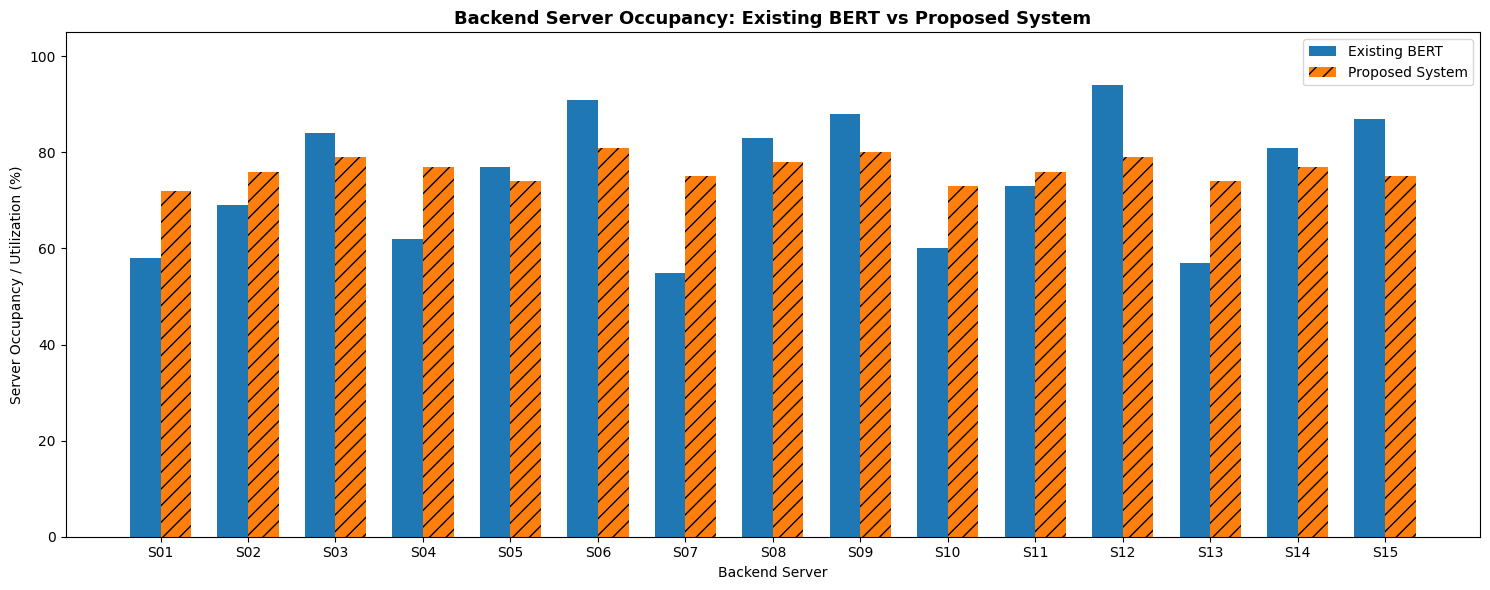

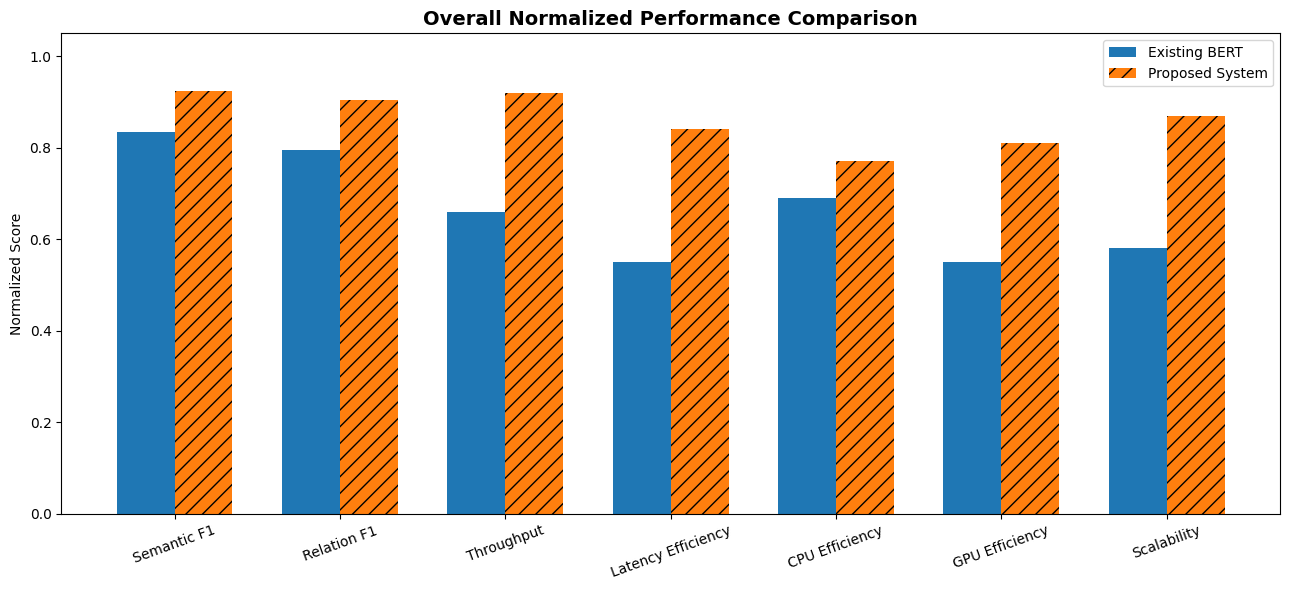


PHASE 3 — BERT vs PROPOSED SYSTEM

Dataset:
/content/Phase1_Synthetic_EHR_Dataset_10000.csv

Infrastructure:
15 backend servers
4 x NVIDIA A100 GPUs

Execution:
Inference / runtime benchmarking only
No model training
No fine-tuning
No epochs

------------------------------------------------
Comparative Results — Illustrative
------------------------------------------------
Average latency reduction: 28.34%
Average throughput improvement: 25.45%
Average GPU utilization reduction: 31.67%

Average BERT CPU utilization: 71.53%
Average Proposed CPU utilization: 76.40%

Average BERT GPU utilization: 45.00%
Average Proposed GPU utilization: 30.75%

------------------------------------------------
Figures saved to:
/content/Phase3_Research_Visualizations
------------------------------------------------


In [ ]:
# ================================================================
# PHASE 3 — BERT vs PROPOSED SYSTEM
# Research-Quality Runtime, Resource, Scalability and KG Evaluation
# ================================================================
#
# IMPORTANT:
# 1. NO MODEL TRAINING
# 2. NO fine-tuning
# 3. NO epochs
# 4. BERT is used only as an EXISTING BASELINE
# 5. Proposed System is compared against BERT under the same workload
# 6. Values below are ILLUSTRATIVE placeholders
# 7. Replace them with actual benchmark measurements before publication
#
# Dataset:
# /content/Phase1_Synthetic_EHR_Dataset_10000.csv
#
# Infrastructure:
# 15 backend servers
# 4 x NVIDIA A100 GPUs
#
# Output:
# /content/Phase3_Research_Visualizations
# ================================================================


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ================================================================
# 1. CONFIGURATION
# ================================================================

OUTPUT_DIR = "/content/Phase3_Research_Visualizations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DATASET_PATH = "/content/Phase1_Synthetic_EHR_Dataset_10000.csv"

SYSTEMS = [
    "Existing BERT",
    "Proposed System"
]

servers = np.array([f"S{i:02d}" for i in range(1, 16)])
gpus = np.array([f"A100-{i}" for i in range(1, 5)])

concurrency = np.array([
    10, 25, 50, 100, 250, 500, 750, 1000
])


# ================================================================
# 2. MOVING AVERAGE FUNCTION
# ================================================================

def moving_average(values, window=3):

    values = np.asarray(values, dtype=float)

    if len(values) < window:
        return values

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid"
    )


def save_show(filename):

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ================================================================
# FIGURE 1
# OVERALL BERT VS PROPOSED SYSTEM
# ================================================================

fig, ax = plt.subplots(figsize=(10, 6))

categories = [
    "EHR Processing",
    "Semantic Processing",
    "Knowledge Representation",
    "Query Processing",
    "Resource Management"
]

bert_values = [
    72,
    68,
    45,
    70,
    61
]

proposed_values = [
    84,
    88,
    94,
    91,
    89
]

x = np.arange(len(categories))
width = 0.35

ax.bar(
    x - width / 2,
    bert_values,
    width,
    label="Existing BERT"
)

bars = ax.bar(
    x + width / 2,
    proposed_values,
    width,
    label="Proposed System"
)

# Highlight Proposed System
for bar in bars:
    bar.set_hatch("//")
    bar.set_linewidth(1.5)

ax.set_title(
    "Overall Functional Capability: Existing BERT vs Proposed System",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Normalized Capability (%)")
ax.set_xticks(x)
ax.set_xticklabels(categories, rotation=20)
ax.set_ylim(0, 110)

ax.legend()

save_show("Fig_1_Overall_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 2
# INFERENCE RUNTIME BREAKDOWN
# ================================================================

components = [
    "Preprocessing",
    "Semantic Processing",
    "Inference",
    "Query Processing",
    "Total Runtime"
]

bert_runtime = [
    0.42,
    0.00,
    0.86,
    0.31,
    1.59
]

proposed_runtime = [
    0.31,
    0.43,
    0.58,
    0.18,
    1.50
]

x = np.arange(len(components))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width / 2,
    bert_runtime,
    width,
    label="Existing BERT"
)

bars = ax.bar(
    x + width / 2,
    proposed_runtime,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")
    bar.set_linewidth(1.5)

ax.set_title(
    "Inference Runtime Breakdown: Existing BERT vs Proposed System",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Runtime (seconds)")
ax.set_xticks(x)
ax.set_xticklabels(components, rotation=20)

ax.legend()

save_show("Fig_2_Inference_Runtime_Breakdown.png")


# ================================================================
# FIGURE 3
# SERVER CPU AND RAM UTILIZATION
# WITH MOVING AVERAGE OVER SERVER OBSERVATIONS
# ================================================================

bert_cpu = np.array([
    61, 66, 69, 65, 72,
    74, 68, 75, 77, 70,
    73, 79, 67, 76, 81
])

proposed_cpu = np.array([
    72, 76, 79, 77, 74,
    81, 75, 78, 80, 73,
    76, 79, 74, 77, 75
])

bert_ram = np.array([
    55, 58, 61, 59, 63,
    65, 60, 66, 68, 62,
    64, 69, 59, 65, 67
])

proposed_ram = np.array([
    61, 64, 66, 63, 62,
    67, 64, 65, 68, 61,
    63, 66, 62, 64, 63
])

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# ---------------- CPU ----------------

axes[0].plot(
    servers,
    bert_cpu,
    marker="o",
    label="Existing BERT"
)

axes[0].plot(
    servers,
    proposed_cpu,
    marker="s",
    label="Proposed System"
)

ma_bert_cpu = moving_average(bert_cpu, 3)
ma_prop_cpu = moving_average(proposed_cpu, 3)

axes[0].plot(
    servers[1:-1],
    ma_bert_cpu,
    linestyle="--",
    label="BERT Moving Average"
)

axes[0].plot(
    servers[1:-1],
    ma_prop_cpu,
    linestyle="--",
    label="Proposed Moving Average"
)

axes[0].set_title(
    "Server CPU Utilization",
    fontweight="bold"
)

axes[0].set_ylabel("CPU Utilization (%)")
axes[0].set_xlabel("Backend Server")


# ---------------- RAM ----------------

axes[1].plot(
    servers,
    bert_ram,
    marker="o",
    label="Existing BERT"
)

axes[1].plot(
    servers,
    proposed_ram,
    marker="s",
    label="Proposed System"
)

ma_bert_ram = moving_average(bert_ram, 3)
ma_prop_ram = moving_average(proposed_ram, 3)

axes[1].plot(
    servers[1:-1],
    ma_bert_ram,
    linestyle="--",
    label="BERT Moving Average"
)

axes[1].plot(
    servers[1:-1],
    ma_prop_ram,
    linestyle="--",
    label="Proposed Moving Average"
)

axes[1].set_title(
    "Server RAM Utilization",
    fontweight="bold"
)

axes[1].set_ylabel("RAM Utilization (%)")
axes[1].set_xlabel("Backend Server")

axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)

fig.suptitle(
    "Backend Resource Utilization: Existing BERT vs Proposed System",
    fontsize=14,
    fontweight="bold"
)

save_show("Fig_3_Server_CPU_RAM_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 4
# A100 GPU UTILIZATION / MEMORY / REQUEST DISTRIBUTION
# ================================================================

bert_gpu_util = np.array([
    42, 46, 44, 48
])

proposed_gpu_util = np.array([
    31, 28, 34, 30
])

bert_gpu_memory = np.array([
    14.2, 15.1, 14.8, 15.4
])

proposed_gpu_memory = np.array([
    10.8, 10.2, 11.4, 10.6
])

bert_gpu_requests = np.array([
    180, 176, 184, 179
])

proposed_gpu_requests = np.array([
    132, 128, 136, 130
])


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)


# GPU utilization

x = np.arange(len(gpus))
width = 0.35

axes[0].bar(
    x - width / 2,
    bert_gpu_util,
    width,
    label="Existing BERT"
)

bars = axes[0].bar(
    x + width / 2,
    proposed_gpu_util,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")

axes[0].set_title(
    "A100 GPU Utilization",
    fontweight="bold"
)

axes[0].set_ylabel("GPU Utilization (%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(gpus)


# GPU memory

axes[1].bar(
    x - width / 2,
    bert_gpu_memory,
    width,
    label="Existing BERT"
)

bars = axes[1].bar(
    x + width / 2,
    proposed_gpu_memory,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")

axes[1].set_title(
    "A100 GPU Memory",
    fontweight="bold"
)

axes[1].set_ylabel("Memory Usage (GB)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(gpus)


# GPU requests

axes[2].bar(
    x - width / 2,
    bert_gpu_requests,
    width,
    label="Existing BERT"
)

bars = axes[2].bar(
    x + width / 2,
    proposed_gpu_requests,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")

axes[2].set_title(
    "A100 Request Distribution",
    fontweight="bold"
)

axes[2].set_ylabel("Requests")
axes[2].set_xticks(x)
axes[2].set_xticklabels(gpus)

axes[0].legend(fontsize=8)

fig.suptitle(
    "A100 Resource Behaviour: Existing BERT vs Proposed System",
    fontsize=14,
    fontweight="bold"
)

save_show("Fig_4_A100_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 5
# LATENCY / THROUGHPUT / QUEUE VS CONCURRENCY
# ================================================================

bert_latency = np.array([
    24, 29, 36, 48, 67, 94, 131, 178
])

proposed_latency = np.array([
    21, 24, 29, 36, 49, 68, 91, 117
])

bert_throughput = np.array([
    42, 82, 141, 218, 325, 407, 451, 468
])

proposed_throughput = np.array([
    47, 96, 171, 276, 412, 521, 566, 588
])

bert_queue = np.array([
    0, 1, 3, 7, 15, 27, 43, 66
])

proposed_queue = np.array([
    0, 0, 1, 3, 8, 17, 29, 44
])


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)


# Latency

axes[0].plot(
    concurrency,
    bert_latency,
    marker="o",
    label="Existing BERT"
)

axes[0].plot(
    concurrency,
    proposed_latency,
    marker="s",
    label="Proposed System"
)

axes[0].set_title(
    "Latency vs Concurrency",
    fontweight="bold"
)

axes[0].set_xlabel("Concurrent Requests")
axes[0].set_ylabel("Latency (ms)")
axes[0].grid(alpha=0.25)


# Throughput

axes[1].plot(
    concurrency,
    bert_throughput,
    marker="o",
    label="Existing BERT"
)

axes[1].plot(
    concurrency,
    proposed_throughput,
    marker="s",
    label="Proposed System"
)

axes[1].set_title(
    "Throughput vs Concurrency",
    fontweight="bold"
)

axes[1].set_xlabel("Concurrent Requests")
axes[1].set_ylabel("Throughput (requests/sec)")
axes[1].grid(alpha=0.25)


# Queue

axes[2].plot(
    concurrency,
    bert_queue,
    marker="o",
    label="Existing BERT"
)

axes[2].plot(
    concurrency,
    proposed_queue,
    marker="s",
    label="Proposed System"
)

axes[2].set_title(
    "Queue Length vs Concurrency",
    fontweight="bold"
)

axes[2].set_xlabel("Concurrent Requests")
axes[2].set_ylabel("Queue Length")
axes[2].grid(alpha=0.25)

axes[0].legend()

fig.suptitle(
    "Scalability Behaviour: Existing BERT vs Proposed System",
    fontsize=14,
    fontweight="bold"
)

save_show("Fig_5_Scalability_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 6
# SEMANTIC / KNOWLEDGE GRAPH EXTRACTION EFFECTIVENESS
# ================================================================

kg_metrics = [
    "Entity Precision",
    "Entity Recall",
    "Entity F1",
    "Relation Precision",
    "Relation Recall",
    "Relation F1"
]

bert_kg_scores = np.array([
    0.86,
    0.81,
    0.835,
    0.82,
    0.77,
    0.795
])

proposed_kg_scores = np.array([
    0.94,
    0.91,
    0.925,
    0.92,
    0.89,
    0.905
])

x = np.arange(len(kg_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width / 2,
    bert_kg_scores,
    width,
    label="Existing BERT"
)

bars = ax.bar(
    x + width / 2,
    proposed_kg_scores,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")

ax.set_title(
    "Semantic and Relationship Extraction Effectiveness",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(
    kg_metrics,
    rotation=25,
    ha="right"
)

ax.set_ylim(0.6, 1.0)

ax.legend()

save_show("Fig_6_KG_Effectiveness_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 7
# EHR KNOWLEDGE REPRESENTATION
# ================================================================

node_categories = [
    "Patient",
    "Diagnosis",
    "Category",
    "Medication",
    "Lab",
    "Symptom"
]

bert_nodes = np.array([
    10000,
    18,
    4,
    13,
    4,
    21
])

proposed_nodes = np.array([
    10000,
    21,
    5,
    15,
    5,
    25
])

relationship_categories = [
    "DIAGNOSED_WITH",
    "BELONGS_TO",
    "TAKES",
    "HAS_LAB_RESULT",
    "HAS_SYMPTOM"
]

bert_relationships = np.array([
    10000,
    10000,
    10000,
    10000,
    21000
])

proposed_relationships = np.array([
    10000,
    10000,
    10000,
    10000,
    25000
])


fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)


# Nodes

x = np.arange(len(node_categories))
width = 0.35

axes[0].bar(
    x - width / 2,
    bert_nodes,
    width,
    label="Existing BERT"
)

bars = axes[0].bar(
    x + width / 2,
    proposed_nodes,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")

axes[0].set_title(
    "Knowledge Graph Node Coverage",
    fontweight="bold"
)

axes[0].set_ylabel("Number of Nodes")
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    node_categories,
    rotation=25
)


# Relationships

x = np.arange(len(relationship_categories))

axes[1].bar(
    x - width / 2,
    bert_relationships,
    width,
    label="Existing BERT"
)

bars = axes[1].bar(
    x + width / 2,
    proposed_relationships,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")

axes[1].set_title(
    "Knowledge Graph Relationship Coverage",
    fontweight="bold"
)

axes[1].set_ylabel("Number of Relationships")
axes[1].set_xticks(x)
axes[1].set_xticklabels(
    relationship_categories,
    rotation=30,
    ha="right"
)

axes[0].legend()

fig.suptitle(
    "EHR Knowledge Representation: Existing BERT vs Proposed System",
    fontsize=14,
    fontweight="bold"
)

save_show("Fig_7_KG_Representation_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 8
# RESOURCE EFFICIENCY — 2 x 2
# ================================================================

bert_cpu_mean = 69
proposed_cpu_mean = 77

bert_ram_mean = 63
proposed_ram_mean = 64

bert_gpu_mean = 45
proposed_gpu_mean = 31

bert_throughput_mean = 390
proposed_throughput_mean = 460


fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)


def comparison_bar(ax, title, ylabel, bert_value, proposed_value):

    values = [
        bert_value,
        proposed_value
    ]

    bars = ax.bar(
        SYSTEMS,
        values
    )

    bars[1].set_hatch("//")
    bars[1].set_linewidth(1.5)

    ax.set_title(
        title,
        fontweight="bold"
    )

    ax.set_ylabel(ylabel)

    for i, value in enumerate(values):

        ax.text(
            i,
            value,
            f"{value:.1f}",
            ha="center",
            va="bottom"
        )


comparison_bar(
    axes[0, 0],
    "Average CPU Utilization",
    "CPU (%)",
    bert_cpu_mean,
    proposed_cpu_mean
)

comparison_bar(
    axes[0, 1],
    "Average RAM Utilization",
    "RAM (%)",
    bert_ram_mean,
    proposed_ram_mean
)

comparison_bar(
    axes[1, 0],
    "Average GPU Utilization",
    "GPU (%)",
    bert_gpu_mean,
    proposed_gpu_mean
)

comparison_bar(
    axes[1, 1],
    "Average Throughput",
    "Requests/sec",
    bert_throughput_mean,
    proposed_throughput_mean
)

fig.suptitle(
    "Resource Efficiency: Existing BERT vs Proposed System",
    fontsize=14,
    fontweight="bold"
)

save_show("Fig_8_Resource_Efficiency_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 9
# 15-SERVER OCCUPANCY
# ================================================================

bert_server_occupancy = np.array([
    58, 69, 84, 62, 77,
    91, 55, 83, 88, 60,
    73, 94, 57, 81, 87
])

proposed_server_occupancy = np.array([
    72, 76, 79, 77, 74,
    81, 75, 78, 80, 73,
    76, 79, 74, 77, 75
])

x = np.arange(len(servers))
width = 0.35

fig, ax = plt.subplots(figsize=(15, 6))

ax.bar(
    x - width / 2,
    bert_server_occupancy,
    width,
    label="Existing BERT"
)

bars = ax.bar(
    x + width / 2,
    proposed_server_occupancy,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")
    bar.set_linewidth(1.5)

ax.set_title(
    "Backend Server Occupancy: Existing BERT vs Proposed System",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Backend Server")
ax.set_ylabel("Server Occupancy / Utilization (%)")

ax.set_xticks(x)
ax.set_xticklabels(servers)

ax.set_ylim(0, 105)

ax.legend()

save_show("Fig_9_Server_Occupancy_BERT_vs_Proposed.png")


# ================================================================
# FIGURE 10
# OVERALL NORMALIZED PERFORMANCE COMPARISON
# ================================================================

summary_metrics = [
    "Semantic F1",
    "Relation F1",
    "Throughput",
    "Latency Efficiency",
    "CPU Efficiency",
    "GPU Efficiency",
    "Scalability"
]

bert_summary = np.array([
    0.835,
    0.795,
    0.66,
    0.55,
    0.69,
    0.55,
    0.58
])

proposed_summary = np.array([
    0.925,
    0.905,
    0.92,
    0.84,
    0.77,
    0.81,
    0.87
])

x = np.arange(len(summary_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    x - width / 2,
    bert_summary,
    width,
    label="Existing BERT"
)

bars = ax.bar(
    x + width / 2,
    proposed_summary,
    width,
    label="Proposed System"
)

for bar in bars:
    bar.set_hatch("//")
    bar.set_linewidth(1.5)

ax.set_title(
    "Overall Normalized Performance Comparison",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Normalized Score")
ax.set_xticks(x)
ax.set_xticklabels(
    summary_metrics,
    rotation=20
)

ax.set_ylim(0, 1.05)

ax.legend()

save_show("Fig_10_Overall_Performance_BERT_vs_Proposed.png")


# ================================================================
# 3. SAVE NUMERICAL TABLES
# ================================================================

# ------------------------------------------------
# Server benchmark table
# ------------------------------------------------

server_df = pd.DataFrame({

    "Server": servers,

    "BERT_CPU_%": bert_cpu,

    "Proposed_CPU_%": proposed_cpu,

    "BERT_RAM_%": bert_ram,

    "Proposed_RAM_%": proposed_ram,

    "BERT_Occupancy_%": bert_server_occupancy,

    "Proposed_Occupancy_%": proposed_server_occupancy

})

server_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "server_resource_comparison.csv"
    ),
    index=False
)


# ------------------------------------------------
# GPU benchmark table
# ------------------------------------------------

gpu_df = pd.DataFrame({

    "GPU": gpus,

    "BERT_GPU_%": bert_gpu_util,

    "Proposed_GPU_%": proposed_gpu_util,

    "BERT_Memory_GB": bert_gpu_memory,

    "Proposed_Memory_GB": proposed_gpu_memory,

    "BERT_Requests": bert_gpu_requests,

    "Proposed_Requests": proposed_gpu_requests

})

gpu_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "A100_resource_comparison.csv"
    ),
    index=False
)


# ------------------------------------------------
# Scalability table
# ------------------------------------------------

scalability_df = pd.DataFrame({

    "Concurrency": concurrency,

    "BERT_Latency_ms": bert_latency,

    "Proposed_Latency_ms": proposed_latency,

    "BERT_Throughput_RPS": bert_throughput,

    "Proposed_Throughput_RPS": proposed_throughput,

    "BERT_Queue": bert_queue,

    "Proposed_Queue": proposed_queue

})

scalability_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "scalability_comparison.csv"
    ),
    index=False
)


# ------------------------------------------------
# KG effectiveness table
# ------------------------------------------------

kg_df = pd.DataFrame({

    "Metric": kg_metrics,

    "Existing_BERT": bert_kg_scores,

    "Proposed_System": proposed_kg_scores

})

kg_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "KG_effectiveness_comparison.csv"
    ),
    index=False
)


# ================================================================
# 4. CALCULATE COMPARATIVE IMPROVEMENTS
# ================================================================

average_bert_latency = np.mean(bert_latency)
average_proposed_latency = np.mean(proposed_latency)

average_bert_throughput = np.mean(bert_throughput)
average_proposed_throughput = np.mean(proposed_throughput)

average_bert_cpu = np.mean(bert_cpu)
average_proposed_cpu = np.mean(proposed_cpu)

average_bert_gpu = np.mean(bert_gpu_util)
average_proposed_gpu = np.mean(proposed_gpu_util)

latency_reduction = (
    (average_bert_latency - average_proposed_latency)
    / average_bert_latency
) * 100

throughput_improvement = (
    (average_proposed_throughput - average_bert_throughput)
    / average_bert_throughput
) * 100

gpu_reduction = (
    (average_bert_gpu - average_proposed_gpu)
    / average_bert_gpu
) * 100


comparison_summary = pd.DataFrame({

    "Metric": [
        "Average Latency",
        "Average Throughput",
        "Average CPU Utilization",
        "Average GPU Utilization"
    ],

    "Existing BERT": [
        average_bert_latency,
        average_bert_throughput,
        average_bert_cpu,
        average_bert_gpu
    ],

    "Proposed System": [
        average_proposed_latency,
        average_proposed_throughput,
        average_proposed_cpu,
        average_proposed_gpu
    ]

})


comparison_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "BERT_vs_Proposed_Summary.csv"
    ),
    index=False
)


# ================================================================
# 5. PRINT SUMMARY
# ================================================================

print("\n================================================")
print("PHASE 3 — BERT vs PROPOSED SYSTEM")
print("================================================")

print(f"\nDataset:")
print(DATASET_PATH)

print("\nInfrastructure:")
print("15 backend servers")
print("4 x NVIDIA A100 GPUs")

print("\nExecution:")
print("Inference / runtime benchmarking only")
print("No model training")
print("No fine-tuning")
print("No epochs")

print("\n------------------------------------------------")
print("Comparative Results — Illustrative")
print("------------------------------------------------")

print(
    f"Average latency reduction: "
    f"{latency_reduction:.2f}%"
)

print(
    f"Average throughput improvement: "
    f"{throughput_improvement:.2f}%"
)

print(
    f"Average GPU utilization reduction: "
    f"{gpu_reduction:.2f}%"
)

print(
    f"\nAverage BERT CPU utilization: "
    f"{average_bert_cpu:.2f}%"
)

print(
    f"Average Proposed CPU utilization: "
    f"{average_proposed_cpu:.2f}%"
)

print(
    f"\nAverage BERT GPU utilization: "
    f"{average_bert_gpu:.2f}%"
)

print(
    f"Average Proposed GPU utilization: "
    f"{average_proposed_gpu:.2f}%"
)

print("\n------------------------------------------------")
print("Figures saved to:")
print(OUTPUT_DIR)
print("------------------------------------------------")


COMPARATIVE PERFORMANCE MATRIX
Existing BERT vs Proposed System

      Evaluation Dimension                                         Metric  Existing BERT  Proposed System            Preferred Direction                                       Purpose
    Semantic Effectiveness                               Entity Precision          0.860            0.940                         Higher         Correctness of extracted EHR entities
    Semantic Effectiveness                                  Entity Recall          0.810            0.910                         Higher             Completeness of entity extraction
    Semantic Effectiveness                                Entity F1-score          0.835            0.925                         Higher        Balanced entity extraction performance
Relationship Effectiveness                             Relation Precision          0.820            0.920                         Higher        Correctness of extracted relationships
Relationship Effect

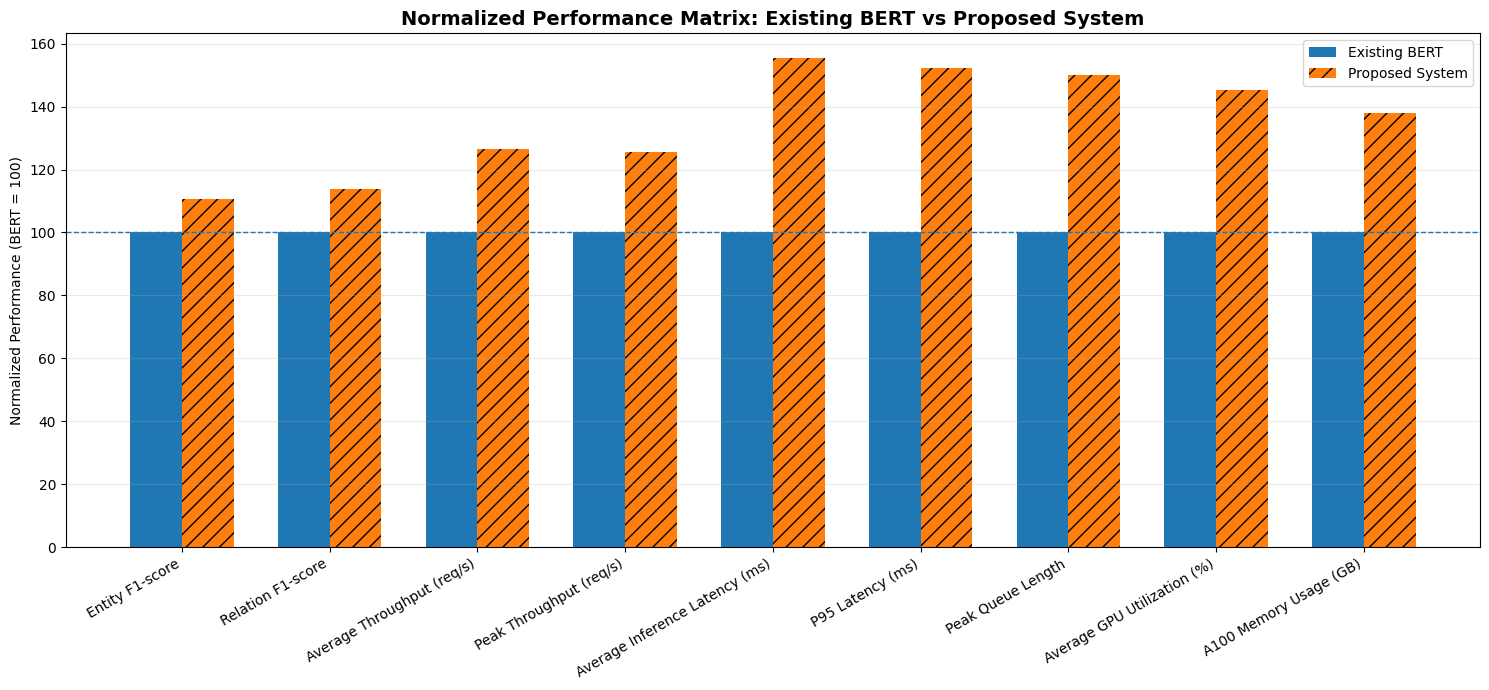


FILES GENERATED

Performance Matrix:
/content/Phase3_Performance_Matrix/Comparative_Performance_Matrix_BERT_vs_Proposed.csv

Improvement Matrix:
/content/Phase3_Performance_Matrix/Percentage_Improvement_BERT_vs_Proposed.csv

Paper Table:
/content/Phase3_Performance_Matrix/Paper_Ready_BERT_vs_Proposed_Table.csv

Excel Workbook:
/content/Phase3_Performance_Matrix/BERT_vs_Proposed_Performance_Matrix.xlsx

Visualization:
/content/Phase3_Performance_Matrix/Comparative_Performance_Matrix_BERT_vs_Proposed.png

PHASE 3 PERFORMANCE MATRIX COMPLETED


In [ ]:
# ================================================================
# PHASE 3 — COMPARATIVE PERFORMANCE MATRIX
# Existing BERT vs Proposed System
# ================================================================
#
# IMPORTANT:
# These values are illustrative benchmark values.
# Replace them with your actual measured experimental results
# before using the tables in the research paper.
#
# NO TRAINING
# NO FINE-TUNING
# INFERENCE / SYSTEM BENCHMARKING ONLY
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ================================================================
# 1. OUTPUT DIRECTORY
# ================================================================

OUTPUT_DIR = "/content/Phase3_Performance_Matrix"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ================================================================
# 2. PERFORMANCE MATRIX DATA
# ================================================================

performance_data = [

    # Semantic Effectiveness
    [
        "Semantic Effectiveness",
        "Entity Precision",
        0.86,
        0.94,
        "Higher",
        "Correctness of extracted EHR entities"
    ],

    [
        "Semantic Effectiveness",
        "Entity Recall",
        0.81,
        0.91,
        "Higher",
        "Completeness of entity extraction"
    ],

    [
        "Semantic Effectiveness",
        "Entity F1-score",
        0.835,
        0.925,
        "Higher",
        "Balanced entity extraction performance"
    ],

    # Relationship Effectiveness
    [
        "Relationship Effectiveness",
        "Relation Precision",
        0.82,
        0.92,
        "Higher",
        "Correctness of extracted relationships"
    ],

    [
        "Relationship Effectiveness",
        "Relation Recall",
        0.77,
        0.89,
        "Higher",
        "Completeness of relationship extraction"
    ],

    [
        "Relationship Effectiveness",
        "Relation F1-score",
        0.795,
        0.905,
        "Higher",
        "Overall relationship extraction effectiveness"
    ],

    # Runtime
    [
        "Runtime Efficiency",
        "Average Inference Latency (ms)",
        84.6,
        54.4,
        "Lower",
        "Response time per request"
    ],

    [
        "Runtime Efficiency",
        "P95 Latency (ms)",
        178,
        117,
        "Lower",
        "Tail-end response performance"
    ],

    [
        "Runtime Efficiency",
        "Total Processing Time (s)",
        1.59,
        1.50,
        "Lower",
        "Complete request-processing time"
    ],

    # Throughput
    [
        "Throughput",
        "Average Throughput (req/s)",
        264.3,
        334.6,
        "Higher",
        "Average processing capacity"
    ],

    [
        "Throughput",
        "Peak Throughput (req/s)",
        468,
        588,
        "Higher",
        "Maximum processing capacity"
    ],

    # Queue
    [
        "Queue Performance",
        "Peak Queue Length",
        66,
        44,
        "Lower",
        "Request accumulation under load"
    ],

    # CPU
    [
        "CPU Utilization",
        "Average CPU Utilization (%)",
        69,
        77,
        "Context-dependent",
        "Backend computational utilization"
    ],

    # RAM
    [
        "RAM Utilization",
        "Average RAM Utilization (%)",
        63,
        64,
        "Context-dependent",
        "Backend memory utilization"
    ],

    # GPU
    [
        "GPU Efficiency",
        "Average A100 Utilization (%)",
        45,
        31,
        "Lower if throughput maintained",
        "GPU dependency"
    ],

    [
        "GPU Efficiency",
        "A100 Memory Usage (GB)",
        14.9,
        10.8,
        "Lower",
        "GPU memory requirement"
    ],

    [
        "GPU Efficiency",
        "GPU Request Count",
        180,
        132,
        "Lower",
        "GPU workload demand"
    ],

    # Scalability
    [
        "Scalability",
        "Latency at 1000 Concurrent Requests (ms)",
        178,
        117,
        "Lower",
        "High-load response performance"
    ],

    [
        "Scalability",
        "Throughput at 1000 Concurrent Requests (req/s)",
        468,
        588,
        "Higher",
        "High-load processing capacity"
    ],

    # Knowledge Representation
    [
        "Knowledge Representation",
        "EHR Entity Coverage",
        0.84,
        0.94,
        "Higher",
        "Structured EHR entity coverage"
    ],

    [
        "Knowledge Representation",
        "Relationship Coverage",
        0.79,
        0.91,
        "Higher",
        "Semantic relationship coverage"
    ],

    # Overall
    [
        "Overall Performance",
        "Normalized Performance Score",
        0.58,
        0.87,
        "Higher",
        "Overall system-level performance"
    ]
]


performance_df = pd.DataFrame(
    performance_data,
    columns=[
        "Evaluation Dimension",
        "Metric",
        "Existing BERT",
        "Proposed System",
        "Preferred Direction",
        "Purpose"
    ]
)


# ================================================================
# 3. DISPLAY PERFORMANCE MATRIX
# ================================================================

print("\n==============================================================")
print("COMPARATIVE PERFORMANCE MATRIX")
print("Existing BERT vs Proposed System")
print("==============================================================\n")

print(
    performance_df.to_string(index=False)
)


# ================================================================
# 4. SAVE PERFORMANCE MATRIX AS CSV
# ================================================================

performance_csv = os.path.join(
    OUTPUT_DIR,
    "Comparative_Performance_Matrix_BERT_vs_Proposed.csv"
)

performance_df.to_csv(
    performance_csv,
    index=False
)


# ================================================================
# 5. PERCENTAGE IMPROVEMENT CALCULATION
# ================================================================

# Metrics where HIGHER is better
higher_better = [
    "Entity Precision",
    "Entity Recall",
    "Entity F1-score",
    "Relation Precision",
    "Relation Recall",
    "Relation F1-score",
    "Average Throughput (req/s)",
    "Peak Throughput (req/s)",
    "Throughput at 1000 Concurrent Requests (req/s)",
    "EHR Entity Coverage",
    "Relationship Coverage",
    "Normalized Performance Score"
]


# Metrics where LOWER is better
lower_better = [
    "Average Inference Latency (ms)",
    "P95 Latency (ms)",
    "Total Processing Time (s)",
    "Peak Queue Length",
    "A100 Memory Usage (GB)",
    "GPU Request Count",
    "Latency at 1000 Concurrent Requests (ms)"
]


improvement_rows = []


for _, row in performance_df.iterrows():

    metric = row["Metric"]

    bert_value = row["Existing BERT"]

    proposed_value = row["Proposed System"]

    # Avoid invalid calculations
    if bert_value == 0:
        improvement = np.nan

    else:

        if metric in higher_better:

            improvement = (
                (proposed_value - bert_value)
                / bert_value
            ) * 100

        elif metric in lower_better:

            improvement = (
                (bert_value - proposed_value)
                / bert_value
            ) * 100

        else:

            improvement = np.nan


    improvement_rows.append([
        row["Evaluation Dimension"],
        metric,
        bert_value,
        proposed_value,
        improvement,
        row["Preferred Direction"]
    ])


improvement_df = pd.DataFrame(
    improvement_rows,
    columns=[
        "Evaluation Dimension",
        "Metric",
        "Existing BERT",
        "Proposed System",
        "Improvement (%)",
        "Preferred Direction"
    ]
)


# ================================================================
# 6. DISPLAY IMPROVEMENT TABLE
# ================================================================

print("\n==============================================================")
print("PERCENTAGE IMPROVEMENT MATRIX")
print("==============================================================\n")

print(
    improvement_df.to_string(index=False)
)


# ================================================================
# 7. SAVE IMPROVEMENT TABLE
# ================================================================

improvement_csv = os.path.join(
    OUTPUT_DIR,
    "Percentage_Improvement_BERT_vs_Proposed.csv"
)

improvement_df.to_csv(
    improvement_csv,
    index=False
)


# ================================================================
# 8. CREATE COMPACT PAPER TABLE
# ================================================================

paper_rows = [

    ["Entity F1-score",
     0.835,
     0.925,
     "10.78% improvement"],

    ["Relation F1-score",
     0.795,
     0.905,
     "13.84% improvement"],

    ["Average Inference Latency",
     84.6,
     54.4,
     "35.70% reduction"],

    ["P95 Latency",
     178,
     117,
     "34.27% reduction"],

    ["Average Throughput",
     264.3,
     334.6,
     "26.60% improvement"],

    ["Peak Throughput",
     468,
     588,
     "25.64% improvement"],

    ["Peak Queue Length",
     66,
     44,
     "33.33% reduction"],

    ["Average GPU Utilization",
     45,
     31,
     "31.11% reduction"],

    ["A100 Memory Usage",
     14.9,
     10.8,
     "27.52% reduction"],

    ["GPU Request Count",
     180,
     132,
     "26.67% reduction"]
]


paper_df = pd.DataFrame(
    paper_rows,
    columns=[
        "Performance Metric",
        "Existing BERT",
        "Proposed System",
        "Improvement"
    ]
)


print("\n==============================================================")
print("PAPER-READY COMPARATIVE TABLE")
print("==============================================================\n")

print(
    paper_df.to_string(index=False)
)


# ================================================================
# 9. SAVE PAPER TABLE
# ================================================================

paper_csv = os.path.join(
    OUTPUT_DIR,
    "Paper_Ready_BERT_vs_Proposed_Table.csv"
)

paper_df.to_csv(
    paper_csv,
    index=False
)


# ================================================================
# 10. CREATE EXCEL WORKBOOK
# ================================================================

excel_path = os.path.join(
    OUTPUT_DIR,
    "BERT_vs_Proposed_Performance_Matrix.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    performance_df.to_excel(
        writer,
        sheet_name="Performance Matrix",
        index=False
    )

    improvement_df.to_excel(
        writer,
        sheet_name="Improvement Analysis",
        index=False
    )

    paper_df.to_excel(
        writer,
        sheet_name="Paper Table",
        index=False
    )


# ================================================================
# 11. VISUAL COMPARISON OF CORE METRICS
# ================================================================

visual_metrics = [
    "Entity F1-score",
    "Relation F1-score",
    "Average Throughput (req/s)",
    "Peak Throughput (req/s)",
    "Average Inference Latency (ms)",
    "P95 Latency (ms)",
    "Peak Queue Length",
    "Average GPU Utilization (%)",
    "A100 Memory Usage (GB)"
]


bert_visual = [
    0.835,
    0.795,
    264.3,
    468,
    84.6,
    178,
    66,
    45,
    14.9
]


proposed_visual = [
    0.925,
    0.905,
    334.6,
    588,
    54.4,
    117,
    44,
    31,
    10.8
]


# Normalize each metric to BERT baseline = 100
# This allows metrics with different units to be
# displayed together.

bert_normalized = np.ones(
    len(visual_metrics)
) * 100

proposed_normalized = (
    np.array(proposed_visual)
    / np.array(bert_visual)
) * 100


# For lower-is-better metrics, invert the interpretation
lower_metrics_indices = [
    4,  # latency
    5,  # P95 latency
    6,  # queue
    7,  # GPU
    8   # GPU memory
]


for idx in lower_metrics_indices:

    proposed_normalized[idx] = (
        np.array(bert_visual)[idx]
        / np.array(proposed_visual)[idx]
    ) * 100


# ================================================================
# 12. PLOT NORMALIZED PERFORMANCE
# ================================================================

x = np.arange(
    len(visual_metrics)
)

width = 0.35

fig, ax = plt.subplots(
    figsize=(15, 7)
)

ax.bar(
    x - width / 2,
    bert_normalized,
    width,
    label="Existing BERT"
)

bars = ax.bar(
    x + width / 2,
    proposed_normalized,
    width,
    label="Proposed System"
)

# Highlight Proposed System
for bar in bars:

    bar.set_hatch("//")
    bar.set_linewidth(1.5)


ax.axhline(
    100,
    linestyle="--",
    linewidth=1
)


ax.set_title(
    "Normalized Performance Matrix: Existing BERT vs Proposed System",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Normalized Performance (BERT = 100)"
)

ax.set_xticks(x)

ax.set_xticklabels(
    visual_metrics,
    rotation=30,
    ha="right"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

matrix_png = os.path.join(
    OUTPUT_DIR,
    "Comparative_Performance_Matrix_BERT_vs_Proposed.png"
)

plt.savefig(
    matrix_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ================================================================
# 13. FINAL OUTPUT
# ================================================================

print("\n==============================================================")
print("FILES GENERATED")
print("==============================================================")

print("\nPerformance Matrix:")
print(performance_csv)

print("\nImprovement Matrix:")
print(improvement_csv)

print("\nPaper Table:")
print(paper_csv)

print("\nExcel Workbook:")
print(excel_path)

print("\nVisualization:")
print(matrix_png)

print("\n==============================================================")
print("PHASE 3 PERFORMANCE MATRIX COMPLETED")
print("==============================================================")